<a href="https://colab.research.google.com/github/mdzameer-tech/test/blob/main/solar%20power%20prediction%20ML%20models.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Phase 1: Setup and locations

Cell 1: setup and cleanup of old files

In [ ]:
!pip install geopandas shapely pvlib xgboost lightgbm pyarrow folium requests --quiet

import os, shutil, time, requests, zipfile
import numpy as np
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point
import folium
from google.colab import drive

drive.mount('/content/drive')

output_dir = '/content/drive/My Drive/solar_forecasting_project'

# Start fresh: remove everything from the earlier attempts
shutil.rmtree(output_dir, ignore_errors=True)
os.makedirs(output_dir, exist_ok=True)
print("Clean workspace ready at:", output_dir)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Clean workspace ready at: /content/drive/My Drive/solar_forecasting_project


Cell 2: Karnataka boundary, grid points, elevation, map

In [ ]:
# 1. Karnataka boundary from Natural Earth (admin-1 states)
zip_url = "https://naciscdn.org/naturalearth/10m/cultural/ne_10m_admin_1_states_provinces.zip"
zip_path = "/content/ne_admin1.zip"
r = requests.get(zip_url, timeout=120)
r.raise_for_status()
with open(zip_path, "wb") as f:
    f.write(r.content)

states = gpd.read_file(f"zip://{zip_path}")
karnataka = states[(states["admin"] == "India") & (states["name"] == "Karnataka")]
assert len(karnataka) == 1, f"Expected 1 Karnataka polygon, found {len(karnataka)}"
karnataka_poly = karnataka.geometry.iloc[0]
print("Boundary loaded. Bounds (minx, miny, maxx, maxy):", karnataka_poly.bounds)

# Save the boundary for later (the web app will use it to check GPS points)
karnataka.to_file(os.path.join(output_dir, "karnataka_boundary.geojson"), driver="GeoJSON")

# 2. Regular grid at ~0.6 degree spacing, keep only points inside Karnataka
SPACING = 0.6
minx, miny, maxx, maxy = karnataka_poly.bounds
lats = np.arange(miny + SPACING/2, maxy, SPACING)
lons = np.arange(minx + SPACING/2, maxx, SPACING)

pts = []
for lat in lats:
    for lon in lons:
        if karnataka_poly.contains(Point(lon, lat)):
            pts.append({"latitude": round(float(lat), 4), "longitude": round(float(lon), 4)})

points_df = pd.DataFrame(pts).reset_index(drop=True)
points_df["cell_id"] = [f"loc_{i:02d}" for i in range(len(points_df))]
print("Number of grid points:", len(points_df))

# 3. Elevation from Open-Meteo (max 100 points per request)
elev = []
for i in range(0, len(points_df), 100):
    chunk = points_df.iloc[i:i+100]
    url = ("https://api.open-meteo.com/v1/elevation"
           f"?latitude={','.join(chunk['latitude'].astype(str))}"
           f"&longitude={','.join(chunk['longitude'].astype(str))}")
    resp = requests.get(url, timeout=30)
    resp.raise_for_status()
    elev += resp.json()["elevation"]
    time.sleep(1)
points_df["elevation"] = elev

# 4. Save
points_df = points_df[["cell_id", "latitude", "longitude", "elevation"]]
points_df.to_parquet(os.path.join(output_dir, "karnataka_locations.parquet"), index=False)
display(points_df)

# 5. Map with the boundary
m = folium.Map(location=[15.0, 76.2], zoom_start=7)
folium.GeoJson(karnataka.__geo_interface__,
               style_function=lambda x: {"fillOpacity": 0.05, "color": "green"}).add_to(m)
for _, row in points_df.iterrows():
    info = f"{row.cell_id} | elev {row.elevation:.0f} m"
    folium.CircleMarker([row.latitude, row.longitude], radius=5, color="blue",
                        fill=True, tooltip=info, popup=info).add_to(m)
m

Boundary loaded. Bounds (minx, miny, maxx, maxy): (74.09115644600007, 11.625595607751109, 78.56898237493664, 18.4608114689741)
Number of grid points: 49


,cell_id,latitude,longitude,elevation
0,loc_00,11.9256,76.1912,726.0
1,loc_01,11.9256,76.7912,755.0
2,loc_02,11.9256,77.3912,566.0
3,loc_03,12.5256,75.5912,624.0
4,loc_04,12.5256,76.1912,820.0
5,loc_05,12.5256,76.7912,771.0
6,loc_06,12.5256,77.3912,667.0
7,loc_07,13.1256,74.9912,109.0
8,loc_08,13.1256,75.5912,913.0
9,loc_09,13.1256,76.1912,974.0


Cell 3: location check

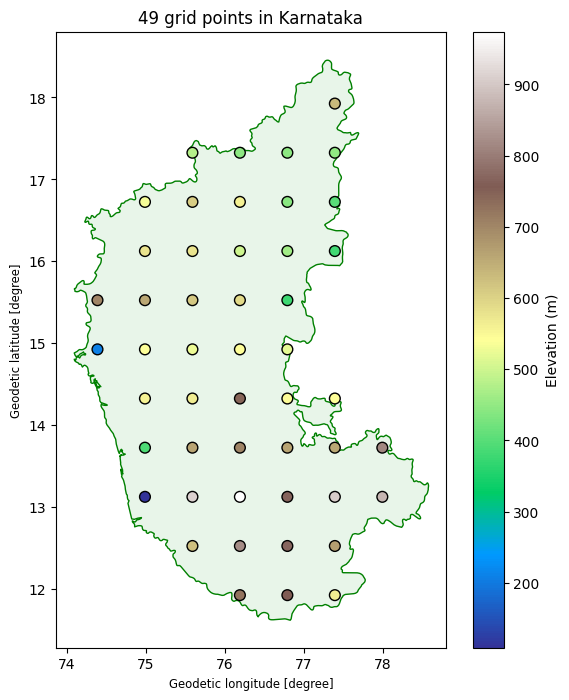

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 8))
karnataka.plot(ax=ax, color="#e8f5e9", edgecolor="green")
sc = ax.scatter(points_df.longitude, points_df.latitude, c=points_df.elevation,
                cmap="terrain", s=60, edgecolor="k")
plt.colorbar(sc, label="Elevation (m)")
ax.set_title(f"{len(points_df)} grid points in Karnataka")
plt.show()

Confirm that every dot sits inside the green outline.

Two things to know

Download time: 49 points means about two days of Open-Meteo quota (at roughly 235 calls per location against about 10,000 per day, as I remember the free tier). The download resumes by itself, so this just means rerunning tomorrow.
Coverage gaps: the coast (Mangaluru, Udupi) and Bengaluru city aren’t sampled directly, and the coast has a very different monsoon climate. Don’t regenerate the grid. If you want those later, we’ll append a few extra points as loc_49, loc_50 and so on, so nothing already downloaded goes stale.

Phase 2: Download 2016 to 2025 (hourly)

Cell 4:

In [ ]:
import os, time, requests
import pandas as pd
from google.colab import drive

drive.mount('/content/drive')
output_dir = '/content/drive/My Drive/solar_forecasting_project'
os.makedirs(output_dir, exist_ok=True)

# --- Bengaluru district: centre + 4 corners (approximate) ---
locations = pd.DataFrame([
    {"cell_id": "blr_center", "latitude": 12.9716, "longitude": 77.5946},
    {"cell_id": "blr_nw",     "latitude": 13.08,   "longitude": 77.45},
    {"cell_id": "blr_ne",     "latitude": 13.08,   "longitude": 77.72},
    {"cell_id": "blr_sw",     "latitude": 12.85,   "longitude": 77.47},
    {"cell_id": "blr_se",     "latitude": 12.85,   "longitude": 77.72},
])
locations.to_parquet(os.path.join(output_dir, "blr_locations.parquet"), index=False)

raw_dir = os.path.join(output_dir, "raw_weather_blr")
os.makedirs(raw_dir, exist_ok=True)

START, END = "2016-01-01", "2025-12-31"
EXPECTED_ROWS = 3653 * 24            # 10 years incl. 3 leap days = 87,672
URL = "https://archive-api.open-meteo.com/v1/archive"
VARS = ["shortwave_radiation", "direct_radiation", "diffuse_radiation",
        "direct_normal_irradiance", "cloud_cover", "temperature_2m",
        "relative_humidity_2m", "wind_speed_10m", "precipitation"]

# --- Quick quota check (1-day request, almost free) ---
chk = requests.get(URL, params={"latitude": 12.97, "longitude": 77.59,
        "start_date": "2025-01-01", "end_date": "2025-01-02",
        "hourly": "temperature_2m"}, timeout=30)
if chk.status_code == 429:
    raise SystemExit(f"Still rate limited: {chk.json().get('reason')}\n"
                     "Wait and rerun this cell. Nothing was downloaded.")
print("Quota check OK. Starting download...")

def is_complete(path):
    try:
        return len(pd.read_parquet(path, columns=["cloud_cover"])) == EXPECTED_ROWS
    except Exception:
        return False

def download_one(row):
    path = os.path.join(raw_dir, f"{row.cell_id}.parquet")
    params = {"latitude": row.latitude, "longitude": row.longitude,
              "start_date": START, "end_date": END,
              "hourly": ",".join(VARS), "timezone": "Asia/Kolkata"}
    for attempt in range(6):
        try:
            time.sleep(1)
            r = requests.get(URL, params=params, timeout=90)
            if r.status_code == 429:
                reason = r.json().get("reason", "")
                print(f"  [{row.cell_id}] 429: {reason}")
                if "inute" in reason:
                    time.sleep(65); continue
                return "rate_limited"      # hourly or daily: stop, don't sleep
            r.raise_for_status()
            df = pd.DataFrame(r.json()["hourly"])
            df["time"] = pd.to_datetime(df["time"])
            df = df.set_index("time")      # radiation kept exactly as downloaded
            if len(df) != EXPECTED_ROWS:
                print(f"  [{row.cell_id}] unexpected row count {len(df)}")
                return "bad_rows"
            tmp = path + ".tmp"
            df.to_parquet(tmp)
            os.replace(tmp, path)
            return "ok"
        except Exception as e:
            print(f"  [{row.cell_id}] attempt {attempt+1} failed: {e}")
            time.sleep(10)
    return "failed"

results = {}
for row in locations.itertuples():
    path = os.path.join(raw_dir, f"{row.cell_id}.parquet")
    if os.path.exists(path) and is_complete(path):
        results[row.cell_id] = "already_done"
        print(f"[{row.cell_id}] already complete, skipping")
        continue
    print(f"[{row.cell_id}] downloading ({row.latitude}, {row.longitude})...")
    results[row.cell_id] = download_one(row)
    print(f"[{row.cell_id}] {results[row.cell_id]}")
    if results[row.cell_id] == "rate_limited":
        print("Rate limit reached. Rerun this cell later; finished files are skipped.")
        break

done = sum(v in ("ok", "already_done") for v in results.values())
print(f"\nComplete: {done} / {len(locations)}")

# --- Which points actually fell in different grid cells? ---
files = {r.cell_id: os.path.join(raw_dir, f"{r.cell_id}.parquet") for r in locations.itertuples()}
series = {k: pd.read_parquet(v, columns=["temperature_2m", "shortwave_radiation"])
          for k, v in files.items() if os.path.exists(v)}
ids = list(series)
for i in range(len(ids)):
    for j in range(i + 1, len(ids)):
        same = series[ids[i]].equals(series[ids[j]])
        print(f"{ids[i]} vs {ids[j]}: {'IDENTICAL (same grid cell)' if same else 'different'}")

Mounted at /content/drive
Quota check OK. Starting download...
[blr_center] downloading (12.9716, 77.5946)...
[blr_center] ok
[blr_nw] downloading (13.08, 77.45)...
[blr_nw] ok
[blr_ne] downloading (13.08, 77.72)...
[blr_ne] ok
[blr_sw] downloading (12.85, 77.47)...
  [blr_sw] 429: Minutely API request limit exceeded. Please try again in one minute.
[blr_sw] ok
[blr_se] downloading (12.85, 77.72)...
[blr_se] ok

Complete: 5 / 5
blr_center vs blr_nw: different
blr_center vs blr_ne: different
blr_center vs blr_sw: different
blr_center vs blr_se: different
blr_nw vs blr_ne: different
blr_nw vs blr_sw: different
blr_nw vs blr_se: different
blr_ne vs blr_sw: different
blr_ne vs blr_se: different
blr_sw vs blr_se: different


Phase 3, part 1: data checks (Cell 5)



In [ ]:
import os, requests
import numpy as np
import pandas as pd

output_dir = '/content/drive/My Drive/solar_forecasting_project'
raw_dir = os.path.join(output_dir, "raw_weather_blr")
locs = pd.read_parquet(os.path.join(output_dir, "blr_locations.parquet"))

# 1. Elevation for each point (one small call), needed later by pvlib
r = requests.get("https://api.open-meteo.com/v1/elevation",
                 params={"latitude": ",".join(locs.latitude.astype(str)),
                         "longitude": ",".join(locs.longitude.astype(str))}, timeout=30)
r.raise_for_status()
locs["elevation"] = r.json()["elevation"]
locs.to_parquet(os.path.join(output_dir, "blr_locations.parquet"), index=False)
print(locs.to_string(index=False))

# 2. Load all files
data = {cid: pd.read_parquet(os.path.join(raw_dir, f"{cid}.parquet")) for cid in locs.cell_id}

# 3. Completeness per location
rows = []
for cid, df in data.items():
    full = pd.date_range(df.index.min(), df.index.max(), freq="h")
    rows.append({"cell_id": cid, "rows": len(df), "start": df.index.min(), "end": df.index.max(),
                 "missing_hours": len(full.difference(df.index)),
                 "duplicate_hours": int(df.index.duplicated().sum()),
                 "nan_cells": int(df.isna().sum().sum())})
print("\n--- Completeness ---")
print(pd.DataFrame(rows).to_string(index=False))

# 4. Value ranges (centre point)
print("\n--- Value ranges (blr_center) ---")
print(data["blr_center"].describe().T[["min", "mean", "max"]].round(1).to_string())

# 5. Timestamp convention check
df = data["blr_center"]
by_hour = df.groupby(df.index.hour).shortwave_radiation.mean()
lit = by_hour[by_hour > 5].index
print("\n--- Radiation by hour of day ---")
print("Hour with highest mean radiation:", by_hour.idxmax())
print("First / last hour with mean > 5 W/m2:", lit.min(), "/", lit.max())
print("Max radiation at hours 22-03:", df[df.index.hour.isin([22, 23, 0, 1, 2, 3])].shortwave_radiation.max())

# 6. Are the 5 points really different grid cells?
print("\n--- Share of hours with identical values between points ---")
ids = list(data)
for i in range(len(ids)):
    for j in range(i + 1, len(ids)):
        a, b = data[ids[i]], data[ids[j]]
        same_rad = np.isclose(a.shortwave_radiation, b.shortwave_radiation).mean()
        same_cloud = (a.cloud_cover == b.cloud_cover).mean()
        print(f"{ids[i]} vs {ids[j]}: radiation {same_rad:.2f} | cloud cover {same_cloud:.2f}")

   cell_id  latitude  longitude  elevation
blr_center   12.9716    77.5946      910.0
    blr_nw   13.0800    77.4500      869.0
    blr_ne   13.0800    77.7200      882.0
    blr_sw   12.8500    77.4700      761.0
    blr_se   12.8500    77.7200      885.0

--- Completeness ---
   cell_id  rows      start                 end  missing_hours  duplicate_hours  nan_cells
blr_center 87672 2016-01-01 2025-12-31 23:00:00              0                0          0
    blr_nw 87672 2016-01-01 2025-12-31 23:00:00              0                0          0
    blr_ne 87672 2016-01-01 2025-12-31 23:00:00              0                0          0
    blr_sw 87672 2016-01-01 2025-12-31 23:00:00              0                0          0
    blr_se 87672 2016-01-01 2025-12-31 23:00:00              0                0          0

--- Value ranges (blr_center) ---
                           min   mean     max
shortwave_radiation        0.0  224.9  1057.0
direct_radiation           0.0  148.7   918.0
d

All checks pass.

-Each file has 87,672 rows (10 years hourly), with no gaps, duplicates or NaNs.



-The value ranges are realistic: radiation up to 1,057 W/m², temperature 11.5 to 39.5 °C, cloud cover 0 to 100%.


-The radiation timing is as expected. Mean radiation peaks at hour 12, the first and last lit hours are 7 and 18, and night values are 0. That confirms Open-Meteo stamps radiation at the end of each hour, so the pvlib step below uses the middle of each hour (timestamp minus 30 minutes).


The “identical” table: the radiation share of about 0.50 is almost exactly the night hours, where every point reads 0 and so matches. Daytime values essentially never match, so the five points carry genuinely different data and none is a duplicate. They’re still strongly correlated, so don’t expect five times the information.

Phase 3, part 2: pvlib power (Cell 6)

This builds the 1 kW reference system’s power for each point and adds the clear-sky index and clear-sky power (used for baselines later).

In [ ]:
!pip install pvlib --quiet

import os
import numpy as np
import pandas as pd
from pvlib.location import Location
from pvlib import irradiance, temperature, pvsystem

output_dir = '/content/drive/My Drive/solar_forecasting_project'
raw_dir  = os.path.join(output_dir, "raw_weather_blr")
proc_dir = os.path.join(output_dir, "processed_blr")
os.makedirs(proc_dir, exist_ok=True)
locs = pd.read_parquet(os.path.join(output_dir, "blr_locations.parquet"))

# --- Reference system: 1 kW, fixed tilt, south-facing ---
TILT, AZIMUTH = 13, 180     # tilt ~ latitude; revisit once your panel's tilt is known
PDC0   = 1000.0             # W DC at 1000 W/m2 and 25 C
GAMMA  = -0.004             # power temperature coefficient (per deg C), crystalline silicon
LOSSES = 0.14               # PVWatts default system losses
ALBEDO = 0.2
T_PARAMS = temperature.TEMPERATURE_MODEL_PARAMETERS["sapm"]["open_rack_glass_glass"]

def power_from_poa(poa, t_air, wind_ms):
    t_cell = temperature.sapm_cell(poa, t_air, wind_ms, **T_PARAMS)
    pdc = pvsystem.pvwatts_dc(poa, t_cell, PDC0, GAMMA)
    return t_cell, np.clip(pdc * (1 - LOSSES), 0, None)

processed = {}
for r in locs.itertuples():
    df = pd.read_parquet(os.path.join(raw_dir, f"{r.cell_id}.parquet"))
    idx = df.index.tz_localize("Asia/Kolkata")
    mid = idx - pd.Timedelta(minutes=30)          # radiation = mean of the preceding hour
    site = Location(r.latitude, r.longitude, tz="Asia/Kolkata", altitude=r.elevation)

    sp = site.get_solarposition(mid)
    try:
        cs = site.get_clearsky(mid, model="ineichen")
    except Exception as e:
        print("Linke turbidity lookup failed, using constant 3.5:", e)
        cs = site.get_clearsky(mid, model="ineichen", linke_turbidity=3.5)
    dni_extra = irradiance.get_extra_radiation(mid)

    S = lambda col: pd.Series(df[col].values, index=mid)

    def poa(dni, ghi, dhi):
        return irradiance.get_total_irradiance(
            TILT, AZIMUTH, sp["apparent_zenith"], sp["azimuth"],
            dni, ghi, dhi, dni_extra=dni_extra, albedo=ALBEDO, model="haydavies"
        )["poa_global"].clip(lower=0)

    wind_ms = S("wind_speed_10m") / 3.6           # Open-Meteo gives km/h
    poa_real = poa(S("direct_normal_irradiance"), S("shortwave_radiation"), S("diffuse_radiation"))
    t_cell, p_real = power_from_poa(poa_real, S("temperature_2m"), wind_ms)
    poa_cs = poa(cs["dni"], cs["ghi"], cs["dhi"])
    _, p_cs = power_from_poa(poa_cs, S("temperature_2m"), wind_ms)

    csi = (S("shortwave_radiation") / cs["ghi"]).where(sp["apparent_elevation"] > 5).clip(0, 1.2)

    out = df.copy()
    out["solar_elevation"] = sp["apparent_elevation"].values
    out["solar_azimuth"]   = sp["azimuth"].values
    out["clearsky_ghi"]    = cs["ghi"].values
    out["csi"]             = csi.values
    out["poa_global"]      = poa_real.values
    out["temp_cell"]       = t_cell.values
    out["power_w"]         = p_real.values          # W from the 1 kW reference system
    out["power_clear_w"]   = p_cs.values
    out.to_parquet(os.path.join(proc_dir, f"{r.cell_id}.parquet"))
    processed[r.cell_id] = out
    print(f"{r.cell_id}: saved {len(out)} rows")

# --- Sanity checks (blr_center) ---
c = processed["blr_center"]
print("\nkWh per kW per year:")
print((c.groupby(c.index.year).power_w.sum() / 1000).round(0).to_string())

daily = c.power_w.resample("D").sum() / 1000
print("\nMean daily kWh per kW, by month:")
print(daily.groupby(daily.index.month).mean().round(2).to_string())

print("\nMax power_w:", round(c.power_w.max()), "| max power_clear_w:", round(c.power_clear_w.max()))
print("Max clearsky_ghi:", round(c.clearsky_ghi.max()), "| max actual GHI:", c.shortwave_radiation.max())
print("\nClear-sky index (daytime):")
print(c.csi.describe().round(2).to_string())

blr_center: saved 87672 rows
blr_nw: saved 87672 rows
blr_ne: saved 87672 rows
blr_sw: saved 87672 rows
blr_se: saved 87672 rows

kWh per kW per year:
time
2016    1601.0
2017    1532.0
2018    1574.0
2019    1547.0
2020    1556.0
2021    1550.0
2022    1603.0
2023    1691.0
2024    1596.0
2025    1641.0

Mean daily kWh per kW, by month:
time
1     4.89
2     5.45
3     5.22
4     4.87
5     4.24
6     3.78
7     3.42
8     3.69
9     3.95
10    4.26
11    4.16
12    4.35

Max power_w: 821 | max power_clear_w: 830
Max clearsky_ghi: 1046 | max actual GHI: 1057.0

Clear-sky index (daytime):
count    40794.00
mean         0.76
std          0.29
min          0.03
25%          0.52
50%          0.77
75%          0.99
max          1.20


What I expect

-About 1,400 to 1,700 kWh per kW per year, similar across years.

-Daily yield of roughly 4 to 5.5 kWh per kW, with a dip in June to August (monsoon) and highs around February to April.

-Max power_w below about 900 W, and max clear-sky GHI around 1,000 to 1,050.


-Clear-sky index mean around 0.65 to 0.8, ranging from 0 to 1.2.

Phase 3 looks correct.

-The yearly totals (1,532 to 1,691 kWh per kW) sit in the expected range and are stable year to year, with 2023 the highest.

-The monthly pattern is right for Bengaluru: a peak in February (5.45 kWh/kW/day) and a monsoon low in July (3.42).

-The max power of 821 W is just under the clear-sky max of 830 W, and the clear-sky index averages 0.76, as it should.

Phase 4: features, targets and split (Cell 7)

First, a correction to our plan. I said to use next-hour weather, including forecast irradiance, as features. With archive data that’s leakage: the archive’s irradiance for the next hour is the answer, and power is just a conversion of it. The same goes for the day’s irradiance total in the daily model. The model would score almost perfectly by learning the physics, and the score would mean nothing. So I’ve set up two honest feature sets for each model:



- Set A (lags only): past hours or days, clear-sky values, time and location. This is a true nowcast baseline.
- Set B (A plus next-period weather): adds cloud cover, temperature, humidity, wind and rain for the target period, but never irradiance. Archive weather is still better than a real forecast, so B is optimistic. Phase 8 re-tests it on real Open-Meteo forecasts, and that gap goes in the paper.

In [ ]:
import os, json
import numpy as np
import pandas as pd

output_dir = '/content/drive/My Drive/solar_forecasting_project'
proc_dir = os.path.join(output_dir, "processed_blr")
locs = pd.read_parquet(os.path.join(output_dir, "blr_locations.parquet"))

def split_of(year):
    return np.where(year <= 2022, "train", np.where(year == 2023, "val", "test"))

# ---------------- HOURLY ----------------
def build_hourly(r):
    d = pd.read_parquet(os.path.join(proc_dir, f"{r.cell_id}.parquet")).sort_index()
    d["csi_f"] = d["csi"].fillna(0.0)           # low sun / night -> 0
    f = pd.DataFrame(index=d.index)
    for k in range(6):                           # t, t-1, ..., t-5
        f[f"csi_lag{k}"]   = d["csi_f"].shift(k)
        f[f"cloud_lag{k}"] = d["cloud_cover"].shift(k)
        f[f"temp_lag{k}"]  = d["temperature_2m"].shift(k)
        f[f"power_lag{k}"] = d["power_w"].shift(k)
    f["csi_same_hour_yday"]   = d["csi_f"].shift(23)     # same hour as the target, yesterday
    f["power_same_hour_yday"] = d["power_w"].shift(23)
    f["csi_roll24"] = d["csi_f"].rolling(24).mean()

    nxt = d.shift(-1)                             # the hour we predict (t+1)
    tgt_time = d.index + pd.Timedelta(hours=1)
    f["solar_elev_next"]    = nxt["solar_elevation"]
    f["clearsky_ghi_next"]  = nxt["clearsky_ghi"]
    f["power_clear_next"]   = nxt["power_clear_w"]
    f["hour_sin"] = np.sin(2*np.pi*tgt_time.hour/24)
    f["hour_cos"] = np.cos(2*np.pi*tgt_time.hour/24)
    f["doy_sin"]  = np.sin(2*np.pi*tgt_time.dayofyear/365.25)
    f["doy_cos"]  = np.cos(2*np.pi*tgt_time.dayofyear/365.25)
    f["latitude"], f["longitude"], f["elevation"] = r.latitude, r.longitude, r.elevation

    # Set B extras: weather of the target hour (NOT irradiance)
    f["cloud_next"] = nxt["cloud_cover"];        f["temp_next"] = nxt["temperature_2m"]
    f["humidity_next"] = nxt["relative_humidity_2m"]
    f["wind_next"] = nxt["wind_speed_10m"];      f["precip_next"] = nxt["precipitation"]

    f["target_power"] = nxt["power_w"]
    f["cell_id"] = r.cell_id
    f["year"] = d.index.year
    f = f.dropna()
    return f[f["solar_elev_next"] > 0]            # daylight target hours only

hourly = pd.concat([build_hourly(r) for r in locs.itertuples()])
hourly["split"] = split_of(hourly["year"])

meta_h = ["cell_id", "year", "split", "target_power"]
extras_h = ["cloud_next", "temp_next", "humidity_next", "wind_next", "precip_next"]
FEATS_H_B = [c for c in hourly.columns if c not in meta_h]
FEATS_H_A = [c for c in FEATS_H_B if c not in extras_h]
hourly.to_parquet(os.path.join(output_dir, "features_hourly.parquet"))

# ---------------- DAILY ----------------
def build_daily(r):
    d = pd.read_parquet(os.path.join(proc_dir, f"{r.cell_id}.parquet")).sort_index()
    g = pd.DataFrame({
        "energy_kwh":       d["power_w"].resample("D").sum() / 1000,
        "clear_energy_kwh": d["power_clear_w"].resample("D").sum() / 1000,
        "cloud_mean":  d["cloud_cover"].resample("D").mean(),
        "temp_max":    d["temperature_2m"].resample("D").max(),
        "temp_min":    d["temperature_2m"].resample("D").min(),
        "humidity_mean": d["relative_humidity_2m"].resample("D").mean(),
        "wind_mean":   d["wind_speed_10m"].resample("D").mean(),
        "precip_sum":  d["precipitation"].resample("D").sum(),
    })
    g["energy_yday"]  = g["energy_kwh"].shift(1)
    g["energy_roll7"] = g["energy_kwh"].shift(1).rolling(7).mean()
    g["doy_sin"] = np.sin(2*np.pi*g.index.dayofyear/365.25)
    g["doy_cos"] = np.cos(2*np.pi*g.index.dayofyear/365.25)
    g["latitude"], g["longitude"], g["elevation"] = r.latitude, r.longitude, r.elevation
    g["target_energy"] = g["energy_kwh"]
    g = g.drop(columns=["energy_kwh"])
    g["cell_id"] = r.cell_id
    g["year"] = g.index.year
    return g.dropna()

daily = pd.concat([build_daily(r) for r in locs.itertuples()])
daily["split"] = split_of(daily["year"])
meta_d = ["cell_id", "year", "split", "target_energy"]
extras_d = ["cloud_mean", "temp_max", "temp_min", "humidity_mean", "wind_mean", "precip_sum"]
FEATS_D_B = [c for c in daily.columns if c not in meta_d]
FEATS_D_A = [c for c in FEATS_D_B if c not in extras_d]
daily.to_parquet(os.path.join(output_dir, "features_daily.parquet"))

json.dump({"hourly_A": FEATS_H_A, "hourly_B": FEATS_H_B,
           "daily_A": FEATS_D_A, "daily_B": FEATS_D_B},
          open(os.path.join(output_dir, "feature_sets.json"), "w"), indent=1)

# ---------------- CHECKS ----------------
print("HOURLY rows per split:\n", hourly.groupby("split").size().to_string())
print("\nHourly features: A =", len(FEATS_H_A), "| B =", len(FEATS_H_B))
print("NaNs in hourly features:", int(hourly[FEATS_H_B].isna().sum().sum()))
print("\nHourly target (W per kW) by split:")
print(hourly.groupby("split").target_power.describe().round(0).to_string())
print("\nDAILY rows per split:\n", daily.groupby("split").size().to_string())
print("\nDaily features: A =", len(FEATS_D_A), "| B =", len(FEATS_D_B))
print("NaNs in daily features:", int(daily[FEATS_D_B].isna().sum().sum()))
print("\nDaily target (kWh per kW) by split:")
print(daily.groupby("split").target_energy.describe().round(2).to_string())

HOURLY rows per split:
 split
test      44384
train    155220
val       22166

Hourly features: A = 37 | B = 42
NaNs in hourly features: 0

Hourly target (W per kW) by split:
          count   mean    std  min    25%    50%    75%    max
split                                                         
test    44384.0  365.0  231.0  0.0  169.0  371.0  566.0  806.0
train  155220.0  353.0  226.0  0.0  160.0  356.0  547.0  825.0
val     22166.0  380.0  234.0  0.0  184.0  391.0  586.0  821.0

DAILY rows per split:
 split
test      3655
train    12750
val       1825

Daily features: A = 8 | B = 14
NaNs in daily features: 0

Daily target (kWh per kW) by split:
         count  mean   std   min   25%   50%   75%   max
split                                                   
test    3655.0  4.44  0.99  0.85  3.84  4.59  5.24  5.92
train  12750.0  4.29  0.99  0.44  3.68  4.36  5.07  6.06
val     1825.0  4.63  0.85  1.26  4.13  4.74  5.27  6.05


What I expect

- Hourly: about 215,000 rows in total (about 70% train, 10% val, 20% test), 36 features in Set A and 41 in Set B, no NaNs.
- Daily: about 18,200 rows, with roughly the same split proportions.
- Target averages by split should look similar. Don’t worry if the test years are slightly higher, since 2024 and 2025 were sunnier.

Phase 4 looks right.

- Hourly has 221,770 rows, split 155,220 / 22,166 / 44,384, with no NaNs and no missing values.
- Daily has 18,230 rows, split 12,750 / 1,825 / 3,655, also with no NaNs.
- The target averages are similar across splits. The test years are a bit sunnier (365 vs 353 W per kW), as expected. The yearly totals earlier already showed 2023 as the sunniest.

#Phase 5: baselines (Cell 8)

These are the simple forecasts every model has to beat. I score them on the validation year only. Test years stay untouched until the final Phase 6 table.

- Hourly: (1) persistence (power now), (2) smart persistence (the clear-sky power for the target hour × the current clear-sky index, falling back to yesterday’s value when the sun is too low), (3) same hour yesterday, (4) climatology (average by location, month and hour, from train years only).
- Daily (day ahead): (1) yesterday’s energy, (2) 7-day average, (3) smart persistence (clear-sky energy × yesterday’s ratio), (4) monthly climatology.

In [ ]:
import os
import numpy as np
import pandas as pd

output_dir = '/content/drive/My Drive/solar_forecasting_project'
hourly = pd.read_parquet(os.path.join(output_dir, "features_hourly.parquet"))
daily  = pd.read_parquet(os.path.join(output_dir, "features_daily.parquet"))

def metrics(y, p):
    err = np.asarray(p) - np.asarray(y)
    rmse = float(np.sqrt((err ** 2).mean()))
    return {"MAE": np.abs(err).mean(), "RMSE": rmse,
            "nRMSE_%": 100 * rmse / float(np.mean(y)), "Bias": err.mean()}

# ---------------- HOURLY ----------------
tt = hourly.index + pd.Timedelta(hours=1)          # the hour being predicted
hourly["t_month"], hourly["t_hour"] = tt.month, tt.hour
clim_h = (hourly[hourly.split == "train"]
          .groupby(["cell_id", "t_month", "t_hour"]).target_power.mean().rename("clim"))
hourly = hourly.join(clim_h, on=["cell_id", "t_month", "t_hour"])

csi_use = np.where(hourly.csi_lag0 > 0, hourly.csi_lag0, hourly.csi_same_hour_yday)
hourly["smart"] = np.clip(csi_use, 0, 1.2) * hourly.power_clear_next

v = hourly[hourly.split == "val"]
H = {"Persistence (power now)": "power_lag0",
     "Smart persistence": "smart",
     "Same hour yesterday": "power_same_hour_yday",
     "Climatology (month x hour)": "clim"}
rows = []
for name, col in H.items():
    m = metrics(v.target_power, v[col]); m["Baseline"] = name; rows.append(m)
print("HOURLY baselines, validation year (W per kW; mean target = %.0f)" % v.target_power.mean())
print(pd.DataFrame(rows).set_index("Baseline").round(1).to_string())

# ---------------- DAILY ----------------
d = daily.reset_index(names="date").sort_values(["cell_id", "date"])
d["clear_yday"] = d.groupby("cell_id").clear_energy_kwh.shift(1)
d["smart"] = d.clear_energy_kwh * np.clip(d.energy_yday / d.clear_yday, 0, 1.2)
d["month"] = d.date.dt.month
clim_d = (d[d.split == "train"].groupby(["cell_id", "month"]).target_energy.mean().rename("clim"))
d = d.join(clim_d, on=["cell_id", "month"]).dropna(subset=["smart", "clim"])

vd = d[d.split == "val"]
D = {"Yesterday's energy": "energy_yday", "7-day average": "energy_roll7",
     "Smart persistence": "smart", "Climatology (month)": "clim"}
rows = []
for name, col in D.items():
    m = metrics(vd.target_energy, vd[col]); m["Baseline"] = name; rows.append(m)
print("\nDAILY baselines (day ahead), validation year (kWh per kW; mean target = %.2f)" % vd.target_energy.mean())
print(pd.DataFrame(rows).set_index("Baseline").round(3).to_string())

# ---------------- By-month error of the best simple hourly baseline ----------------
print("\nSmart persistence hourly nRMSE by month (validation):")
for mth, g in v.groupby("t_month"):
    print(f"  month {mth:2d}: {metrics(g.target_power, g.smart)['nRMSE_%']:.1f}%")

HOURLY baselines, validation year (W per kW; mean target = 380)
                              MAE   RMSE  nRMSE_%  Bias
Baseline                                               
Persistence (power now)     111.0  128.5     33.8  -1.0
Smart persistence            48.8   68.7     18.1  16.9
Same hour yesterday          52.3   90.8     23.9   0.0
Climatology (month x hour)   65.0   89.7     23.6 -27.7

DAILY baselines (day ahead), validation year (kWh per kW; mean target = 4.63)
                       MAE   RMSE  nRMSE_%   Bias
Baseline                                         
Yesterday's energy   0.446  0.656   14.188  0.000
7-day average        0.501  0.673   14.550 -0.004
Smart persistence    0.453  0.669   14.448  0.002
Climatology (month)  0.654  0.800   17.284 -0.338

Smart persistence hourly nRMSE by month (validation):
  month  1: 13.7%
  month  2: 11.6%
  month  3: 13.4%
  month  4: 15.3%
  month  5: 19.5%
  month  6: 17.8%
  month  7: 30.1%
  month  8: 14.6%
  month  9: 24.5%
  mo

Phase 5 results are sensible, and they set the bar for the models.

- Hourly: smart persistence is the one to beat, at MAE 48.8 W per kW and nRMSE 18.1%. Plain persistence is worst (33.8%) because the sun angle changes between consecutive hours. Climatology has a −27.7 W bias because the validation year was sunnier than the training years.
- Daily: yesterday’s energy wins at nRMSE 14.2%, with the other baselines close behind. The bar is higher than I guessed (I said high teens to low 20s), so with Set A (lags only) there’s little room to improve. The real gains should come from Set B (target-period weather), which is optimistic with archive data, and Phase 8 will measure by how much.
- By month: July (30%), September and November (about 25%) are the hardest. This is a single validation year, so don’t read too much into individual months. The monsoon and cyclone-season months are noisy.

#Phase 6: model comparison on the validation year (Cell 9)

This trains Ridge, Random Forest, XGBoost and LightGBM, on both tasks and both feature sets (16 runs), and scores each on the validation year. The test years stay untouched until the final step. The boosting models use the validation year for early stopping, so their validation scores are slightly optimistic compared with Ridge and Random Forest, and the test set is where the comparison gets fair. Expect about 10 to 15 minutes to run.

In [ ]:
import os, json, time
import numpy as np
import pandas as pd
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import xgboost as xgb
import lightgbm as lgb

output_dir = '/content/drive/My Drive/solar_forecasting_project'
hourly = pd.read_parquet(os.path.join(output_dir, "features_hourly.parquet"))
daily  = pd.read_parquet(os.path.join(output_dir, "features_daily.parquet"))
fs = json.load(open(os.path.join(output_dir, "feature_sets.json")))

# Best baselines from Phase 5 (validation year)
BASE = {"hourly": {"MAE": 48.8, "RMSE": 68.7}, "daily": {"MAE": 0.446, "RMSE": 0.656}}

def metrics(y, p):
    err = np.asarray(p) - np.asarray(y)
    rmse = float(np.sqrt((err ** 2).mean()))
    return {"MAE": np.abs(err).mean(), "RMSE": rmse,
            "nRMSE_%": 100 * rmse / float(np.mean(y)), "Bias": err.mean()}

def make_models(task):
    lr, leaves = (0.05, 63) if task == "hourly" else (0.03, 15)
    depth = 6 if task == "hourly" else 4
    return {
        "Ridge": lambda: make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
        "RandomForest": lambda: RandomForestRegressor(
            n_estimators=100, max_depth=14, min_samples_leaf=5, max_features=0.4,
            max_samples=0.5, n_jobs=-1, random_state=42),
        "XGBoost": lambda: xgb.XGBRegressor(
            n_estimators=3000, learning_rate=lr, max_depth=depth, subsample=0.8,
            colsample_bytree=0.8, tree_method="hist", early_stopping_rounds=50,
            random_state=42, n_jobs=-1),
        "LightGBM": lambda: lgb.LGBMRegressor(
            n_estimators=3000, learning_rate=lr, num_leaves=leaves, subsample=0.8,
            subsample_freq=1, colsample_bytree=0.8, random_state=42, verbose=-1, n_jobs=-1),
    }

def fit_model(name, model, Xtr, ytr, Xva, yva):
    if name == "XGBoost":
        model.fit(Xtr, ytr, eval_set=[(Xva, yva)], verbose=False)
    elif name == "LightGBM":
        model.fit(Xtr, ytr, eval_set=[(Xva, yva)],
                  callbacks=[lgb.early_stopping(50, verbose=False)])
    else:
        model.fit(Xtr, ytr)
    return model

tasks = {"hourly": (hourly, "target_power", {"A": fs["hourly_A"], "B": fs["hourly_B"]}),
         "daily":  (daily,  "target_energy", {"A": fs["daily_A"],  "B": fs["daily_B"]})}

results = []
for task, (df, target, sets) in tasks.items():
    tr, va = df[df.split == "train"], df[df.split == "val"]
    for set_name, feats in sets.items():
        for name, build in make_models(task).items():
            t0 = time.time()
            model = fit_model(name, build(), tr[feats], tr[target], va[feats], va[target])
            fit_s = time.time() - t0
            t1 = time.time()
            pred = model.predict(va[feats])
            pred_ms = 1000 * (time.time() - t1) / len(va)
            m = metrics(va[target], pred)
            m.update({"task": task, "features": set_name, "model": name,
                      "skill_vs_baseline_%": 100 * (1 - m["RMSE"] / BASE[task]["RMSE"]),
                      "fit_s": fit_s, "predict_ms_per_row": pred_ms})
            results.append(m)
            print(f"{task:6s} {set_name} {name:12s} nRMSE {m['nRMSE_%']:.1f}%  ({fit_s:.0f}s)")

res = pd.DataFrame(results)[["task", "features", "model", "MAE", "RMSE", "nRMSE_%",
                             "Bias", "skill_vs_baseline_%", "fit_s", "predict_ms_per_row"]]
res.to_csv(os.path.join(output_dir, "results_validation.csv"), index=False)
for task in ["hourly", "daily"]:
    print(f"\n=== {task.upper()} (validation year) | baseline MAE {BASE[task]['MAE']}, RMSE {BASE[task]['RMSE']} ===")
    print(res[res.task == task].drop(columns="task").round(3).to_string(index=False))

hourly A Ridge        nRMSE 13.9%  (0s)
hourly A RandomForest nRMSE 12.3%  (111s)
hourly A XGBoost      nRMSE 12.0%  (16s)
hourly A LightGBM     nRMSE 12.0%  (15s)
hourly B Ridge        nRMSE 12.3%  (0s)
hourly B RandomForest nRMSE 11.2%  (108s)
hourly B XGBoost      nRMSE 8.8%  (69s)
hourly B LightGBM     nRMSE 8.8%  (56s)
daily  A Ridge        nRMSE 12.9%  (0s)
daily  A RandomForest nRMSE 12.4%  (1s)
daily  A XGBoost      nRMSE 12.1%  (1s)
daily  A LightGBM     nRMSE 11.9%  (0s)
daily  B Ridge        nRMSE 9.2%  (0s)
daily  B RandomForest nRMSE 8.9%  (2s)
daily  B XGBoost      nRMSE 8.2%  (1s)
daily  B LightGBM     nRMSE 8.4%  (1s)

=== HOURLY (validation year) | baseline MAE 48.8, RMSE 68.7 ===
features        model    MAE   RMSE  nRMSE_%   Bias  skill_vs_baseline_%   fit_s  predict_ms_per_row
       A        Ridge 37.834 52.987   13.935 -5.457               22.872   0.284               0.001
       A RandomForest 28.333 46.706   12.283 -8.001               32.014 110.662           

How to read the output:

- skill_vs_baseline_% is the RMSE improvement over the best simple baseline. Above 0 means it beats the baseline.
- Set A is the honest, lags-only nowcast. Set B adds the target period’s weather, so it’s optimistic until Phase 8 re-tests it on real forecasts.
- Ridge should land near the baselines, and the gap between it and the tree models shows how nonlinear the problem is.
- If any model has a nRMSE under about 5% on Set A, or a Set B result looks too good to be true, send it to me, as that would suggest a leakage bug.

Phase 6 results look healthy, with no sign of leakage. Nothing is suspiciously good, and the pattern is what physics would predict.

Best    baseline	Set A (lags only)	Set B (plus target-period weather)

Hourly   nRMSE	18.1%	12.0% (XGBoost/LightGBM)	8.8%

Daily nRMSE	14.2%	11.9% (LightGBM)	8.2% (XGBoost)

What this tells us

- Boosting beats the rest. The order is XGBoost ≈ LightGBM > Random Forest > Ridge. The gap between Ridge and the boosting models on Set B (12.3% vs 8.8% hourly) shows the weather-to-power relationship is clearly nonlinear.
- XGBoost and LightGBM are a tie. The differences are 0.01 to 0.17 percentage points, which is within noise for one validation year. Don’t claim one is better until the test years confirm it. LightGBM is faster to train. Prediction time is no issue for any model (all under 0.12 ms per row).
- Weather for the target period is worth a lot. Set B cuts hourly error by about 27% and daily error by about 31% relative to Set A. This is the optimistic part, because the archive weather is more accurate than a real forecast. Phase 8 measures how much of this survives.
- The small negative bias (about −3 to −8 W hourly, about −0.1 kWh daily) is because the validation year (2023) was sunnier than the training years, so the models slightly underpredict. It’s expected and not a bug.
- A fairness note: XGBoost and LightGBM use the validation year for early stopping, while Ridge and Random Forest don’t, so the boosting scores are very slightly flattered. The test-year scoring will be the fair comparison.

#Phase 7, ablations (Cell 10)

This tests how many past hours matter (1, 3, 6, 12, 24 lags) and which feature groups matter, using LightGBM on the validation year. It’s the “lag window vs error” table for the paper. It takes about 10 to 15 minutes.

In [ ]:
import os, json, time
import numpy as np
import pandas as pd
import lightgbm as lgb

output_dir = '/content/drive/My Drive/solar_forecasting_project'
proc_dir = os.path.join(output_dir, "processed_blr")
locs = pd.read_parquet(os.path.join(output_dir, "blr_locations.parquet"))

def build_hourly(r, n_lags):
    d = pd.read_parquet(os.path.join(proc_dir, f"{r.cell_id}.parquet")).sort_index()
    d["csi_f"] = d["csi"].fillna(0.0)
    f = pd.DataFrame(index=d.index)
    for k in range(n_lags):
        f[f"csi_lag{k}"]   = d["csi_f"].shift(k)
        f[f"cloud_lag{k}"] = d["cloud_cover"].shift(k)
        f[f"temp_lag{k}"]  = d["temperature_2m"].shift(k)
        f[f"power_lag{k}"] = d["power_w"].shift(k)
    f["csi_same_hour_yday"]   = d["csi_f"].shift(23)
    f["power_same_hour_yday"] = d["power_w"].shift(23)
    f["csi_roll24"] = d["csi_f"].rolling(24).mean()
    nxt = d.shift(-1)
    tgt_time = d.index + pd.Timedelta(hours=1)
    f["solar_elev_next"]   = nxt["solar_elevation"]
    f["clearsky_ghi_next"] = nxt["clearsky_ghi"]
    f["power_clear_next"]  = nxt["power_clear_w"]
    f["hour_sin"] = np.sin(2*np.pi*tgt_time.hour/24)
    f["hour_cos"] = np.cos(2*np.pi*tgt_time.hour/24)
    f["doy_sin"]  = np.sin(2*np.pi*tgt_time.dayofyear/365.25)
    f["doy_cos"]  = np.cos(2*np.pi*tgt_time.dayofyear/365.25)
    f["latitude"], f["longitude"], f["elevation"] = r.latitude, r.longitude, r.elevation
    f["cloud_next"] = nxt["cloud_cover"];   f["temp_next"] = nxt["temperature_2m"]
    f["humidity_next"] = nxt["relative_humidity_2m"]
    f["wind_next"] = nxt["wind_speed_10m"]; f["precip_next"] = nxt["precipitation"]
    f["target_power"] = nxt["power_w"]
    f["cell_id"] = r.cell_id
    f["year"] = d.index.year
    f = f.dropna()
    return f[f["solar_elev_next"] > 0]

META = ["cell_id", "year", "split", "target_power"]
EXTRAS = ["cloud_next", "temp_next", "humidity_next", "wind_next", "precip_next"]

def make_table(n_lags):
    df = pd.concat([build_hourly(r, n_lags) for r in locs.itertuples()])
    df["split"] = np.where(df.year <= 2022, "train", np.where(df.year == 2023, "val", "test"))
    return df

def fit_eval(df, feats, seed=42):
    tr, va = df[df.split == "train"], df[df.split == "val"]
    m = lgb.LGBMRegressor(n_estimators=3000, learning_rate=0.05, num_leaves=63,
                          subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                          random_state=seed, verbose=-1, n_jobs=-1)
    m.fit(tr[feats], tr.target_power, eval_set=[(va[feats], va.target_power)],
          callbacks=[lgb.early_stopping(50, verbose=False)])
    err = m.predict(va[feats]) - va.target_power.values
    rmse = float(np.sqrt((err ** 2).mean()))
    return {"MAE": np.abs(err).mean(), "nRMSE_%": 100 * rmse / va.target_power.mean(),
            "n_features": len(feats), "trees": m.best_iteration_}

# ---------- 1) Lag window ----------
rows = []
for n in [1, 3, 6, 12, 24]:
    df = make_table(n)
    allf = [c for c in df.columns if c not in META]
    sets = {"A": [c for c in allf if c not in EXTRAS], "B": allf}
    for s, feats in sets.items():
        t0 = time.time()
        res = fit_eval(df, feats); res.update({"lags": n, "features": s})
        rows.append(res)
        print(f"lags={n:2d} set {s}: nRMSE {res['nRMSE_%']:.2f}%  ({time.time()-t0:.0f}s)")
lag_tbl = pd.DataFrame(rows)[["lags", "features", "n_features", "MAE", "nRMSE_%", "trees"]]
print("\n=== LAG WINDOW (validation year, LightGBM) ===")
print(lag_tbl.round(3).to_string(index=False))

# ---------- 2) Feature groups (6 lags) ----------
df6 = make_table(6)
allf = [c for c in df6.columns if c not in META]
groups = {
    "location (lat/lon/elev)":   ["latitude", "longitude", "elevation"],
    "yesterday + 24h rolling":   ["csi_same_hour_yday", "power_same_hour_yday", "csi_roll24"],
    "temperature lags":          [c for c in allf if c.startswith("temp_lag")],
    "cloud-cover lags":          [c for c in allf if c.startswith("cloud_lag")],
    "power lags":                [c for c in allf if c.startswith("power_lag")],
    "clear-sky-index lags":      [c for c in allf if c.startswith("csi_lag")],
    "hour/day-of-year encoding": ["hour_sin", "hour_cos", "doy_sin", "doy_cos"],
}
rows = []
for s, base in {"A": [c for c in allf if c not in EXTRAS], "B": allf}.items():
    ref = fit_eval(df6, base)
    rows.append({"features": s, "removed": "(none, reference)", **ref})
    for g, cols in groups.items():
        feats = [c for c in base if c not in cols]
        res = fit_eval(df6, feats); rows.append({"features": s, "removed": g, **res})
        print(f"set {s} minus {g}: nRMSE {res['nRMSE_%']:.2f}%")
grp = pd.DataFrame(rows)
grp["delta_vs_ref"] = grp["nRMSE_%"] - grp.groupby("features")["nRMSE_%"].transform("first")
print("\n=== FEATURE GROUPS REMOVED (6 lags, validation year) ===")
print(grp[["features", "removed", "n_features", "MAE", "nRMSE_%", "delta_vs_ref"]].round(3).to_string(index=False))

lag_tbl.to_csv(os.path.join(output_dir, "ablation_lags.csv"), index=False)
grp.to_csv(os.path.join(output_dir, "ablation_groups.csv"), index=False)

lags= 1 set A: nRMSE 12.68%  (9s)
lags= 1 set B: nRMSE 9.20%  (33s)
lags= 3 set A: nRMSE 12.10%  (10s)
lags= 3 set B: nRMSE 8.84%  (44s)
lags= 6 set A: nRMSE 12.02%  (14s)
lags= 6 set B: nRMSE 8.79%  (59s)
lags=12 set A: nRMSE 11.96%  (29s)
lags=12 set B: nRMSE 8.78%  (95s)


/tmp/ipykernel_680/2734737993.py:25: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  f["clearsky_ghi_next"] = nxt["clearsky_ghi"]
/tmp/ipykernel_680/2734737993.py:26: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  f["power_clear_next"]  = nxt["power_clear_w"]
/tmp/ipykernel_680/2734737993.py:27: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented 

lags=24 set A: nRMSE 11.91%  (30s)
lags=24 set B: nRMSE 8.89%  (119s)

=== LAG WINDOW (validation year, LightGBM) ===
 lags features  n_features    MAE  nRMSE_%  trees
    1        A          17 29.887   12.679    188
    1        B          22 22.247    9.204   1308
    3        A          25 28.608   12.103    213
    3        B          30 21.382    8.839   1522
    6        A          37 28.357   12.023    286
    6        B          42 21.249    8.792   1589
   12        A          61 28.092   11.960    492
   12        B          66 21.194    8.777   1910
   24        A         109 28.072   11.914    271
   24        B         114 21.569    8.892   1478
set A minus location (lat/lon/elev): nRMSE 12.01%
set A minus yesterday + 24h rolling: nRMSE 12.16%
set A minus temperature lags: nRMSE 12.13%
set A minus cloud-cover lags: nRMSE 12.72%
set A minus power lags: nRMSE 12.22%
set A minus clear-sky-index lags: nRMSE 11.99%
set A minus hour/day-of-year encoding: nRMSE 12.01%
set B minu

How to read it

- Lag window: pick the smallest number of lags that’s within noise of the best. As a rough guide, differences under about 0.15 percentage points of nRMSE aren’t meaningful with one validation year and one random seed.
- Feature groups: delta_vs_ref above 0 means the group helped (removing it made the error worse). Near 0 means it’s redundant. Below 0 means it was hurting slightly.
- Location: the five points are close together, so I expect it to matter little. That’s a finding too. It means the model isn’t relying on location with so little spread to learn from.

Phase 7b: quantile models and uncertainty (Cell 11)

This trains LightGBM for P10, P50 and P90 on both tasks and both feature sets (6 lags, validation year). It reuses the saved feature files, so it’s quicker than the last cell, about 5 to 8 minutes.

In [ ]:
import os, json, warnings
import numpy as np
import pandas as pd
import lightgbm as lgb
warnings.filterwarnings("ignore")

output_dir = '/content/drive/My Drive/solar_forecasting_project'
hourly = pd.read_parquet(os.path.join(output_dir, "features_hourly.parquet"))
daily  = pd.read_parquet(os.path.join(output_dir, "features_daily.parquet"))
fs = json.load(open(os.path.join(output_dir, "feature_sets.json")))
QS = [0.1, 0.5, 0.9]

def pinball(y, p, q):
    d = y - p
    return float(np.mean(np.maximum(q * d, (q - 1) * d)))

def run(df, target, feats, task):
    tr, va = df[df.split == "train"], df[df.split == "val"]
    lr, leaves = (0.05, 63) if task == "hourly" else (0.03, 15)
    cols = []
    for q in QS:
        m = lgb.LGBMRegressor(objective="quantile", alpha=q, metric="quantile",
                              n_estimators=3000, learning_rate=lr, num_leaves=leaves,
                              subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                              random_state=42, verbose=-1, n_jobs=-1)
        m.fit(tr[feats], tr[target], eval_set=[(va[feats], va[target])],
              callbacks=[lgb.early_stopping(50, verbose=False)])
        cols.append(m.predict(va[feats]))
    P = np.clip(np.sort(np.column_stack(cols), axis=1), 0, None)   # no crossing, no negatives
    y = va[target].values
    res = {
        "coverage_P10-P90_%": 100 * np.mean((y >= P[:, 0]) & (y <= P[:, 2])),
        "below_P10_%": 100 * np.mean(y < P[:, 0]),
        "above_P90_%": 100 * np.mean(y > P[:, 2]),
        "mean_width": float(np.mean(P[:, 2] - P[:, 0])),
        "width_%_of_mean": 100 * float(np.mean(P[:, 2] - P[:, 0])) / float(np.mean(y)),
        "pinball_avg": float(np.mean([pinball(y, P[:, i], q) for i, q in enumerate(QS)])),
        "P50_MAE": float(np.mean(np.abs(P[:, 1] - y))),
        "P50_nRMSE_%": 100 * float(np.sqrt(np.mean((P[:, 1] - y) ** 2))) / float(np.mean(y)),
    }
    inside = (y >= P[:, 0]) & (y <= P[:, 2])
    by_month = pd.Series(inside).groupby(va.index.month.values).mean() * 100
    return res, by_month

jobs = [("hourly", hourly, "target_power", fs["hourly_A"], "A"),
        ("hourly", hourly, "target_power", fs["hourly_B"], "B"),
        ("daily",  daily,  "target_energy", fs["daily_A"],  "A"),
        ("daily",  daily,  "target_energy", fs["daily_B"],  "B")]

rows, months = [], {}
for task, df, target, feats, s in jobs:
    res, by_month = run(df, target, feats, task)
    res.update({"task": task, "features": s}); rows.append(res)
    months[(task, s)] = by_month
    print(f"{task} {s}: coverage {res['coverage_P10-P90_%']:.1f}%  (target 80%)")

out = pd.DataFrame(rows)[["task", "features", "coverage_P10-P90_%", "below_P10_%", "above_P90_%",
                          "mean_width", "width_%_of_mean", "pinball_avg", "P50_MAE", "P50_nRMSE_%"]]
out.to_csv(os.path.join(output_dir, "results_quantiles_validation.csv"), index=False)
print("\n=== QUANTILE MODELS (validation year) ===")
print(out.round(2).to_string(index=False))

print("\nShare of actuals inside P10-P90 by month (%), Set A:")
print(pd.DataFrame({"hourly_A": months[("hourly", "A")], "daily_A": months[("daily", "A")]}).round(0).to_string())

hourly A: coverage 71.1%  (target 80%)
hourly B: coverage 69.5%  (target 80%)
daily A: coverage 71.8%  (target 80%)
daily B: coverage 65.1%  (target 80%)

=== QUANTILE MODELS (validation year) ===
  task features  coverage_P10-P90_%  below_P10_%  above_P90_%  mean_width  width_%_of_mean  pinball_avg  P50_MAE  P50_nRMSE_%
hourly        A               71.10        11.17        17.73       74.76            19.66         8.48    26.29        11.82
hourly        B               69.48        12.65        17.87       59.79            15.72         6.87    20.91         9.09
 daily        A               71.78         9.97        18.25        1.19            25.76         0.13     0.40        12.06
 daily        B               65.10        10.25        24.66        0.75            16.25         0.09     0.29         8.26

Share of actuals inside P10-P90 by month (%), Set A:
    hourly_A  daily_A
1       71.0     63.0
2       73.0     61.0
3       71.0     70.0
4       77.0     67.0
5       7

How to read it

- Coverage should be close to 80%, with the below-P10 and above-P90 shares each near 10%. Because 2023 was a sunnier year than the training years, expect some skew (for example, more actuals above P90 than below P10).
- Width is how wide the band is. A good model has a narrow band that still hits about 80% coverage. Set B should be narrower than Set A.
- By month: expect coverage to drop in the volatile monsoon months, and in whichever months were unusual in 2023.
-The P50 columns also show whether the median model matches the earlier LightGBM results.

#Phase 8: real-forecast test, step 1 (Cell 12)

Everything so far gave the models archive weather for the target hour, which is better than any real forecast. To measure how much of Set B’s accuracy survives with real forecasts, we need Open-Meteo’s stored past forecasts. I couldn’t confirm from my search results how far back those archives go, so this cell checks directly, using a handful of tiny requests (a few calls total, negligible against your quota):

In [ ]:
import time, requests

def probe(url, params):
    r = requests.get(url, params=params, timeout=60)
    try:
        j = r.json()
    except Exception:
        j = {}
    return r.status_code, j

LAT, LON = 12.9716, 77.5946

print("--- Historical Forecast API: is there data for these days? ---")
for day in ["2020-06-15", "2021-06-15", "2022-06-15", "2023-06-15", "2024-06-15", "2025-06-15"]:
    code, j = probe("https://historical-forecast-api.open-meteo.com/v1/forecast",
                    {"latitude": LAT, "longitude": LON, "start_date": day, "end_date": day,
                     "hourly": "shortwave_radiation,cloud_cover,temperature_2m",
                     "timezone": "Asia/Kolkata"})
    h = j.get("hourly", {})
    summary = {k: f"{sum(v is not None for v in vals)}/{len(vals)}"
               for k, vals in h.items() if k != "time"}
    print(day, "| status", code, "|", summary, "|", j.get("reason", ""))
    time.sleep(1)

print("\n--- Previous Runs API (forecast made 1, 3 and 5 days earlier) ---")
for day in ["2022-06-15", "2023-06-15", "2024-06-15", "2025-06-15"]:
    code, j = probe("https://previous-runs-api.open-meteo.com/v1/forecast",
                    {"latitude": LAT, "longitude": LON, "start_date": day, "end_date": day,
                     "hourly": ("cloud_cover,cloud_cover_previous_day1,"
                                "cloud_cover_previous_day3,cloud_cover_previous_day5"),
                     "timezone": "Asia/Kolkata"})
    h = j.get("hourly", {})
    summary = {k: f"{sum(v is not None for v in vals)}/{len(vals)}"
               for k, vals in h.items() if k != "time"}
    print(day, "| status", code, "|", summary, "|", j.get("reason", ""))
    time.sleep(1)

--- Historical Forecast API: is there data for these days? ---
2020-06-15 | status 200 | {'shortwave_radiation': '24/24', 'cloud_cover': '24/24', 'temperature_2m': '24/24'} | 
2021-06-15 | status 200 | {'shortwave_radiation': '24/24', 'cloud_cover': '24/24', 'temperature_2m': '24/24'} | 
2022-06-15 | status 200 | {'shortwave_radiation': '24/24', 'cloud_cover': '24/24', 'temperature_2m': '24/24'} | 
2023-06-15 | status 200 | {'shortwave_radiation': '24/24', 'cloud_cover': '24/24', 'temperature_2m': '24/24'} | 
2024-06-15 | status 200 | {'shortwave_radiation': '24/24', 'cloud_cover': '24/24', 'temperature_2m': '24/24'} | 
2025-06-15 | status 200 | {'shortwave_radiation': '24/24', 'cloud_cover': '24/24', 'temperature_2m': '24/24'} | 

--- Previous Runs API (forecast made 1, 3 and 5 days earlier) ---
2022-06-15 | status 200 | {'cloud_cover': '24/24', 'cloud_cover_previous_day1': '0/24', 'cloud_cover_previous_day3': '0/24', 'cloud_cover_previous_day5': '0/24'} | 
2023-06-15 | status 200 | {

What it tells us: each line shows how many of the 24 hours have real data (for example 24/24, or 0/24 if that year isn’t stored). From that we choose the plan:

- Hourly model: needs the Historical Forecast data (a forecast of the next hour). I expect it to exist for at least 2022 onward, which overlaps with your validation and test years.
- Daily model: needs the 1-to-7-day-ahead forecasts from the Previous Runs API. These probably start later, so the daily lead-time test may only cover 2024 to 2025, in which case we’d evaluate on the test years only and say so in the paper.

- The cost of the real download is small. About 3 to 4 years × 5 points is only a few hundred weighted calls, well within your hourly budget. Send me the output, and I’ll write the download and evaluation cells to match what’s available.

#Phase 8, step 1: download real forecasts (Cell 13)

This downloads 2020 to 2025 for your 5 points, one year at a time and saved as it goes, so a rate limit or disconnect costs you nothing. The cost is roughly 800 weighted calls in total, well within one hour’s budget. It takes about 5 to 8 minutes. At the end it prints how well the forecasts match the archive for 2023 at the center point.

In [ ]:
import os, time, requests
import numpy as np
import pandas as pd
from google.colab import drive
drive.mount('/content/drive')

output_dir = '/content/drive/My Drive/solar_forecasting_project'
raw_dir = os.path.join(output_dir, "raw_weather_blr")
locs = pd.read_parquet(os.path.join(output_dir, "blr_locations.parquet"))
hf_dir = os.path.join(output_dir, "hist_forecast_blr")
os.makedirs(hf_dir, exist_ok=True)

URL = "https://historical-forecast-api.open-meteo.com/v1/forecast"
VARS = ["shortwave_radiation", "direct_radiation", "diffuse_radiation",
        "direct_normal_irradiance", "cloud_cover", "temperature_2m",
        "relative_humidity_2m", "wind_speed_10m", "precipitation"]
YEARS = range(2020, 2026)

def fetch_year(lat, lon, year):
    params = {"latitude": lat, "longitude": lon,
              "start_date": f"{year}-01-01", "end_date": f"{year}-12-31",
              "hourly": ",".join(VARS), "timezone": "Asia/Kolkata"}
    for attempt in range(5):
        try:
            time.sleep(5)                       # keeps us well under the per-minute limit
            r = requests.get(URL, params=params, timeout=90)
            if r.status_code == 429:
                reason = r.json().get("reason", "")
                print("   429:", reason)
                if "inute" in reason:
                    time.sleep(65); continue
                return "rate_limited"
            r.raise_for_status()
            df = pd.DataFrame(r.json()["hourly"])
            df["time"] = pd.to_datetime(df["time"])
            return df.set_index("time")
        except Exception as e:
            print("   attempt failed:", e); time.sleep(10)
    return None

stop = False
for r in locs.itertuples():
    for year in YEARS:
        path = os.path.join(hf_dir, f"{r.cell_id}_{year}.parquet")
        if os.path.exists(path):
            continue
        print(f"[{r.cell_id}] {year} ...")
        res = fetch_year(r.latitude, r.longitude, year)
        if isinstance(res, str):
            print("Rate limit reached. Rerun this cell later; finished years are skipped.")
            stop = True; break
        if res is None:
            print("   failed, will retry on the next run"); continue
        res.to_parquet(path)
    if stop:
        break

# --- Combine the years for each point ---
done = 0
for r in locs.itertuples():
    parts = [os.path.join(hf_dir, f"{r.cell_id}_{y}.parquet") for y in YEARS]
    if all(os.path.exists(p) for p in parts):
        pd.concat([pd.read_parquet(p) for p in parts]).sort_index().to_parquet(
            os.path.join(hf_dir, f"{r.cell_id}.parquet"))
        done += 1
print(f"\nPoints complete: {done} / {len(locs)}")

# --- Quality check: forecast vs archive, blr_center ---
fpath = os.path.join(hf_dir, "blr_center.parquet")
if os.path.exists(fpath):
    f = pd.read_parquet(fpath)
    print("Forecast rows:", len(f), "| expected 52,608")
    print("Missing values per column:\n", f.isna().sum().to_string())
    a = pd.read_parquet(os.path.join(raw_dir, "blr_center.parquet"))
    yr = "2023"
    f23, a23 = f.loc[yr], a.loc[yr]
    print("\nForecast vs archive, 2023, blr_center:")
    rows = []
    for c in ["shortwave_radiation", "cloud_cover", "temperature_2m",
              "relative_humidity_2m", "wind_speed_10m"]:
        d = (f23[c] - a23[c]).dropna()
        rows.append({"variable": c, "MAE": d.abs().mean(), "bias": d.mean(),
                     "corr": f23[c].corr(a23[c])})
    print(pd.DataFrame(rows).round(3).to_string(index=False))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
[blr_center] 2020 ...
[blr_center] 2021 ...
[blr_center] 2022 ...
[blr_center] 2023 ...
[blr_center] 2024 ...
[blr_center] 2025 ...
[blr_nw] 2020 ...
[blr_nw] 2021 ...
[blr_nw] 2022 ...
[blr_nw] 2023 ...
[blr_nw] 2024 ...
[blr_nw] 2025 ...
[blr_ne] 2020 ...
[blr_ne] 2021 ...
[blr_ne] 2022 ...
[blr_ne] 2023 ...
[blr_ne] 2024 ...
[blr_ne] 2025 ...
[blr_sw] 2020 ...
[blr_sw] 2021 ...
[blr_sw] 2022 ...
[blr_sw] 2023 ...
[blr_sw] 2024 ...
[blr_sw] 2025 ...
[blr_se] 2020 ...
[blr_se] 2021 ...
[blr_se] 2022 ...
[blr_se] 2023 ...
[blr_se] 2024 ...
[blr_se] 2025 ...

Points complete: 5 / 5
Forecast rows: 52608 | expected 52,608
Missing values per column:
 shortwave_radiation         0
direct_radiation            0
diffuse_radiation           0
direct_normal_irradiance    0
cloud_cover                 0
temperature_2m              0
relative_humidity_2m        0
wind_s

What I expect: each combined file has 52,608 rows (2020 to 2025). The forecast should correlate strongly with the archive for temperature (above 0.95). For cloud cover and radiation the correlation will be clearly lower, and that mismatch is the real forecast error the models will meet in practice.

- Send me the output. If it stops on a rate limit, wait and rerun, because finished years are skipped. Once all 5 points are done, the next cell runs the three scenarios.

#Cell 14: confirm this, and measure real forecast error by lead time

This costs about 26 weighted calls. It does two things: shows the Historical Forecast vs archive match for each year (to see whether the match holds in all years), and downloads 2024 from the Previous Runs API for the center point, to measure how forecast error grows with lead time.

In [ ]:
import os, requests
import numpy as np
import pandas as pd

output_dir = '/content/drive/My Drive/solar_forecasting_project'
raw_dir = os.path.join(output_dir, "raw_weather_blr")
hf_dir  = os.path.join(output_dir, "hist_forecast_blr")

f = pd.read_parquet(os.path.join(hf_dir, "blr_center.parquet"))
a = pd.read_parquet(os.path.join(raw_dir, "blr_center.parquet"))

# 1) Historical Forecast vs archive, by year
rows = []
for y in range(2020, 2026):
    fy, ay = f.loc[str(y)], a.loc[str(y)]
    rows.append({"year": y,
                 "shortwave_MAE": (fy.shortwave_radiation - ay.shortwave_radiation).abs().mean(),
                 "cloud_MAE":     (fy.cloud_cover - ay.cloud_cover).abs().mean(),
                 "temp_MAE":      (fy.temperature_2m - ay.temperature_2m).abs().mean()})
print("--- Historical Forecast API vs archive, by year ---")
print(pd.DataFrame(rows).round(4).to_string(index=False))

# 2) Previous Runs API: real forecasts made 1, 3, 5, 7 days earlier (2024, centre point)
LEADS = [1, 3, 5, 7]
base_vars = ["shortwave_radiation", "cloud_cover", "temperature_2m"]
hv = []
for v in base_vars:
    hv.append(v)
    hv += [f"{v}_previous_day{n}" for n in LEADS]

r = requests.get("https://previous-runs-api.open-meteo.com/v1/forecast",
                 params={"latitude": 12.9716, "longitude": 77.5946,
                         "start_date": "2024-01-01", "end_date": "2024-12-31",
                         "hourly": ",".join(hv), "timezone": "Asia/Kolkata"}, timeout=90)
print("\nPrevious Runs status:", r.status_code, r.json().get("reason", "") if r.status_code != 200 else "")
r.raise_for_status()
p = pd.DataFrame(r.json()["hourly"])
p["time"] = pd.to_datetime(p["time"])
p = p.set_index("time")

a24 = a.loc["2024"]
rows = []
for v in base_vars:
    for lead in [0] + LEADS:
        col = v if lead == 0 else f"{v}_previous_day{lead}"
        d = (p[col] - a24[v]).dropna()
        rows.append({"variable": v, "lead_days": lead, "n": len(d),
                     "MAE": d.abs().mean(), "bias": d.mean(),
                     "corr": p[col].corr(a24[v])})
print("\n--- Forecast error vs archive by lead time (2024, blr_center) ---")
print(pd.DataFrame(rows).round(3).to_string(index=False))

--- Historical Forecast API vs archive, by year ---
 year  shortwave_MAE  cloud_MAE  temp_MAE
 2020            0.0        0.0       0.0
 2021            0.0        0.0       0.0
 2022            0.0        0.0       0.0
 2023            0.0        0.0       0.0
 2024            0.0        0.0       0.0
 2025            0.0        0.0       0.0

Previous Runs status: 200 

--- Forecast error vs archive by lead time (2024, blr_center) ---
           variable  lead_days    n    MAE   bias  corr
shortwave_radiation          0 8784  0.000  0.000 1.000
shortwave_radiation          1 8335 34.028 -4.992 0.972
shortwave_radiation          3 8287 36.662 -0.442 0.966
shortwave_radiation          5 8239 40.468  5.086 0.962
shortwave_radiation          7 8191 54.401  7.723 0.933
        cloud_cover          0 8784  0.000  0.000 1.000
        cloud_cover          1 8335 20.432 -1.108 0.604
        cloud_cover          3 8287 22.158 -3.863 0.564
        cloud_cover          5 8239 22.706 -3.570 0.544

What to look for:

- Part 1: if the MAE is about 0 in every year, the Historical Forecast API is just the archive in this region, and we drop it for good. If the early years (2020, 2021) show non-zero errors, tell me, because that changes what we can use.
- Part 2: lead 0 (the plain variable) will probably also match the archive. For leads 1, 3, 5 and 7, expect the error to grow with lead time, with cloud cover and radiation worst and temperature barely affected. This table is also a good one for the paper, since it measures how much the weather input degrades with lead time.

#Cell 15: download real forecasts for 2024 to 2025

In [ ]:
import os, time, requests
import numpy as np
import pandas as pd
from google.colab import drive
drive.mount('/content/drive')

output_dir = '/content/drive/My Drive/solar_forecasting_project'
raw_dir = os.path.join(output_dir, "raw_weather_blr")
pr_dir  = os.path.join(output_dir, "prev_runs_blr")
os.makedirs(pr_dir, exist_ok=True)
locs = pd.read_parquet(os.path.join(output_dir, "blr_locations.parquet"))

URL = "https://previous-runs-api.open-meteo.com/v1/forecast"
BASE = ["shortwave_radiation", "cloud_cover", "temperature_2m",
        "relative_humidity_2m", "wind_speed_10m", "precipitation"]
LEADS = list(range(1, 8))
HOURLY = ",".join(f"{v}_previous_day{n}" for v in BASE for n in LEADS)

stop = False
for r in locs.itertuples():
    path = os.path.join(pr_dir, f"{r.cell_id}.parquet")
    if os.path.exists(path):
        continue
    print(f"[{r.cell_id}] downloading 2024-2025 ...")
    params = {"latitude": r.latitude, "longitude": r.longitude,
              "start_date": "2024-01-01", "end_date": "2025-12-31",
              "hourly": HOURLY, "timezone": "Asia/Kolkata"}
    for attempt in range(5):
        try:
            time.sleep(5)
            resp = requests.get(URL, params=params, timeout=120)
            if resp.status_code == 429:
                reason = resp.json().get("reason", "")
                print("   429:", reason)
                if "inute" in reason:
                    time.sleep(65); continue
                stop = True; break
            resp.raise_for_status()
            df = pd.DataFrame(resp.json()["hourly"])
            df["time"] = pd.to_datetime(df["time"])
            df.set_index("time").to_parquet(path)
            print("   saved", len(df), "rows")
            break
        except Exception as e:
            print("   attempt failed:", e); time.sleep(10)
    if stop:
        print("Rate limit reached. Rerun this cell later; finished points are skipped.")
        break

# --- Checks (blr_center) ---
cpath = os.path.join(pr_dir, "blr_center.parquet")
if os.path.exists(cpath):
    p = pd.read_parquet(cpath)
    a = pd.read_parquet(os.path.join(raw_dir, "blr_center.parquet")).loc["2024":"2025"]
    print("\nRows:", len(p), "| expected 17,544")
    print("Missing share by lead (shortwave, %):",
          {n: round(100 * p[f"shortwave_radiation_previous_day{n}"].isna().mean(), 1) for n in LEADS})
    rows = []
    for v in BASE:
        for n in LEADS:
            d = (p[f"{v}_previous_day{n}"] - a[v]).dropna()
            rows.append({"variable": v, "lead": n, "MAE": d.abs().mean(),
                         "corr": p[f"{v}_previous_day{n}"].corr(a[v])})
    t = pd.DataFrame(rows)
    print("\nMAE vs archive by lead (days), 2024-2025, blr_center:")
    print(t.pivot(index="variable", columns="lead", values="MAE").round(2).to_string())
    print("\nCorrelation vs archive by lead:")
    print(t.pivot(index="variable", columns="lead", values="corr").round(3).to_string())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
[blr_sw] downloading 2024-2025 ...
   saved 17544 rows
[blr_se] downloading 2024-2025 ...
   saved 17544 rows

Rows: 17544 | expected 17,544
Missing share by lead (shortwave, %): {1: np.float64(2.6), 2: np.float64(2.7), 3: np.float64(2.8), 4: np.float64(3.0), 5: np.float64(3.1), 6: np.float64(3.2), 7: np.float64(3.4)}

MAE vs archive by lead (days), 2024-2025, blr_center:
lead                      1      2      3      4      5      6      7
variable                                                             
cloud_cover           21.12  21.84  22.72  23.43  23.54  24.29  25.18
precipitation          0.17   0.18   0.18   0.17   0.18   0.18   0.14
relative_humidity_2m   6.24   6.53   6.93   7.50   7.87   8.40  12.44
shortwave_radiation   34.48  35.00  36.57  39.18  40.17  42.65  52.65
temperature_2m         0.94   0.98   1.01   1.08   1.14   1.22   1.56
wind_s

What to look for: the files should have 17,544 rows (731 days × 24), and the missing share by lead should be small (a few percent). The tables should show errors rising with the lead time, as in your 2024 numbers, with 2025 behaving similarly. Send me the output, and the next step is tuning and the calibration cell.

#Cell 16: light hyperparameter tuning (validation year only)

This searches settings for Ridge, Random Forest, XGBoost and LightGBM, on both tasks and both feature sets, using the validation year. That way every model gets a comparable tuning effort, as promised for a fair comparison. It runs 8 random settings each for the boosting models, 3 for Random Forest and 6 for Ridge, and saves progress after every run, so a disconnect just means rerunning the cell (finished runs are skipped).

It takes about 30 to 40 minutes. Keep the tab open, and it doesn’t need the GPU.

In [ ]:
import os, json, time, random, warnings
import numpy as np
import pandas as pd
import lightgbm as lgb
import xgboost as xgb
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from google.colab import drive
warnings.filterwarnings("ignore")
drive.mount('/content/drive')

output_dir = '/content/drive/My Drive/solar_forecasting_project'
hourly = pd.read_parquet(os.path.join(output_dir, "features_hourly.parquet"))
daily  = pd.read_parquet(os.path.join(output_dir, "features_daily.parquet"))
fs = json.load(open(os.path.join(output_dir, "feature_sets.json")))
save_path = os.path.join(output_dir, "best_params.json")
best = json.load(open(save_path)) if os.path.exists(save_path) else {}

SPACES = {
    "LightGBM": {"num_leaves": [15, 31, 63, 127], "learning_rate": [0.02, 0.05, 0.1],
                 "min_child_samples": [20, 50, 100], "subsample": [0.7, 0.8, 1.0],
                 "colsample_bytree": [0.6, 0.8, 1.0], "reg_lambda": [0, 1, 5]},
    "XGBoost":  {"max_depth": [3, 4, 6, 8], "learning_rate": [0.03, 0.05, 0.1],
                 "min_child_weight": [1, 5, 10], "subsample": [0.7, 0.8, 1.0],
                 "colsample_bytree": [0.6, 0.8, 1.0], "reg_lambda": [1, 5, 10]},
    "RandomForest": {"max_depth": [8, 12, 16], "min_samples_leaf": [5, 10, 20],
                     "max_features": [0.3, 0.5, 0.7]},
}
N_CONFIGS = {"LightGBM": 8, "XGBoost": 8, "RandomForest": 3}
RIDGE_ALPHAS = [0.01, 0.1, 1, 10, 100, 1000]

def sample_configs(space, n, seed):
    rng, out, seen = random.Random(seed), [], set()
    while len(out) < n:
        c = {k: rng.choice(v) for k, v in space.items()}
        key = json.dumps(c, sort_keys=True)
        if key not in seen:
            seen.add(key); out.append(c)
    return out

def build(name, task, p):
    if name == "Ridge":
        return make_pipeline(StandardScaler(), Ridge(**p))
    if name == "RandomForest":
        return RandomForestRegressor(n_estimators=100, max_samples=0.5 if task == "hourly" else None,
                                     n_jobs=-1, random_state=42, **p)
    if name == "XGBoost":
        return xgb.XGBRegressor(n_estimators=3000, tree_method="hist", early_stopping_rounds=50,
                                random_state=42, n_jobs=-1, **p)
    return lgb.LGBMRegressor(n_estimators=3000, subsample_freq=1, random_state=42,
                             verbose=-1, n_jobs=-1, **p)

def fit_score(name, task, p, tr, va, feats, target):
    m = build(name, task, p)
    if name == "XGBoost":
        m.fit(tr[feats], tr[target], eval_set=[(va[feats], va[target])], verbose=False)
        n_trees = int(m.best_iteration) + 1
    elif name == "LightGBM":
        m.fit(tr[feats], tr[target], eval_set=[(va[feats], va[target])],
              callbacks=[lgb.early_stopping(50, verbose=False)])
        n_trees = int(m.best_iteration_)
    else:
        m.fit(tr[feats], tr[target]); n_trees = None
    err = m.predict(va[feats]) - va[target].values
    return float(np.sqrt(np.mean(err ** 2))), n_trees

TASKS = [("daily", daily, "target_energy"), ("hourly", hourly, "target_power")]
t_start = time.time()
for task, df, target in TASKS:
    tr, va = df[df.split == "train"], df[df.split == "val"]
    mean_y = va[target].mean()
    for set_name in ["A", "B"]:
        feats = fs[f"{task}_{set_name}"]
        for name in ["Ridge", "LightGBM", "XGBoost", "RandomForest"]:
            key = f"{task}|{set_name}|{name}"
            if key in best:
                continue
            configs = ([{"alpha": a} for a in RIDGE_ALPHAS] if name == "Ridge"
                       else sample_configs(SPACES[name], N_CONFIGS[name], seed=7))
            top = None
            for p in configs:
                rmse, n_trees = fit_score(name, task, p, tr, va, feats, target)
                if top is None or rmse < top["val_rmse"]:
                    top = {"params": p, "val_rmse": rmse, "n_trees": n_trees,
                           "val_nrmse_pct": 100 * rmse / mean_y}
            best[key] = top
            json.dump(best, open(save_path, "w"), indent=1)
            print(f"{key:28s} best val nRMSE {top['val_nrmse_pct']:.2f}%  "
                  f"({(time.time()-t_start)/60:.0f} min elapsed)")

print("\n=== BEST SETTINGS (validation year) ===")
for key, v in best.items():
    print(f"{key:28s} nRMSE {v['val_nrmse_pct']:.2f}% | trees {v['n_trees']} | {v['params']}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
daily|A|Ridge                best val nRMSE 12.91%  (0 min elapsed)
daily|A|LightGBM             best val nRMSE 11.87%  (0 min elapsed)
daily|A|XGBoost              best val nRMSE 11.92%  (0 min elapsed)
daily|A|RandomForest         best val nRMSE 12.46%  (0 min elapsed)
daily|B|Ridge                best val nRMSE 9.21%  (0 min elapsed)
daily|B|LightGBM             best val nRMSE 8.21%  (0 min elapsed)
daily|B|XGBoost              best val nRMSE 8.06%  (0 min elapsed)
daily|B|RandomForest         best val nRMSE 8.67%  (1 min elapsed)
hourly|A|Ridge               best val nRMSE 13.93%  (1 min elapsed)
hourly|A|LightGBM            best val nRMSE 11.99%  (2 min elapsed)
hourly|A|XGBoost             best val nRMSE 11.95%  (4 min elapsed)
hourly|A|RandomForest        best val nRMSE 12.22%  (8 min elapsed)
hourly|B|Ridge               best val nRMSE 12.29%  (8 min 

Cell 17: conformal calibration of the P10/P90 bands

Remember the problem: the raw bands covered only 65 to 72% of actuals (target 80%). The fix is conformal calibration (CQR): measure how far actuals fall outside the raw bands on a held-out calibration year, then widen the bands by that amount.

The protocol keeps everything honest:

- Quantile models train on 2016 to 2020, with 2021 for early stopping, 2022 as the calibration year, and 2023 as a preview of how well calibration works. The test years are untouched.
- Later, for the final scoring, I’ll calibrate on 2022 and 2023 together (adding the sunnier year) and test on 2024 to 2025. The same models are reused, and they’re saved to Drive.

In [ ]:
import os, json, warnings
import numpy as np
import pandas as pd
import lightgbm as lgb
from google.colab import drive
warnings.filterwarnings("ignore")
drive.mount('/content/drive')

output_dir = '/content/drive/My Drive/solar_forecasting_project'
hourly = pd.read_parquet(os.path.join(output_dir, "features_hourly.parquet"))
daily  = pd.read_parquet(os.path.join(output_dir, "features_daily.parquet"))
fs   = json.load(open(os.path.join(output_dir, "feature_sets.json")))
best = json.load(open(os.path.join(output_dir, "best_params.json")))
model_dir = os.path.join(output_dir, "quantile_models")
os.makedirs(model_dir, exist_ok=True)
ALPHA = 0.2    # target: 80% of actuals inside the P10-P90 band

def fit_q(tr, es, feats, target, params, q):
    m = lgb.LGBMRegressor(objective="quantile", alpha=q, metric="quantile",
                          n_estimators=4000, subsample_freq=1, random_state=42,
                          verbose=-1, n_jobs=-1, **params)
    m.fit(tr[feats], tr[target], eval_set=[(es[feats], es[target])],
          callbacks=[lgb.early_stopping(50, verbose=False)])
    return m

def conformal_q(lo, hi, y, alpha=ALPHA):
    s = np.maximum(lo - y, y - hi)               # how far outside the band (negative = inside)
    n = len(s)
    level = min(1.0, (1 - alpha) * (1 + 1 / n))
    return float(np.quantile(s, level))

def cover(lo, hi, y):
    return {"coverage_%": 100 * np.mean((y >= lo) & (y <= hi)),
            "below_%": 100 * np.mean(y < lo), "above_%": 100 * np.mean(y > hi),
            "width": float(np.mean(hi - lo))}

rows, offsets = [], {}
for task, df, target in [("hourly", hourly, "target_power"), ("daily", daily, "target_energy")]:
    for s in ["A", "B"]:
        feats = fs[f"{task}_{s}"]
        params = best[f"{task}|{s}|LightGBM"]["params"]
        tr  = df[df.year <= 2020]; es = df[df.year == 2021]
        c22 = df[df.year == 2022]; c23 = df[df.year == 2023]
        models = {q: fit_q(tr, es, feats, target, params, q) for q in (0.1, 0.9)}
        for q, m in models.items():
            m.booster_.save_model(os.path.join(model_dir, f"{task}_{s}_q{int(q*100)}.txt"))

        def band(d):
            a, b = models[0.1].predict(d[feats]), models[0.9].predict(d[feats])
            return np.minimum(a, b), np.maximum(a, b)

        lo22, hi22 = band(c22); lo23, hi23 = band(c23)
        y22, y23 = c22[target].values, c23[target].values
        Q22   = conformal_q(lo22, hi22, y22)
        Q2223 = conformal_q(np.r_[lo22, lo23], np.r_[hi22, hi23], np.r_[y22, y23])
        offsets[f"{task}|{s}"] = {"Q_calib_2022": Q22, "Q_calib_2022_2023": Q2223}

        raw22 = cover(lo22, hi22, y22)
        raw23 = cover(lo23, hi23, y23)
        cal23 = cover(np.clip(lo23 - Q22, 0, None), hi23 + Q22, y23)
        rows.append({"task": task, "features": s, "offset_Q": Q22,
                     "raw_cov_2022_%": raw22["coverage_%"], "raw_cov_2023_%": raw23["coverage_%"],
                     "calibrated_cov_2023_%": cal23["coverage_%"],
                     "cal_below_%": cal23["below_%"], "cal_above_%": cal23["above_%"],
                     "width_raw": raw23["width"], "width_cal": cal23["width"],
                     "width_cal_%_of_mean": 100 * cal23["width"] / float(np.mean(y23))})
        print(f"{task} {s}: raw 2023 coverage {raw23['coverage_%']:.1f}% -> "
              f"calibrated {cal23['coverage_%']:.1f}%")

json.dump(offsets, open(os.path.join(output_dir, "conformal_offsets.json"), "w"), indent=1)
out = pd.DataFrame(rows)
out.to_csv(os.path.join(output_dir, "results_calibration_preview.csv"), index=False)
print("\n=== CONFORMAL CALIBRATION PREVIEW (calibrate 2022, check 2023) ===")
print(out.round(2).to_string(index=False))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
hourly A: raw 2023 coverage 65.3% -> calibrated 79.8%
hourly B: raw 2023 coverage 60.0% -> calibrated 81.8%
daily A: raw 2023 coverage 69.6% -> calibrated 78.2%
daily B: raw 2023 coverage 56.1% -> calibrated 79.8%

=== CONFORMAL CALIBRATION PREVIEW (calibrate 2022, check 2023) ===
  task features  offset_Q  raw_cov_2022_%  raw_cov_2023_%  calibrated_cov_2023_%  cal_below_%  cal_above_%  width_raw  width_cal  width_cal_%_of_mean
hourly        A      5.07           67.01           65.32                  79.76         5.75        14.49      73.13      83.06                21.84
hourly        B      7.86           60.46           60.01                  81.84         5.44        12.72      57.98      73.40                19.30
 daily        A      0.07           74.03           69.64                  78.25         7.84        13.92       1.17       1.31           

How to read it

- raw_cov_2022 is coverage on the calibration year, and raw_cov_2023 is on the unseen sunny year. If 2022 is closer to 80% than 2023, that confirms the earlier shift explanation.
- calibrated_cov_2023 should move toward 80%. It may not reach it, because 2023 was an unusual year, and calibrating on one year can’t fully fix a year-to-year shift. That’s a real finding, and the final calibration on two years (2022 and 2023) will partly cover it.
- width_cal shows the price of calibration (wider bands). Report it with the coverage.

In [ ]:
!pip install pvlib --quiet

import os, json, time, warnings, joblib
import numpy as np
import pandas as pd
import lightgbm as lgb
import xgboost as xgb
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from pvlib.location import Location
from pvlib import irradiance, temperature, pvsystem
from google.colab import drive
warnings.filterwarnings("ignore")
drive.mount('/content/drive')

output_dir = '/content/drive/My Drive/solar_forecasting_project'
pr_dir     = os.path.join(output_dir, "prev_runs_blr")
model_dir  = os.path.join(output_dir, "quantile_models")
final_dir  = os.path.join(output_dir, "final_models"); os.makedirs(final_dir, exist_ok=True)

hourly = pd.read_parquet(os.path.join(output_dir, "features_hourly.parquet"))
locs   = pd.read_parquet(os.path.join(output_dir, "blr_locations.parquet")).set_index("cell_id")
fs      = json.load(open(os.path.join(output_dir, "feature_sets.json")))
best    = json.load(open(os.path.join(output_dir, "best_params.json")))
offsets = json.load(open(os.path.join(output_dir, "conformal_offsets.json")))

FMAP = {"cloud_cover": "cloud_next", "temperature_2m": "temp_next",
        "relative_humidity_2m": "humidity_next", "wind_speed_10m": "wind_next",
        "precipitation": "precip_next"}

trv  = hourly[hourly.split.isin(["train", "val"])]
test = hourly[hourly.split == "test"].copy()

# ---- attach real day-1 forecasts for the target hour (t+1) ----
parts = []
for c, g in test.groupby("cell_id"):
    p = pd.read_parquet(os.path.join(pr_dir, f"{c}.parquet"))
    tt = g.index + pd.Timedelta(hours=1)
    g = g.copy()
    for v, col in FMAP.items():
        g[f"fc_{col}"] = p[f"{v}_previous_day1"].reindex(tt).values
    g["fc_shortwave"] = p["shortwave_radiation_previous_day1"].reindex(tt).values
    parts.append(g)
test = pd.concat(parts)
fc_cols = [f"fc_{c}" for c in FMAP.values()] + ["fc_shortwave"]
ok = test[fc_cols].notna().all(axis=1)
print(f"Test rows: {len(test)} | with complete day-1 forecast: {int(ok.sum())} ({100*ok.mean():.1f}%)")
test = test[ok].copy()

def add_mh(d):
    tt = d.index + pd.Timedelta(hours=1)
    d = d.copy(); d["t_month"] = tt.month; d["t_hour"] = tt.hour
    return d
trv_m, test = add_mh(trv), add_mh(test)
clim = trv_m.groupby(["cell_id", "t_month", "t_hour"]).target_power.mean().rename("clim")
test = test.join(clim, on=["cell_id", "t_month", "t_hour"])

# ---- forecast-physics baseline: forecast radiation -> power with pvlib, no ML ----
TILT, AZIMUTH, PDC0, GAMMA, LOSSES, ALBEDO = 13, 180, 1000.0, -0.004, 0.14, 0.2
T_PARAMS = temperature.TEMPERATURE_MODEL_PARAMETERS["sapm"]["open_rack_glass_glass"]

def physics_power(idx, r, ghi, tair, wind_kmh):
    mid = (idx + pd.Timedelta(hours=1)).tz_localize("Asia/Kolkata") - pd.Timedelta(minutes=30)
    site = Location(r.latitude, r.longitude, tz="Asia/Kolkata", altitude=r.elevation)
    sp = site.get_solarposition(mid)
    dni_extra = irradiance.get_extra_radiation(mid)
    ghi_s = pd.Series(np.asarray(ghi, dtype=float), index=mid)
    er = irradiance.erbs(ghi_s, sp["zenith"], mid)
    poa = irradiance.get_total_irradiance(
        TILT, AZIMUTH, sp["apparent_zenith"], sp["azimuth"],
        er["dni"].fillna(0), ghi_s, er["dhi"].fillna(0),
        dni_extra=dni_extra, albedo=ALBEDO, model="haydavies")["poa_global"].clip(lower=0).fillna(0)
    t_air = pd.Series(np.asarray(tair, dtype=float), index=mid)
    wind = pd.Series(np.asarray(wind_kmh, dtype=float) / 3.6, index=mid)
    t_cell = temperature.sapm_cell(poa, t_air, wind, **T_PARAMS)
    pdc = pvsystem.pvwatts_dc(poa, t_cell, PDC0, GAMMA)
    return np.clip(np.asarray(pdc * (1 - LOSSES)), 0, None)

cell_arr = test.cell_id.values
phys = np.zeros(len(test))
for c in np.unique(cell_arr):
    m = cell_arr == c
    g = test[m]
    phys[m] = physics_power(g.index, locs.loc[c], g.fc_shortwave.values,
                            g.fc_temp_next.values, g.fc_wind_next.values)
test["phys"] = phys

csi_use = np.where(test.csi_lag0 > 0, test.csi_lag0, test.csi_same_hour_yday)
test["smart"] = np.clip(csi_use, 0, 1.2) * test.power_clear_next

y = test.target_power.values
def metrics(y, p):
    err = np.asarray(p) - y
    rmse = float(np.sqrt(np.mean(err ** 2)))
    return {"MAE": np.abs(err).mean(), "RMSE": rmse, "nRMSE_%": 100 * rmse / y.mean(),
            "Bias": err.mean(), "R2": 1 - np.sum(err ** 2) / np.sum((y - y.mean()) ** 2)}

rows, preds = [], {}
for name, col in [("Persistence (power now)", "power_lag0"), ("Same hour yesterday", "power_same_hour_yday"),
                  ("Climatology (month x hour)", "clim"), ("Smart persistence", "smart"),
                  ("Forecast-physics (no ML)", "phys")]:
    p = test[col].values
    preds[("baseline", name)] = p
    rows.append({"scenario": "baseline", "model": name, **metrics(y, p), "fit_s": 0.0})

# ---- final models: retrain on 2016-2023, score on 2024-2025 ----
def make(name, p, n):
    if name == "Ridge":
        return make_pipeline(StandardScaler(), Ridge(**p))
    if name == "RandomForest":
        return RandomForestRegressor(n_estimators=100, max_samples=0.5, n_jobs=-1, random_state=42, **p)
    if name == "XGBoost":
        return xgb.XGBRegressor(n_estimators=n, tree_method="hist", random_state=42, n_jobs=-1, **p)
    return lgb.LGBMRegressor(n_estimators=n, subsample_freq=1, random_state=42, verbose=-1, n_jobs=-1, **p)

X_A = test[fs["hourly_A"]]
X_B = test[fs["hourly_B"]]
X_F = test[fs["hourly_B"]].copy()
for col in FMAP.values():
    X_F[col] = test[f"fc_{col}"].values

for s in ["A", "B"]:
    feats = fs[f"hourly_{s}"]
    scen = {"A: lags only": X_A} if s == "A" else {"B: archive weather": X_B, "B: day-1 forecast": X_F}
    for name in ["Ridge", "RandomForest", "XGBoost", "LightGBM"]:
        info = best[f"hourly|{s}|{name}"]
        n = int(info["n_trees"] * 1.1) if info["n_trees"] else None
        t0 = time.time()
        mdl = make(name, info["params"], n)
        mdl.fit(trv[feats], trv.target_power)
        fit_s = time.time() - t0
        for sc, X in scen.items():
            p = np.clip(mdl.predict(X), 0, None)
            preds[(sc, name)] = p
            rows.append({"scenario": sc, "model": name, **metrics(y, p), "fit_s": fit_s})
        if name in ("XGBoost", "LightGBM"):
            joblib.dump(mdl, os.path.join(final_dir, f"hourly_{s}_{name}.joblib"))
        print(f"done {s} {name} ({fit_s:.0f}s)")

res = pd.DataFrame(rows)
base_rmse = res[(res.scenario == "baseline") & (res.model == "Smart persistence")].RMSE.iloc[0]
phys_rmse = res[(res.scenario == "baseline") & (res.model == "Forecast-physics (no ML)")].RMSE.iloc[0]
res["skill_vs_smart_%"] = 100 * (1 - res.RMSE / base_rmse)
res["skill_vs_physics_%"] = 100 * (1 - res.RMSE / phys_rmse)
res.to_csv(os.path.join(output_dir, "results_test_hourly.csv"), index=False)
print(f"\n=== HOURLY, TEST 2024-2025 | rows {len(test)} | mean target {y.mean():.0f} W per kW ===")
print(res.round(3).to_string(index=False))

# ---- by year, best-in-class boosting models ----
print("\n=== nRMSE % by year ===")
yr = test.year.values
rows2 = []
for (sc, name), p in preds.items():
    if name in ("LightGBM", "Smart persistence", "Forecast-physics (no ML)"):
        for year in (2024, 2025):
            m = yr == year
            rows2.append({"scenario": sc, "model": name, "year": year,
                          "nRMSE_%": metrics(y[m], p[m])["nRMSE_%"]})
print(pd.DataFrame(rows2).pivot_table(index=["scenario", "model"], columns="year",
                                      values="nRMSE_%").round(2).to_string())

# ---- calibrated P10/P90 bands on the test years ----
def band(key, X):
    lo = lgb.Booster(model_file=os.path.join(model_dir, f"{key}_q10.txt")).predict(X)
    hi = lgb.Booster(model_file=os.path.join(model_dir, f"{key}_q90.txt")).predict(X)
    return np.minimum(lo, hi), np.maximum(lo, hi)

rows3 = []
for sc, key, X, okey in [("A: lags only", "hourly_A", X_A, "hourly|A"),
                         ("B: archive weather", "hourly_B", X_B, "hourly|B"),
                         ("B: day-1 forecast", "hourly_B", X_F, "hourly|B")]:
    lo, hi = band(key, X)
    Q = offsets[okey]["Q_calib_2022_2023"]
    for label, l, h in [("raw", lo, hi), ("calibrated", np.clip(lo - Q, 0, None), hi + Q)]:
        rows3.append({"scenario": sc, "band": label,
                      "coverage_%": 100 * np.mean((y >= l) & (y <= h)),
                      "below_%": 100 * np.mean(y < l), "above_%": 100 * np.mean(y > h),
                      "width_W": np.mean(h - l), "width_%_of_mean": 100 * np.mean(h - l) / y.mean()})
print("\n=== P10-P90 BANDS ON TEST (target coverage 80%) ===")
out3 = pd.DataFrame(rows3)
out3.to_csv(os.path.join(output_dir, "results_test_hourly_bands.csv"), index=False)
print(out3.round(1).to_string(index=False))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Test rows: 44384 | with complete day-1 forecast: 43349 (97.7%)
done A Ridge (0s)
done A RandomForest (101s)
done A XGBoost (9s)
done A LightGBM (14s)
done B Ridge (0s)
done B RandomForest (110s)
done B XGBoost (48s)
done B LightGBM (79s)

=== HOURLY, TEST 2024-2025 | rows 43349 | mean target 364 W per kW ===
          scenario                      model     MAE    RMSE  nRMSE_%    Bias    R2   fit_s  skill_vs_smart_%  skill_vs_physics_%
          baseline    Persistence (power now) 108.530 126.492   34.796  -0.979 0.701   0.000           -74.511             -44.155
          baseline        Same hour yesterday  59.468 101.033   27.792   0.073 0.809   0.000           -39.387             -15.141
          baseline Climatology (month x hour)  61.650  89.950   24.744  -9.393 0.849   0.000           -24.098              -2.511
          baseline          Smart per

How to read the output:

- Realistic result: compare B: day-1 forecast with A: lags only and Forecast-physics. If B with forecast weather isn’t clearly better than Set A, the paper’s story is “forecast weather adds little for the next hour, past values do the work.” If the forecast-physics baseline beats the ML models, report it plainly, since it means the ML isn’t adding value over the physics.
- Archive vs forecast gap for Set B: this is the optimism measure I warned about.
- Day-1 stands in for next-hour: its forecast is older than a true next-hour forecast, so the realistic number is a pessimistic estimate.
- Bands: calibrated coverage should be near 80% for archive inputs. With real forecasts it may drop, because the offsets were computed on archive weather, and that’s a finding worth reporting.
- Rule: don’t re-tune anything after seeing these numbers. If the cell crashes before printing, send me the error, and fixing a bug is fine.


Cell 19: final scoring, daily model, lead times 1 to 7 days

Same protocol as the hourly cell, and it’s the last use of the pre-planned test scoring. For each lead L, it:

- retrains on 2016 to 2023 with lags taken L days before the target day (a separate model per lead), reusing the tuned settings from lead 1,
- scores on 2024 to 2025 using the forecast made L days earlier for the target day’s weather,
keeps only days where every lead has a complete forecast, so all leads and scenarios use identical rows,
- adds persistence, 7-day average, smart persistence, monthly climatology and forecast-physics baselines,
- scores the calibrated bands at lead 1.

In [ ]:
!pip install pvlib --quiet

import os, json, time, warnings
import numpy as np
import pandas as pd
import lightgbm as lgb
import xgboost as xgb
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from pvlib.location import Location
from pvlib import irradiance, temperature, pvsystem
from google.colab import drive
warnings.filterwarnings("ignore")
drive.mount('/content/drive')

output_dir = '/content/drive/My Drive/solar_forecasting_project'
proc_dir  = os.path.join(output_dir, "processed_blr")
pr_dir    = os.path.join(output_dir, "prev_runs_blr")
model_dir = os.path.join(output_dir, "quantile_models")
locs    = pd.read_parquet(os.path.join(output_dir, "blr_locations.parquet")).set_index("cell_id")
fs      = json.load(open(os.path.join(output_dir, "feature_sets.json")))
best    = json.load(open(os.path.join(output_dir, "best_params.json")))
offsets = json.load(open(os.path.join(output_dir, "conformal_offsets.json")))

LEADS = list(range(1, 8))
A_FEATS, B_FEATS = fs["daily_A"], fs["daily_B"]
EXTRAS = [c for c in B_FEATS if c not in A_FEATS]
print("Extras:", EXTRAS)

# ---------- pvlib forecast-physics (no ML) ----------
TILT, AZIMUTH, PDC0, GAMMA, LOSSES, ALBEDO = 13, 180, 1000.0, -0.004, 0.14, 0.2
T_PARAMS = temperature.TEMPERATURE_MODEL_PARAMETERS["sapm"]["open_rack_glass_glass"]

def physics_power(idx, r, ghi, tair, wind_kmh):
    mid = idx.tz_localize("Asia/Kolkata") - pd.Timedelta(minutes=30)
    site = Location(r.latitude, r.longitude, tz="Asia/Kolkata", altitude=r.elevation)
    sp = site.get_solarposition(mid)
    dni_extra = irradiance.get_extra_radiation(mid)
    ghi_s = pd.Series(np.asarray(ghi, dtype=float), index=mid)
    er = irradiance.erbs(ghi_s, sp["zenith"], mid)
    poa = irradiance.get_total_irradiance(
        TILT, AZIMUTH, sp["apparent_zenith"], sp["azimuth"],
        er["dni"].fillna(0), ghi_s, er["dhi"].fillna(0),
        dni_extra=dni_extra, albedo=ALBEDO, model="haydavies")["poa_global"].clip(lower=0).fillna(0)
    t_air = pd.Series(np.asarray(tair, dtype=float), index=mid)
    wind = pd.Series(np.asarray(wind_kmh, dtype=float) / 3.6, index=mid)
    t_cell = temperature.sapm_cell(poa, t_air, wind, **T_PARAMS)
    pdc = pvsystem.pvwatts_dc(poa, t_cell, PDC0, GAMMA)
    return np.clip(np.asarray(pdc * (1 - LOSSES)), 0, None)

# ---------- archive-based daily table for lead L ----------
def daily_archive(cell, L):
    d = pd.read_parquet(os.path.join(proc_dir, f"{cell}.parquet")).sort_index()
    r = locs.loc[cell]
    g = pd.DataFrame({
        "energy": d["power_w"].resample("D").sum() / 1000,
        "clear_energy_kwh": d["power_clear_w"].resample("D").sum() / 1000,
        "cloud_mean": d["cloud_cover"].resample("D").mean(),
        "temp_max": d["temperature_2m"].resample("D").max(),
        "temp_min": d["temperature_2m"].resample("D").min(),
        "humidity_mean": d["relative_humidity_2m"].resample("D").mean(),
        "wind_mean": d["wind_speed_10m"].resample("D").mean(),
        "precip_sum": d["precipitation"].resample("D").sum(),
    })
    g["energy_yday"]  = g["energy"].shift(L)                     # latest known energy, L days before target
    g["energy_roll7"] = g["energy"].shift(L).rolling(7).mean()
    g["clear_lag"]    = g["clear_energy_kwh"].shift(L)
    g["doy_sin"] = np.sin(2 * np.pi * g.index.dayofyear / 365.25)
    g["doy_cos"] = np.cos(2 * np.pi * g.index.dayofyear / 365.25)
    g["latitude"], g["longitude"], g["elevation"] = r.latitude, r.longitude, r.elevation
    g["target_energy"] = g["energy"]
    g["cell_id"], g["year"] = cell, g.index.year
    return g.dropna()

# ---------- real forecast made L days earlier, aggregated to days ----------
def daily_forecast(cell, L):
    p = pd.read_parquet(os.path.join(pr_dir, f"{cell}.parquet")).sort_index()
    r = locs.loc[cell]
    names = ["shortwave_radiation", "cloud_cover", "temperature_2m",
             "relative_humidity_2m", "wind_speed_10m", "precipitation"]
    s = {v: p[f"{v}_previous_day{L}"].interpolate(method="time", limit=3, limit_area="inside")
         for v in names}
    ok = pd.concat([s[v].notna() for v in names], axis=1).all(axis=1)
    day_ok = ok.resample("D").sum() == 24
    hourly_phys = pd.Series(
        physics_power(p.index, r, s["shortwave_radiation"].fillna(0),
                      s["temperature_2m"].fillna(25.0), s["wind_speed_10m"].fillna(3.0)),
        index=p.index)
    out = pd.DataFrame({
        "fc_cloud_mean": s["cloud_cover"].resample("D").mean(),
        "fc_temp_max": s["temperature_2m"].resample("D").max(),
        "fc_temp_min": s["temperature_2m"].resample("D").min(),
        "fc_humidity_mean": s["relative_humidity_2m"].resample("D").mean(),
        "fc_wind_mean": s["wind_speed_10m"].resample("D").mean(),
        "fc_precip_sum": s["precipitation"].resample("D").sum(),
        "fc_phys": hourly_phys.resample("D").sum() / 1000,
        "valid": day_ok})
    return out

print("Building forecast tables ...")
fc = {L: {c: daily_forecast(c, L) for c in locs.index} for L in LEADS}
valid = None
for L in LEADS:
    v = pd.concat([fc[L][c]["valid"].rename(c) for c in locs.index], axis=1)
    valid = v if valid is None else (valid & v)
st = valid.stack()
good_set = set((d, c) for (d, c), ok_ in st.items() if ok_)
print(f"Days x points with complete forecasts at ALL leads: {len(good_set)} of {valid.size} "
      f"({100*len(good_set)/valid.size:.1f}%)")

# ---------- models ----------
def make(name, p, n):
    if name == "Ridge":
        return make_pipeline(StandardScaler(), Ridge(**p))
    if name == "RandomForest":
        return RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=42, **p)
    if name == "XGBoost":
        return xgb.XGBRegressor(n_estimators=n, tree_method="hist", random_state=42, n_jobs=-1, **p)
    return lgb.LGBMRegressor(n_estimators=n, subsample_freq=1, random_state=42, verbose=-1, n_jobs=-1, **p)

def metrics(y, p):
    err = np.asarray(p) - y
    rmse = float(np.sqrt(np.mean(err ** 2)))
    return {"MAE": np.abs(err).mean(), "RMSE": rmse, "nRMSE_%": 100 * rmse / y.mean(),
            "Bias": err.mean(), "R2": 1 - np.sum(err ** 2) / np.sum((y - y.mean()) ** 2)}

rows, lead1 = [], {}
for L in LEADS:
    t0 = time.time()
    tr_parts, te_parts = [], []
    for c in locs.index:
        a = daily_archive(c, L)
        tr_parts.append(a[a.year <= 2023])
        te = a[a.year >= 2024]
        te = te[[(d, c) in good_set for d in te.index]]
        te_parts.append(te.join(fc[L][c].drop(columns="valid")))
    tr, te = pd.concat(tr_parts), pd.concat(te_parts)

    clim = tr.assign(month=tr.index.month).groupby(["cell_id", "month"]).target_energy.mean()
    te["clim"] = [clim[(c, m)] for c, m in zip(te.cell_id, te.index.month)]
    te["smart"] = te.clear_energy_kwh * np.clip(te.energy_yday / te.clear_lag, 0, 1.2)
    y = te.target_energy.values

    for name, col in [("Persistence (energy at D-L)", "energy_yday"), ("7-day average", "energy_roll7"),
                      ("Smart persistence", "smart"), ("Climatology (month)", "clim"),
                      ("Forecast-physics (no ML)", "fc_phys")]:
        rows.append({"lead": L, "scenario": "baseline", "model": name, **metrics(y, te[col].values)})

    XA, XB = te[A_FEATS], te[B_FEATS]
    XF = te[B_FEATS].copy()
    for e in EXTRAS:
        XF[e] = te["fc_" + e].values

    for s in ["A", "B"]:
        feats = fs[f"daily_{s}"]
        scen = {"A: lags only": XA} if s == "A" else {"B: archive weather": XB, "B: forecast": XF}
        for name in ["Ridge", "RandomForest", "XGBoost", "LightGBM"]:
            info = best[f"daily|{s}|{name}"]
            n = int(info["n_trees"] * 1.1) if info["n_trees"] else None
            mdl = make(name, info["params"], n)
            mdl.fit(tr[feats], tr.target_energy)
            for sc, X in scen.items():
                p = np.clip(mdl.predict(X), 0, None)
                rows.append({"lead": L, "scenario": sc, "model": name, **metrics(y, p)})
    if L == 1:
        lead1 = {"y": y, "XA": XA, "XB": XB, "XF": XF}
    print(f"lead {L} done ({time.time()-t0:.0f}s) | test rows {len(te)} | mean target {y.mean():.2f} kWh per kW")

res = pd.DataFrame(rows)
sm = res[(res.scenario == "baseline") & (res.model == "Smart persistence")].set_index("lead").RMSE
res["skill_vs_smart_%"] = [100 * (1 - r_.RMSE / sm[r_.lead]) for r_ in res.itertuples()]
res.to_csv(os.path.join(output_dir, "results_test_daily.csv"), index=False)

print("\n=== DAILY, TEST 2024-2025, LEAD 1 ===")
print(res[res.lead == 1].drop(columns="lead").round(3).to_string(index=False))
print("\n=== nRMSE % BY LEAD (days ahead) ===")
print(res.pivot_table(index=["scenario", "model"], columns="lead", values="nRMSE_%").round(1).to_string())

# ---------- calibrated bands at lead 1 ----------
def band(key, X):
    lo = lgb.Booster(model_file=os.path.join(model_dir, f"{key}_q10.txt")).predict(X)
    hi = lgb.Booster(model_file=os.path.join(model_dir, f"{key}_q90.txt")).predict(X)
    return np.minimum(lo, hi), np.maximum(lo, hi)

y = lead1["y"]; rows3 = []
for sc, key, X, okey in [("A: lags only", "daily_A", lead1["XA"][A_FEATS], "daily|A"),
                         ("B: archive weather", "daily_B", lead1["XB"][B_FEATS], "daily|B"),
                         ("B: day-1 forecast", "daily_B", lead1["XF"][B_FEATS], "daily|B")]:
    lo, hi = band(key, X)
    Q = offsets[okey]["Q_calib_2022_2023"]
    for label, l, h in [("raw", lo, hi), ("calibrated", np.clip(lo - Q, 0, None), hi + Q)]:
        rows3.append({"scenario": sc, "band": label,
                      "coverage_%": 100 * np.mean((y >= l) & (y <= h)),
                      "below_%": 100 * np.mean(y < l), "above_%": 100 * np.mean(y > h),
                      "width": np.mean(h - l), "width_%_of_mean": 100 * np.mean(h - l) / y.mean()})
print("\n=== DAILY P10-P90 BANDS ON TEST, LEAD 1 (target 80%) ===")
out3 = pd.DataFrame(rows3)
out3.to_csv(os.path.join(output_dir, "results_test_daily_bands.csv"), index=False)
print(out3.round(1).to_string(index=False))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Extras: ['cloud_mean', 'temp_max', 'temp_min', 'humidity_mean', 'wind_mean', 'precip_sum']
Building forecast tables ...
Days x points with complete forecasts at ALL leads: 3530 of 3655 (96.6%)
lead 1 done (14s) | test rows 3530 | mean target 4.43 kWh per kW
lead 2 done (8s) | test rows 3530 | mean target 4.43 kWh per kW
lead 3 done (9s) | test rows 3530 | mean target 4.43 kWh per kW
lead 4 done (9s) | test rows 3530 | mean target 4.43 kWh per kW
lead 5 done (8s) | test rows 3530 | mean target 4.43 kWh per kW
lead 6 done (9s) | test rows 3530 | mean target 4.43 kWh per kW
lead 7 done (9s) | test rows 3530 | mean target 4.43 kWh per kW

=== DAILY, TEST 2024-2025, LEAD 1 ===
          scenario                       model   MAE  RMSE  nRMSE_%   Bias    R2  skill_vs_smart_%
          baseline Persistence (energy at D-L) 0.509 0.762   17.207 -0.000 0.402           

Cell 20: download the 2026 holdout (archive and real forecasts)

- It needs about 220 weighted calls in total, a few minutes. Do not train or tune on this data. It stays untouched until Set C is finished. It uses 1 Jan to 25 Oct 2026, because the archive lags a few days behind real time, and the expected row count is 7,152 per file.

In [ ]:
import os, time, requests
import numpy as np
import pandas as pd
from google.colab import drive
drive.mount('/content/drive')

output_dir = '/content/drive/My Drive/solar_forecasting_project'
locs = pd.read_parquet(os.path.join(output_dir, "blr_locations.parquet"))
raw26 = os.path.join(output_dir, "raw_weather_blr_2026")
pr26  = os.path.join(output_dir, "prev_runs_blr_2026")
os.makedirs(raw26, exist_ok=True); os.makedirs(pr26, exist_ok=True)

START, END = "2026-01-01", "2026-10-25"
EXPECTED = 298 * 24                                     # 7,152 hourly rows

ARCH_URL = "https://archive-api.open-meteo.com/v1/archive"
PR_URL   = "https://previous-runs-api.open-meteo.com/v1/forecast"
ARCH_VARS = ["shortwave_radiation", "direct_radiation", "diffuse_radiation",
             "direct_normal_irradiance", "cloud_cover", "temperature_2m",
             "relative_humidity_2m", "wind_speed_10m", "precipitation"]
BASE  = ["shortwave_radiation", "cloud_cover", "temperature_2m",
         "relative_humidity_2m", "wind_speed_10m", "precipitation"]
LEADS = list(range(1, 8))
PR_VARS = [f"{v}_previous_day{n}" for v in BASE for n in LEADS]

def get(url, params):
    for attempt in range(5):
        try:
            time.sleep(5)
            r = requests.get(url, params=params, timeout=300)
            if r.status_code == 429:
                reason = r.json().get("reason", "")
                print("   429:", reason)
                if "inute" in reason:
                    time.sleep(65); continue
                return "rate_limited"
            if r.status_code >= 400:
                print("   error", r.status_code, r.json().get("reason", ""))
                return None
            df = pd.DataFrame(r.json()["hourly"])
            df["time"] = pd.to_datetime(df["time"])
            return df.set_index("time")
        except Exception as e:
            print("   attempt failed:", e); time.sleep(10)
    return None

stop = False
for r in locs.itertuples():
    for folder, url, hv in [(raw26, ARCH_URL, ARCH_VARS), (pr26, PR_URL, PR_VARS)]:
        path = os.path.join(folder, f"{r.cell_id}.parquet")
        if os.path.exists(path):
            continue
        print(f"[{r.cell_id}] {os.path.basename(folder)} ...")
        df = get(url, {"latitude": r.latitude, "longitude": r.longitude,
                       "start_date": START, "end_date": END,
                       "hourly": ",".join(hv), "timezone": "Asia/Kolkata"})
        if isinstance(df, str):
            print("Rate limit reached. Rerun later; finished files are skipped.")
            stop = True; break
        if df is None:
            print("   failed, rerun to retry"); continue
        df.to_parquet(path); print("   saved", len(df), "rows")
    if stop:
        break

# ---- Checks (blr_center) ----
ap = os.path.join(raw26, "blr_center.parquet"); pp = os.path.join(pr26, "blr_center.parquet")
if os.path.exists(ap) and os.path.exists(pp):
    a, p = pd.read_parquet(ap), pd.read_parquet(pp)
    print(f"\nRows: archive {len(a)}, forecasts {len(p)} | expected {EXPECTED}")
    print("Archive NaNs per column:\n", a.isna().sum().to_string())
    print("Last archive hour with data:", a.shortwave_radiation.last_valid_index())
    print("Forecast missing share, day 1 (%):",
          {v: round(float(100 * p[f'{v}_previous_day1'].isna().mean()), 1) for v in BASE})
    rows = []
    for v in ["shortwave_radiation", "cloud_cover", "temperature_2m"]:
        for n in (1, 3, 7):
            d = (p[f"{v}_previous_day{n}"] - a[v]).dropna()
            rows.append({"variable": v, "lead": n, "MAE": d.abs().mean(),
                         "corr": p[f"{v}_previous_day{n}"].corr(a[v])})
    print("\nForecast vs archive, 2026, blr_center:")
    print(pd.DataFrame(rows).round(3).to_string(index=False))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
[blr_center] raw_weather_blr_2026 ...
   saved 7152 rows
[blr_center] prev_runs_blr_2026 ...
   saved 7152 rows
[blr_nw] raw_weather_blr_2026 ...
   saved 7152 rows
[blr_nw] prev_runs_blr_2026 ...
   saved 7152 rows
[blr_ne] raw_weather_blr_2026 ...
   saved 7152 rows
[blr_ne] prev_runs_blr_2026 ...
   saved 7152 rows
[blr_sw] raw_weather_blr_2026 ...
   saved 7152 rows
[blr_sw] prev_runs_blr_2026 ...
   saved 7152 rows
[blr_se] raw_weather_blr_2026 ...
   saved 7152 rows
[blr_se] prev_runs_blr_2026 ...
   saved 7152 rows

Rows: archive 7152, forecasts 7152 | expected 7152
Archive NaNs per column:
 shortwave_radiation         0
direct_radiation            0
diffuse_radiation           0
direct_normal_irradiance    0
cloud_cover                 0
temperature_2m              0
relative_humidity_2m        0
wind_speed_10m              0
precipitation            

Cell 21: process 2026 through the same pvlib pipeline

This converts the 2026 weather into reference-system power, exactly as Cell 6 did for 2016 to 2025 (same tilt, losses and timestamp convention). It doesn’t train or score anything. It also prints a sanity check, comparing this year’s January to October energy with the same months in earlier years, which should fall in the normal range.

In [ ]:
!pip install pvlib --quiet

import os
import numpy as np
import pandas as pd
from pvlib.location import Location
from pvlib import irradiance, temperature, pvsystem
from google.colab import drive
drive.mount('/content/drive')

output_dir = '/content/drive/My Drive/solar_forecasting_project'
raw26  = os.path.join(output_dir, "raw_weather_blr_2026")
proc   = os.path.join(output_dir, "processed_blr")
proc26 = os.path.join(output_dir, "processed_blr_2026")
os.makedirs(proc26, exist_ok=True)
locs = pd.read_parquet(os.path.join(output_dir, "blr_locations.parquet"))

# Same reference system as Cell 6
TILT, AZIMUTH, PDC0, GAMMA, LOSSES, ALBEDO = 13, 180, 1000.0, -0.004, 0.14, 0.2
T_PARAMS = temperature.TEMPERATURE_MODEL_PARAMETERS["sapm"]["open_rack_glass_glass"]

def power_from_poa(poa, t_air, wind_ms):
    t_cell = temperature.sapm_cell(poa, t_air, wind_ms, **T_PARAMS)
    pdc = pvsystem.pvwatts_dc(poa, t_cell, PDC0, GAMMA)
    return t_cell, np.clip(pdc * (1 - LOSSES), 0, None)

for r in locs.itertuples():
    df = pd.read_parquet(os.path.join(raw26, f"{r.cell_id}.parquet"))
    idx = df.index.tz_localize("Asia/Kolkata")
    mid = idx - pd.Timedelta(minutes=30)
    site = Location(r.latitude, r.longitude, tz="Asia/Kolkata", altitude=r.elevation)
    sp = site.get_solarposition(mid)
    try:
        cs = site.get_clearsky(mid, model="ineichen")
    except Exception as e:
        print("Linke turbidity lookup failed, using constant 3.5:", e)
        cs = site.get_clearsky(mid, model="ineichen", linke_turbidity=3.5)
    dni_extra = irradiance.get_extra_radiation(mid)
    S = lambda col: pd.Series(df[col].values, index=mid)

    def poa(dni, ghi, dhi):
        return irradiance.get_total_irradiance(
            TILT, AZIMUTH, sp["apparent_zenith"], sp["azimuth"], dni, ghi, dhi,
            dni_extra=dni_extra, albedo=ALBEDO, model="haydavies")["poa_global"].clip(lower=0)

    wind_ms = S("wind_speed_10m") / 3.6
    poa_real = poa(S("direct_normal_irradiance"), S("shortwave_radiation"), S("diffuse_radiation"))
    t_cell, p_real = power_from_poa(poa_real, S("temperature_2m"), wind_ms)
    poa_cs = poa(cs["dni"], cs["ghi"], cs["dhi"])
    _, p_cs = power_from_poa(poa_cs, S("temperature_2m"), wind_ms)
    csi = (S("shortwave_radiation") / cs["ghi"]).where(sp["apparent_elevation"] > 5).clip(0, 1.2)

    out = df.copy()
    out["solar_elevation"] = sp["apparent_elevation"].values
    out["solar_azimuth"]   = sp["azimuth"].values
    out["clearsky_ghi"]    = cs["ghi"].values
    out["csi"]             = csi.values
    out["poa_global"]      = poa_real.values
    out["temp_cell"]       = t_cell.values
    out["power_w"]         = p_real.values
    out["power_clear_w"]   = p_cs.values
    out.to_parquet(os.path.join(proc26, f"{r.cell_id}.parquet"))
    print(f"{r.cell_id}: saved {len(out)} rows")

# ---- Sanity check: January 1 - October 25 energy, centre point, all years ----
rows = []
for y in range(2016, 2026):
    d = pd.read_parquet(os.path.join(proc, "blr_center.parquet")).loc[f"{y}-01-01":f"{y}-10-25"]
    rows.append({"year": y, "kWh_per_kW_Jan1_Oct25": d.power_w.sum() / 1000,
                 "mean_csi": d.csi.mean(), "mean_cloud_%": d.cloud_cover.mean()})
d = pd.read_parquet(os.path.join(proc26, "blr_center.parquet"))
rows.append({"year": 2026, "kWh_per_kW_Jan1_Oct25": d.power_w.sum() / 1000,
             "mean_csi": d.csi.mean(), "mean_cloud_%": d.cloud_cover.mean()})
print("\nYear-to-date comparison (blr_center):")
print(pd.DataFrame(rows).round(2).to_string(index=False))
print("\nMax power_w in 2026:", round(d.power_w.max()), "| max clear-sky GHI:", round(d.clearsky_ghi.max()))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
blr_center: saved 7152 rows
blr_nw: saved 7152 rows
blr_ne: saved 7152 rows
blr_sw: saved 7152 rows
blr_se: saved 7152 rows

Year-to-date comparison (blr_center):
 year  kWh_per_kW_Jan1_Oct25  mean_csi  mean_cloud_%
 2016                1285.24      0.74         67.10
 2017                1254.85      0.73         62.48
 2018                1282.73      0.74         65.56
 2019                1277.68      0.74         60.81
 2020                1263.97      0.73         67.21
 2021                1292.27      0.75         67.37
 2022                1314.55      0.76         71.06
 2023                1396.97      0.81         66.20
 2024                1314.70      0.76         72.18
 2025                1340.05      0.78         70.11
 2026                1387.27      0.81         60.82

Max power_w in 2026: 804 | max clear-sky GHI: 1045


Cell 22: leak check (validation year only, no test data)

This rebuilds both columns the clean way, saves clean feature tables, and compares validation scores before and after. It also drops the column entirely as a third variant. It takes about 5 to 8 minutes.

In [ ]:
!pip install pvlib --quiet

import os, json, warnings
import numpy as np
import pandas as pd
import lightgbm as lgb
from pvlib.location import Location
from pvlib import irradiance, temperature, pvsystem
from google.colab import drive
warnings.filterwarnings("ignore")
drive.mount('/content/drive')

output_dir = '/content/drive/My Drive/solar_forecasting_project'
proc_dir = os.path.join(output_dir, "processed_blr")
locs   = pd.read_parquet(os.path.join(output_dir, "blr_locations.parquet")).set_index("cell_id")
hourly = pd.read_parquet(os.path.join(output_dir, "features_hourly.parquet"))
daily  = pd.read_parquet(os.path.join(output_dir, "features_daily.parquet"))
fs   = json.load(open(os.path.join(output_dir, "feature_sets.json")))
best = json.load(open(os.path.join(output_dir, "best_params.json")))

TILT, AZIMUTH, PDC0, GAMMA, LOSSES, ALBEDO = 13, 180, 1000.0, -0.004, 0.14, 0.2
T_PARAMS = temperature.TEMPERATURE_MODEL_PARAMETERS["sapm"]["open_rack_glass_glass"]
T_FIXED, W_FIXED = 27.0, 2.0          # fixed air temperature (C) and wind (m/s)

# ---- clean clear-sky power: sun geometry only ----
pcf = {}
for cell, r in locs.iterrows():
    d = pd.read_parquet(os.path.join(proc_dir, f"{cell}.parquet")).sort_index()
    mid = d.index.tz_localize("Asia/Kolkata") - pd.Timedelta(minutes=30)
    site = Location(r.latitude, r.longitude, tz="Asia/Kolkata", altitude=r.elevation)
    sp = site.get_solarposition(mid)
    try:
        cs = site.get_clearsky(mid, model="ineichen")
    except Exception:
        cs = site.get_clearsky(mid, model="ineichen", linke_turbidity=3.5)
    dni_extra = irradiance.get_extra_radiation(mid)
    poa = irradiance.get_total_irradiance(
        TILT, AZIMUTH, sp["apparent_zenith"], sp["azimuth"], cs["dni"], cs["ghi"], cs["dhi"],
        dni_extra=dni_extra, albedo=ALBEDO, model="haydavies")["poa_global"].clip(lower=0)
    t_cell = temperature.sapm_cell(poa, T_FIXED, W_FIXED, **T_PARAMS)
    pdc = pvsystem.pvwatts_dc(poa, t_cell, PDC0, GAMMA)
    pcf[cell] = pd.Series(np.clip(np.asarray(pdc * (1 - LOSSES)), 0, None), index=d.index)
print("Clean clear-sky power computed for", len(pcf), "points")

# ---- hourly: replace power_clear_next ----
hc = hourly.copy()
vals = np.empty(len(hc))
for cell in locs.index:
    m = (hc.cell_id == cell).values
    vals[m] = pcf[cell].shift(-1).reindex(hc.index[m]).values
old = hc["power_clear_next"].values.copy()
hc["power_clear_next"] = vals
day = hc.clearsky_ghi_next.values > 50
print(f"Hourly: mean |clean - old| / old on daytime hours = "
      f"{100*np.mean(np.abs(vals[day]-old[day])/old[day]):.1f}%")

# ---- daily: replace clear_energy_kwh ----
dc = daily.copy()
vals = np.empty(len(dc))
for cell in locs.index:
    m = (dc.cell_id == cell).values
    vals[m] = (pcf[cell].resample("D").sum() / 1000).reindex(dc.index[m]).values
oldd = dc["clear_energy_kwh"].values.copy()
dc["clear_energy_kwh"] = vals
print(f"Daily:  mean |clean - old| / old = {100*np.mean(np.abs(vals-oldd)/oldd):.1f}%")

hc.to_parquet(os.path.join(output_dir, "features_hourly_clean.parquet"))
dc.to_parquet(os.path.join(output_dir, "features_daily_clean.parquet"))

def val_nrmse(df, feats, target, params):
    tr, va = df[df.split == "train"], df[df.split == "val"]
    m = lgb.LGBMRegressor(n_estimators=4000, subsample_freq=1, random_state=42,
                          verbose=-1, n_jobs=-1, **params)
    m.fit(tr[feats], tr[target], eval_set=[(va[feats], va[target])],
          callbacks=[lgb.early_stopping(50, verbose=False)])
    err = m.predict(va[feats]) - va[target].values
    return 100 * np.sqrt(np.mean(err ** 2)) / va[target].mean()

rows = []
# Hourly Set A: before, after, and without the column
fH, pH = fs["hourly_A"], best["hourly|A|LightGBM"]["params"]
rows.append({"task": "hourly A", "variant": "old (leaky) power_clear_next",
             "val_nRMSE_%": val_nrmse(hourly, fH, "target_power", pH)})
rows.append({"task": "hourly A", "variant": "clean (fixed temp/wind)",
             "val_nRMSE_%": val_nrmse(hc, fH, "target_power", pH)})
rows.append({"task": "hourly A", "variant": "column removed",
             "val_nRMSE_%": val_nrmse(hc, [c for c in fH if c != "power_clear_next"], "target_power", pH)})
# Daily Set A
fD, pD = fs["daily_A"], best["daily|A|LightGBM"]["params"]
rows.append({"task": "daily A", "variant": "old (leaky) clear_energy_kwh",
             "val_nRMSE_%": val_nrmse(daily, fD, "target_energy", pD)})
rows.append({"task": "daily A", "variant": "clean (fixed temp/wind)",
             "val_nRMSE_%": val_nrmse(dc, fD, "target_energy", pD)})
rows.append({"task": "daily A", "variant": "column removed",
             "val_nRMSE_%": val_nrmse(dc, [c for c in fD if c != "clear_energy_kwh"], "target_energy", pD)})

# Smart persistence (hourly, validation): old vs clean
v_old, v_new = hourly[hourly.split == "val"], hc[hc.split == "val"]
for label, v in [("old", v_old), ("clean", v_new)]:
    csi_use = np.where(v.csi_lag0 > 0, v.csi_lag0, v.csi_same_hour_yday)
    p = np.clip(csi_use, 0, 1.2) * v.power_clear_next
    rows.append({"task": "hourly baseline", "variant": f"smart persistence ({label})",
                 "val_nRMSE_%": 100 * np.sqrt(np.mean((p - v.target_power) ** 2)) / v.target_power.mean()})

print("\n=== LEAK CHECK, VALIDATION YEAR ===")
print(pd.DataFrame(rows).round(3).to_string(index=False))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Clean clear-sky power computed for 5 points
Hourly: mean |clean - old| / old on daytime hours = 1.6%
Daily:  mean |clean - old| / old = 1.5%

=== LEAK CHECK, VALIDATION YEAR ===
           task                      variant  val_nRMSE_%
       hourly A old (leaky) power_clear_next       11.987
       hourly A      clean (fixed temp/wind)       11.944
       hourly A               column removed       12.001
        daily A old (leaky) clear_energy_kwh       11.865
        daily A      clean (fixed temp/wind)       12.889
        daily A               column removed       12.922
hourly baseline      smart persistence (old)       18.071
hourly baseline    smart persistence (clean)       17.833


Cell 23: redo the daily tuning and calibration on the clean table

Daily models are small, so this takes about 3 to 5 minutes. It uses the clean table from Cell 22 and saves everything under new _clean names, so nothing old is overwritten.

In [ ]:
import os, json, time, random, warnings
import numpy as np
import pandas as pd
import lightgbm as lgb
import xgboost as xgb
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from google.colab import drive
warnings.filterwarnings("ignore")
drive.mount('/content/drive')

output_dir = '/content/drive/My Drive/solar_forecasting_project'
daily = pd.read_parquet(os.path.join(output_dir, "features_daily_clean.parquet"))
fs = json.load(open(os.path.join(output_dir, "feature_sets.json")))
model_dir = os.path.join(output_dir, "quantile_models")
target = "target_energy"

SPACES = {
    "LightGBM": {"num_leaves": [15, 31, 63, 127], "learning_rate": [0.02, 0.05, 0.1],
                 "min_child_samples": [20, 50, 100], "subsample": [0.7, 0.8, 1.0],
                 "colsample_bytree": [0.6, 0.8, 1.0], "reg_lambda": [0, 1, 5]},
    "XGBoost":  {"max_depth": [3, 4, 6, 8], "learning_rate": [0.03, 0.05, 0.1],
                 "min_child_weight": [1, 5, 10], "subsample": [0.7, 0.8, 1.0],
                 "colsample_bytree": [0.6, 0.8, 1.0], "reg_lambda": [1, 5, 10]},
    "RandomForest": {"max_depth": [8, 12, 16], "min_samples_leaf": [5, 10, 20],
                     "max_features": [0.3, 0.5, 0.7]},
}
N_CONFIGS = {"LightGBM": 8, "XGBoost": 8, "RandomForest": 3}
RIDGE_ALPHAS = [0.01, 0.1, 1, 10, 100, 1000]

def sample_configs(space, n, seed):
    rng, out, seen = random.Random(seed), [], set()
    while len(out) < n:
        c = {k: rng.choice(v) for k, v in space.items()}
        key = json.dumps(c, sort_keys=True)
        if key not in seen:
            seen.add(key); out.append(c)
    return out

def build(name, p):
    if name == "Ridge":
        return make_pipeline(StandardScaler(), Ridge(**p))
    if name == "RandomForest":
        return RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=42, **p)
    if name == "XGBoost":
        return xgb.XGBRegressor(n_estimators=3000, tree_method="hist", early_stopping_rounds=50,
                                random_state=42, n_jobs=-1, **p)
    return lgb.LGBMRegressor(n_estimators=3000, subsample_freq=1, random_state=42,
                             verbose=-1, n_jobs=-1, **p)

def fit_score(name, p, tr, va, feats):
    m = build(name, p)
    if name == "XGBoost":
        m.fit(tr[feats], tr[target], eval_set=[(va[feats], va[target])], verbose=False)
        n_trees = int(m.best_iteration) + 1
    elif name == "LightGBM":
        m.fit(tr[feats], tr[target], eval_set=[(va[feats], va[target])],
              callbacks=[lgb.early_stopping(50, verbose=False)])
        n_trees = int(m.best_iteration_)
    else:
        m.fit(tr[feats], tr[target]); n_trees = None
    err = m.predict(va[feats]) - va[target].values
    return float(np.sqrt(np.mean(err ** 2))), n_trees

# ---------- 1) Tuning on the clean daily table ----------
tr, va = daily[daily.split == "train"], daily[daily.split == "val"]
mean_y = va[target].mean()
best_c = {}
for s in ["A", "B"]:
    feats = fs[f"daily_{s}"]
    for name in ["Ridge", "LightGBM", "XGBoost", "RandomForest"]:
        configs = ([{"alpha": a} for a in RIDGE_ALPHAS] if name == "Ridge"
                   else sample_configs(SPACES[name], N_CONFIGS[name], seed=7))
        top = None
        for p in configs:
            rmse, n_trees = fit_score(name, p, tr, va, feats)
            if top is None or rmse < top["val_rmse"]:
                top = {"params": p, "val_rmse": rmse, "n_trees": n_trees,
                       "val_nrmse_pct": 100 * rmse / mean_y}
        best_c[f"daily|{s}|{name}"] = top
        print(f"daily|{s}|{name:12s} best val nRMSE {top['val_nrmse_pct']:.2f}%")
json.dump(best_c, open(os.path.join(output_dir, "best_params_daily_clean.json"), "w"), indent=1)

# ---------- 2) Quantile models + conformal offsets on the clean table ----------
ALPHA = 0.2
def fit_q(trn, es, feats, params, q):
    m = lgb.LGBMRegressor(objective="quantile", alpha=q, metric="quantile",
                          n_estimators=4000, subsample_freq=1, random_state=42,
                          verbose=-1, n_jobs=-1, **params)
    m.fit(trn[feats], trn[target], eval_set=[(es[feats], es[target])],
          callbacks=[lgb.early_stopping(50, verbose=False)])
    return m

def conformal_q(lo, hi, y):
    s = np.maximum(lo - y, y - hi)
    level = min(1.0, (1 - ALPHA) * (1 + 1 / len(s)))
    return float(np.quantile(s, level))

def cover(lo, hi, y):
    return {"coverage_%": 100 * np.mean((y >= lo) & (y <= hi)),
            "below_%": 100 * np.mean(y < lo), "above_%": 100 * np.mean(y > hi),
            "width": float(np.mean(hi - lo))}

offsets, rows = {}, []
for s in ["A", "B"]:
    feats = fs[f"daily_{s}"]
    params = best_c[f"daily|{s}|LightGBM"]["params"]
    trn, es = daily[daily.year <= 2020], daily[daily.year == 2021]
    c22, c23 = daily[daily.year == 2022], daily[daily.year == 2023]
    models = {q: fit_q(trn, es, feats, params, q) for q in (0.1, 0.9)}
    for q, m in models.items():
        m.booster_.save_model(os.path.join(model_dir, f"daily_{s}_q{int(q*100)}_clean.txt"))
    def band(d):
        a, b = models[0.1].predict(d[feats]), models[0.9].predict(d[feats])
        return np.minimum(a, b), np.maximum(a, b)
    lo22, hi22 = band(c22); lo23, hi23 = band(c23)
    y22, y23 = c22[target].values, c23[target].values
    Q22 = conformal_q(lo22, hi22, y22)
    Q2223 = conformal_q(np.r_[lo22, lo23], np.r_[hi22, hi23], np.r_[y22, y23])
    offsets[f"daily|{s}"] = {"Q_calib_2022": Q22, "Q_calib_2022_2023": Q2223}
    raw23 = cover(lo23, hi23, y23)
    cal23 = cover(np.clip(lo23 - Q22, 0, None), hi23 + Q22, y23)
    rows.append({"features": s, "offset_Q": Q22, "raw_cov_2023_%": raw23["coverage_%"],
                 "calibrated_cov_2023_%": cal23["coverage_%"], "cal_below_%": cal23["below_%"],
                 "cal_above_%": cal23["above_%"], "width_raw": raw23["width"], "width_cal": cal23["width"],
                 "width_cal_%_of_mean": 100 * cal23["width"] / float(np.mean(y23))})
json.dump(offsets, open(os.path.join(output_dir, "conformal_offsets_daily_clean.json"), "w"), indent=1)

print("\n=== DAILY, CLEAN TABLE: best validation settings ===")
for k, v in best_c.items():
    print(f"{k:24s} nRMSE {v['val_nrmse_pct']:.2f}% | trees {v['n_trees']} | {v['params']}")
print("\n=== DAILY CONFORMAL CALIBRATION PREVIEW (calibrate 2022, check 2023) ===")
print(pd.DataFrame(rows).round(2).to_string(index=False))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
daily|A|Ridge        best val nRMSE 12.89%
daily|A|LightGBM     best val nRMSE 12.75%
daily|A|XGBoost      best val nRMSE 12.64%
daily|A|RandomForest best val nRMSE 13.11%
daily|B|Ridge        best val nRMSE 9.21%
daily|B|LightGBM     best val nRMSE 8.14%
daily|B|XGBoost      best val nRMSE 8.15%
daily|B|RandomForest best val nRMSE 8.66%

=== DAILY, CLEAN TABLE: best validation settings ===
daily|A|Ridge            nRMSE 12.89% | trees None | {'alpha': 1000}
daily|A|LightGBM         nRMSE 12.75% | trees 146 | {'num_leaves': 15, 'learning_rate': 0.02, 'min_child_samples': 50, 'subsample': 0.8, 'colsample_bytree': 0.6, 'reg_lambda': 0}
daily|A|XGBoost          nRMSE 12.64% | trees 141 | {'max_depth': 3, 'learning_rate': 0.03, 'min_child_weight': 5, 'subsample': 0.8, 'colsample_bytree': 0.6, 'reg_lambda': 1}
daily|A|RandomForest     nRMSE 13.11% | trees None | {

Cell 24: daily test scoring on the clean table (replaces Cell 19)

This is Cell 19 with three changes: the clear-sky energy comes from the clean fixed-temperature calculation, and it reads the new settings, quantile models and offsets (all the _clean files). Hourly results are unchanged. Delete the old daily results from your notes. Takes about 5 to 10 minutes.

In [ ]:
!pip install pvlib --quiet

import os, json, time, warnings
import numpy as np
import pandas as pd
import lightgbm as lgb
import xgboost as xgb
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from pvlib.location import Location
from pvlib import irradiance, temperature, pvsystem
from google.colab import drive
warnings.filterwarnings("ignore")
drive.mount('/content/drive')

output_dir = '/content/drive/My Drive/solar_forecasting_project'
proc_dir  = os.path.join(output_dir, "processed_blr")
pr_dir    = os.path.join(output_dir, "prev_runs_blr")
model_dir = os.path.join(output_dir, "quantile_models")
locs    = pd.read_parquet(os.path.join(output_dir, "blr_locations.parquet")).set_index("cell_id")
fs      = json.load(open(os.path.join(output_dir, "feature_sets.json")))
best    = json.load(open(os.path.join(output_dir, "best_params_daily_clean.json")))
offsets = json.load(open(os.path.join(output_dir, "conformal_offsets_daily_clean.json")))

LEADS = list(range(1, 8))
A_FEATS, B_FEATS = fs["daily_A"], fs["daily_B"]
EXTRAS = [c for c in B_FEATS if c not in A_FEATS]

TILT, AZIMUTH, PDC0, GAMMA, LOSSES, ALBEDO = 13, 180, 1000.0, -0.004, 0.14, 0.2
T_PARAMS = temperature.TEMPERATURE_MODEL_PARAMETERS["sapm"]["open_rack_glass_glass"]
T_FIXED, W_FIXED = 27.0, 2.0

# ---------- clean clear-sky power (sun geometry only) ----------
def clean_clear_power(cell):
    r = locs.loc[cell]
    d = pd.read_parquet(os.path.join(proc_dir, f"{cell}.parquet"), columns=["power_w"]).sort_index()
    mid = d.index.tz_localize("Asia/Kolkata") - pd.Timedelta(minutes=30)
    site = Location(r.latitude, r.longitude, tz="Asia/Kolkata", altitude=r.elevation)
    sp = site.get_solarposition(mid)
    try:
        cs = site.get_clearsky(mid, model="ineichen")
    except Exception:
        cs = site.get_clearsky(mid, model="ineichen", linke_turbidity=3.5)
    dni_extra = irradiance.get_extra_radiation(mid)
    poa = irradiance.get_total_irradiance(
        TILT, AZIMUTH, sp["apparent_zenith"], sp["azimuth"], cs["dni"], cs["ghi"], cs["dhi"],
        dni_extra=dni_extra, albedo=ALBEDO, model="haydavies")["poa_global"].clip(lower=0)
    t_cell = temperature.sapm_cell(poa, T_FIXED, W_FIXED, **T_PARAMS)
    pdc = pvsystem.pvwatts_dc(poa, t_cell, PDC0, GAMMA)
    return pd.Series(np.clip(np.asarray(pdc * (1 - LOSSES)), 0, None), index=d.index)

clear_daily = {c: clean_clear_power(c).resample("D").sum() / 1000 for c in locs.index}
print("Clean clear-sky energy ready.")

# ---------- pvlib forecast-physics (no ML) ----------
def physics_power(idx, r, ghi, tair, wind_kmh):
    mid = idx.tz_localize("Asia/Kolkata") - pd.Timedelta(minutes=30)
    site = Location(r.latitude, r.longitude, tz="Asia/Kolkata", altitude=r.elevation)
    sp = site.get_solarposition(mid)
    dni_extra = irradiance.get_extra_radiation(mid)
    ghi_s = pd.Series(np.asarray(ghi, dtype=float), index=mid)
    er = irradiance.erbs(ghi_s, sp["zenith"], mid)
    poa = irradiance.get_total_irradiance(
        TILT, AZIMUTH, sp["apparent_zenith"], sp["azimuth"],
        er["dni"].fillna(0), ghi_s, er["dhi"].fillna(0),
        dni_extra=dni_extra, albedo=ALBEDO, model="haydavies")["poa_global"].clip(lower=0).fillna(0)
    t_air = pd.Series(np.asarray(tair, dtype=float), index=mid)
    wind = pd.Series(np.asarray(wind_kmh, dtype=float) / 3.6, index=mid)
    t_cell = temperature.sapm_cell(poa, t_air, wind, **T_PARAMS)
    pdc = pvsystem.pvwatts_dc(poa, t_cell, PDC0, GAMMA)
    return np.clip(np.asarray(pdc * (1 - LOSSES)), 0, None)

def daily_archive(cell, L):
    d = pd.read_parquet(os.path.join(proc_dir, f"{cell}.parquet")).sort_index()
    r = locs.loc[cell]
    g = pd.DataFrame({
        "energy": d["power_w"].resample("D").sum() / 1000,
        "cloud_mean": d["cloud_cover"].resample("D").mean(),
        "temp_max": d["temperature_2m"].resample("D").max(),
        "temp_min": d["temperature_2m"].resample("D").min(),
        "humidity_mean": d["relative_humidity_2m"].resample("D").mean(),
        "wind_mean": d["wind_speed_10m"].resample("D").mean(),
        "precip_sum": d["precipitation"].resample("D").sum(),
    })
    g["clear_energy_kwh"] = clear_daily[cell].reindex(g.index)
    g["energy_yday"]  = g["energy"].shift(L)
    g["energy_roll7"] = g["energy"].shift(L).rolling(7).mean()
    g["clear_lag"]    = g["clear_energy_kwh"].shift(L)
    g["doy_sin"] = np.sin(2 * np.pi * g.index.dayofyear / 365.25)
    g["doy_cos"] = np.cos(2 * np.pi * g.index.dayofyear / 365.25)
    g["latitude"], g["longitude"], g["elevation"] = r.latitude, r.longitude, r.elevation
    g["target_energy"] = g["energy"]
    g["cell_id"], g["year"] = cell, g.index.year
    return g.dropna()

def daily_forecast(cell, L):
    p = pd.read_parquet(os.path.join(pr_dir, f"{cell}.parquet")).sort_index()
    r = locs.loc[cell]
    names = ["shortwave_radiation", "cloud_cover", "temperature_2m",
             "relative_humidity_2m", "wind_speed_10m", "precipitation"]
    s = {v: p[f"{v}_previous_day{L}"].interpolate(method="time", limit=3, limit_area="inside")
         for v in names}
    ok = pd.concat([s[v].notna() for v in names], axis=1).all(axis=1)
    day_ok = ok.resample("D").sum() == 24
    hourly_phys = pd.Series(
        physics_power(p.index, r, s["shortwave_radiation"].fillna(0),
                      s["temperature_2m"].fillna(25.0), s["wind_speed_10m"].fillna(3.0)), index=p.index)
    return pd.DataFrame({
        "fc_cloud_mean": s["cloud_cover"].resample("D").mean(),
        "fc_temp_max": s["temperature_2m"].resample("D").max(),
        "fc_temp_min": s["temperature_2m"].resample("D").min(),
        "fc_humidity_mean": s["relative_humidity_2m"].resample("D").mean(),
        "fc_wind_mean": s["wind_speed_10m"].resample("D").mean(),
        "fc_precip_sum": s["precipitation"].resample("D").sum(),
        "fc_phys": hourly_phys.resample("D").sum() / 1000, "valid": day_ok})

print("Building forecast tables ...")
fc = {L: {c: daily_forecast(c, L) for c in locs.index} for L in LEADS}
valid = None
for L in LEADS:
    v = pd.concat([fc[L][c]["valid"].rename(c) for c in locs.index], axis=1)
    valid = v if valid is None else (valid & v)
good_set = set((d, c) for (d, c), ok_ in valid.stack().items() if ok_)
print(f"Days x points with complete forecasts at ALL leads: {len(good_set)} of {valid.size}")

def make(name, p, n):
    if name == "Ridge":
        return make_pipeline(StandardScaler(), Ridge(**p))
    if name == "RandomForest":
        return RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=42, **p)
    if name == "XGBoost":
        return xgb.XGBRegressor(n_estimators=n, tree_method="hist", random_state=42, n_jobs=-1, **p)
    return lgb.LGBMRegressor(n_estimators=n, subsample_freq=1, random_state=42, verbose=-1, n_jobs=-1, **p)

def metrics(y, p):
    err = np.asarray(p) - y
    rmse = float(np.sqrt(np.mean(err ** 2)))
    return {"MAE": np.abs(err).mean(), "RMSE": rmse, "nRMSE_%": 100 * rmse / y.mean(),
            "Bias": err.mean(), "R2": 1 - np.sum(err ** 2) / np.sum((y - y.mean()) ** 2)}

rows, lead1 = [], {}
for L in LEADS:
    t0 = time.time()
    tr_parts, te_parts = [], []
    for c in locs.index:
        a = daily_archive(c, L)
        tr_parts.append(a[a.year <= 2023])
        te = a[a.year >= 2024]
        te = te[[(d, c) in good_set for d in te.index]]
        te_parts.append(te.join(fc[L][c].drop(columns="valid")))
    tr, te = pd.concat(tr_parts), pd.concat(te_parts)
    clim = tr.assign(month=tr.index.month).groupby(["cell_id", "month"]).target_energy.mean()
    te["clim"] = [clim[(c, m)] for c, m in zip(te.cell_id, te.index.month)]
    te["smart"] = te.clear_energy_kwh * np.clip(te.energy_yday / te.clear_lag, 0, 1.2)
    y = te.target_energy.values

    for name, col in [("Persistence (energy at D-L)", "energy_yday"), ("7-day average", "energy_roll7"),
                      ("Smart persistence", "smart"), ("Climatology (month)", "clim"),
                      ("Forecast-physics (no ML)", "fc_phys")]:
        rows.append({"lead": L, "scenario": "baseline", "model": name, **metrics(y, te[col].values)})

    XA, XB = te[A_FEATS], te[B_FEATS]
    XF = te[B_FEATS].copy()
    for e in EXTRAS:
        XF[e] = te["fc_" + e].values
    for s in ["A", "B"]:
        feats = fs[f"daily_{s}"]
        scen = {"A: lags only": XA} if s == "A" else {"B: archive weather": XB, "B: forecast": XF}
        for name in ["Ridge", "RandomForest", "XGBoost", "LightGBM"]:
            info = best[f"daily|{s}|{name}"]
            n = int(info["n_trees"] * 1.1) if info["n_trees"] else None
            mdl = make(name, info["params"], n)
            mdl.fit(tr[feats], tr.target_energy)
            for sc, X in scen.items():
                p = np.clip(mdl.predict(X), 0, None)
                rows.append({"lead": L, "scenario": sc, "model": name, **metrics(y, p)})
    if L == 1:
        lead1 = {"y": y, "XA": XA, "XB": XB, "XF": XF}
    print(f"lead {L} done ({time.time()-t0:.0f}s) | test rows {len(te)} | mean target {y.mean():.2f}")

res = pd.DataFrame(rows)
sm = res[(res.scenario == "baseline") & (res.model == "Smart persistence")].set_index("lead").RMSE
res["skill_vs_smart_%"] = [100 * (1 - r_.RMSE / sm[r_.lead]) for r_ in res.itertuples()]
res.to_csv(os.path.join(output_dir, "results_test_daily_clean.csv"), index=False)

print("\n=== DAILY (CLEAN), TEST 2024-2025, LEAD 1 ===")
print(res[res.lead == 1].drop(columns="lead").round(3).to_string(index=False))
print("\n=== nRMSE % BY LEAD (days ahead) ===")
print(res.pivot_table(index=["scenario", "model"], columns="lead", values="nRMSE_%").round(1).to_string())

def band(key, X):
    lo = lgb.Booster(model_file=os.path.join(model_dir, f"{key}_q10_clean.txt")).predict(X)
    hi = lgb.Booster(model_file=os.path.join(model_dir, f"{key}_q90_clean.txt")).predict(X)
    return np.minimum(lo, hi), np.maximum(lo, hi)

y = lead1["y"]; rows3 = []
for sc, key, X, okey in [("A: lags only", "daily_A", lead1["XA"][A_FEATS], "daily|A"),
                         ("B: archive weather", "daily_B", lead1["XB"][B_FEATS], "daily|B"),
                         ("B: day-1 forecast", "daily_B", lead1["XF"][B_FEATS], "daily|B")]:
    lo, hi = band(key, X)
    Q = offsets[okey]["Q_calib_2022_2023"]
    for label, l, h in [("raw", lo, hi), ("calibrated", np.clip(lo - Q, 0, None), hi + Q)]:
        rows3.append({"scenario": sc, "band": label,
                      "coverage_%": 100 * np.mean((y >= l) & (y <= h)),
                      "below_%": 100 * np.mean(y < l), "above_%": 100 * np.mean(y > h),
                      "width": np.mean(h - l), "width_%_of_mean": 100 * np.mean(h - l) / y.mean()})
print("\n=== DAILY P10-P90 BANDS ON TEST, LEAD 1 (target 80%) ===")
out3 = pd.DataFrame(rows3)
out3.to_csv(os.path.join(output_dir, "results_test_daily_bands_clean.csv"), index=False)
print(out3.round(1).to_string(index=False))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Clean clear-sky energy ready.
Building forecast tables ...
Days x points with complete forecasts at ALL leads: 3530 of 3655
lead 1 done (6s) | test rows 3530 | mean target 4.43
lead 2 done (7s) | test rows 3530 | mean target 4.43
lead 3 done (6s) | test rows 3530 | mean target 4.43
lead 4 done (7s) | test rows 3530 | mean target 4.43
lead 5 done (6s) | test rows 3530 | mean target 4.43
lead 6 done (8s) | test rows 3530 | mean target 4.43
lead 7 done (6s) | test rows 3530 | mean target 4.43

=== DAILY (CLEAN), TEST 2024-2025, LEAD 1 ===
          scenario                       model   MAE  RMSE  nRMSE_%   Bias    R2  skill_vs_smart_%
          baseline Persistence (energy at D-L) 0.509 0.762   17.207 -0.000 0.402            -0.012
          baseline               7-day average 0.550 0.766   17.294  0.000 0.396            -0.519
          baseline           Sma

Cell 25: Set C for the hourly model (develop on 2024, check on 2025)

The hourly lags-only model (13.3%) is already strong, and the question is whether the real forecast radiation improves it. Set C stacks the Set A prediction with forecast features, including a “how wrong was the forecast this hour” signal. The protocol:

Set A trains on 2016 to 2023, so its 2024 predictions are genuinely out-of-sample.
Set C trains on 2024 only (Jan to Sep for fitting, Oct to Dec to pick the number of trees, then refit on all 2024).
Check on 2025. The 2026 holdout stays untouched.
Nothing is tuned on 2025, and I set the small-model settings in advance (15 leaves, strong regularization).

In [ ]:
import os, json, warnings
import numpy as np
import pandas as pd
import lightgbm as lgb
from sklearn.linear_model import Ridge
from google.colab import drive
warnings.filterwarnings("ignore")
drive.mount('/content/drive')

output_dir = '/content/drive/My Drive/solar_forecasting_project'
proc_dir = os.path.join(output_dir, "processed_blr")
pr_dir   = os.path.join(output_dir, "prev_runs_blr")
hourly = pd.read_parquet(os.path.join(output_dir, "features_hourly.parquet"))
fs   = json.load(open(os.path.join(output_dir, "feature_sets.json")))
best = json.load(open(os.path.join(output_dir, "best_params.json")))

# ---- 1) Set A model, trained on 2016-2023 only ----
trv = hourly[hourly.split.isin(["train", "val"])]
fA, info = fs["hourly_A"], best["hourly|A|LightGBM"]
mA = lgb.LGBMRegressor(n_estimators=int(info["n_trees"] * 1.1), subsample_freq=1,
                       random_state=42, verbose=-1, n_jobs=-1, **info["params"])
mA.fit(trv[fA], trv.target_power)

# ---- 2) Attach day-1 forecast features for 2024-2025 ----
dev = hourly[hourly.year.isin([2024, 2025])].copy()
parts = []
for c, g in dev.groupby("cell_id"):
    p  = pd.read_parquet(os.path.join(pr_dir, f"{c}.parquet"))
    pr = pd.read_parquet(os.path.join(proc_dir, f"{c}.parquet"),
                         columns=["clearsky_ghi", "shortwave_radiation"])
    g = g.copy()
    t0, t1 = g.index, g.index + pd.Timedelta(hours=1)
    sw = p["shortwave_radiation_previous_day1"]
    g["fc_sw_next"] = sw.reindex(t1).values
    g["fc_sw_now"]  = sw.reindex(t0).values
    g["fc_cloud_next"]    = p["cloud_cover_previous_day1"].reindex(t1).values
    g["fc_temp_next"]     = p["temperature_2m_previous_day1"].reindex(t1).values
    g["fc_humidity_next"] = p["relative_humidity_2m_previous_day1"].reindex(t1).values
    g["fc_wind_next"]     = p["wind_speed_10m_previous_day1"].reindex(t1).values
    g["fc_precip_next"]   = p["precipitation_previous_day1"].reindex(t1).values
    g["act_sw_now"] = pr["shortwave_radiation"].reindex(t0).values
    g["cs_ghi_now"] = pr["clearsky_ghi"].reindex(t0).values
    parts.append(g)
dev = pd.concat(parts)

FC = ["fc_sw_next", "fc_sw_now", "fc_cloud_next", "fc_temp_next",
      "fc_humidity_next", "fc_wind_next", "fc_precip_next"]
n0 = len(dev)
dev = dev[dev[FC].notna().all(axis=1)].copy()
print(f"Rows with complete forecasts: {len(dev)} of {n0} ({100*len(dev)/n0:.1f}%)")

lit = dev.cs_ghi_now > 20
dev["fc_csi_next"]  = np.clip(dev.fc_sw_next / dev.clearsky_ghi_next.clip(lower=1), 0, 1.2)
dev["fc_csi_now"]   = np.where(lit, np.clip(dev.fc_sw_now / dev.cs_ghi_now.clip(lower=1), 0, 1.2), 0.0)
dev["act_csi_now"]  = np.where(lit, np.clip(dev.act_sw_now / dev.cs_ghi_now.clip(lower=1), 0, 1.2), 0.0)
dev["fc_err_now"]   = dev.fc_csi_now - dev.act_csi_now        # how wrong was the forecast this hour
dev["fc_pow_next"]  = dev.fc_csi_next * dev.power_clear_next  # power implied by forecast radiation
dev["predA"]        = np.clip(mA.predict(dev[fA]), 0, None)

csi_use = np.where(dev.csi_lag0 > 0, dev.csi_lag0, dev.csi_same_hour_yday)
dev["smart"] = np.clip(csi_use, 0, 1.2) * dev.power_clear_next

C_FEATS = ["predA", "fc_pow_next", "fc_csi_next", "fc_csi_now", "fc_err_now",
           "fc_cloud_next", "fc_temp_next", "fc_humidity_next", "fc_wind_next", "fc_precip_next",
           "csi_lag0", "csi_lag1", "power_lag0", "solar_elev_next", "clearsky_ghi_next",
           "power_clear_next", "hour_sin", "hour_cos", "doy_sin", "doy_cos"]

# ---- 3) Develop on 2024 only, check on 2025 ----
d24, d25 = dev[dev.year == 2024], dev[dev.year == 2025]
fit, es = d24[d24.index.month <= 9], d24[d24.index.month >= 10]
params = dict(num_leaves=15, learning_rate=0.03, min_child_samples=100, subsample=0.8,
              subsample_freq=1, colsample_bytree=0.8, reg_lambda=5,
              random_state=42, verbose=-1, n_jobs=-1)
m = lgb.LGBMRegressor(n_estimators=3000, **params)
m.fit(fit[C_FEATS], fit.target_power, eval_set=[(es[C_FEATS], es.target_power)],
      callbacks=[lgb.early_stopping(50, verbose=False)])
n_trees = max(50, int(m.best_iteration_ * 1.15))
mC = lgb.LGBMRegressor(n_estimators=n_trees, **params).fit(d24[C_FEATS], d24.target_power)

blend = Ridge(alpha=1.0).fit(d24[["predA", "fc_pow_next"]], d24.target_power)
print("Blend weights (predA, forecast-implied power):", blend.coef_.round(3), "| intercept", round(blend.intercept_, 1))

y = d25.target_power.values
def metrics(p):
    err = np.asarray(p) - y
    rmse = float(np.sqrt(np.mean(err ** 2)))
    return {"MAE": np.abs(err).mean(), "nRMSE_%": 100 * rmse / y.mean(),
            "Bias": err.mean(), "R2": 1 - np.sum(err ** 2) / np.sum((y - y.mean()) ** 2)}

rows = []
for name, p in [("Smart persistence", d25.smart.values),
                ("Forecast-implied power (no ML)", d25.fc_pow_next.values),
                ("Set A (lags only, trained 2016-2023)", d25.predA.values),
                ("Linear blend of A and forecast (trained 2024)",
                 np.clip(blend.predict(d25[["predA", "fc_pow_next"]]), 0, None)),
                ("Set C LightGBM (trained 2024)", np.clip(mC.predict(d25[C_FEATS]), 0, None))]:
    rows.append({"model": name, **metrics(p)})
print(f"\n=== HOURLY SET C, DEVELOPED ON 2024, CHECKED ON 2025 | rows {len(d25)} | mean {y.mean():.0f} W per kW ===")
print(pd.DataFrame(rows).round(3).to_string(index=False))

imp = pd.Series(mC.booster_.feature_importance("gain"), index=C_FEATS)
print("\nTop Set C features by gain share (%):")
print((100 * imp / imp.sum()).sort_values(ascending=False).head(8).round(1).to_string())

json.dump({"n_trees": n_trees, "params": params, "features": C_FEATS},
          open(os.path.join(output_dir, "setC_hourly.json"), "w"), indent=1)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Rows with complete forecasts: 43344 of 44384 (97.7%)
Blend weights (predA, forecast-implied power): [0.931 0.072] | intercept 3.5

=== HOURLY SET C, DEVELOPED ON 2024, CHECKED ON 2025 | rows 22165 | mean 371 W per kW ===
                                        model    MAE  nRMSE_%    Bias    R2
                            Smart persistence 50.925   19.230  15.847 0.905
               Forecast-implied power (no ML) 65.524   24.749 -28.839 0.843
         Set A (lags only, trained 2016-2023) 28.635   12.671  -5.289 0.959
Linear blend of A and forecast (trained 2024) 28.559   12.547  -2.556 0.960
                Set C LightGBM (trained 2024) 29.044   12.752  -3.330 0.958

Top Set C features by gain share (%):
predA               79.0
fc_pow_next         15.4
power_clear_next     2.9
power_lag0           1.4
csi_lag0             0.3
hour_cos             0.2
doy_s

Cell 26: daily Set C, a per-lead blend (develop on 2024, check on 2025)

For each lead (1 to 7), it trains the Set A and Set B (Random Forest) models on 2016 to 2023, then learns non-negative blend weights on 2024 over four inputs: Set A’s prediction, Set B fed with the real forecast, the forecast-physics energy, and the monthly climatology. It checks the result on 2025. The 2026 holdout stays untouched, and nothing is tuned on 2025. It takes about 3 to 5 minutes.

In [ ]:
!pip install pvlib --quiet

import os, json, warnings
import numpy as np
import pandas as pd
import lightgbm as lgb
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from pvlib.location import Location
from pvlib import irradiance, temperature, pvsystem
from google.colab import drive
warnings.filterwarnings("ignore")
drive.mount('/content/drive')

output_dir = '/content/drive/My Drive/solar_forecasting_project'
proc_dir = os.path.join(output_dir, "processed_blr")
pr_dir   = os.path.join(output_dir, "prev_runs_blr")
locs = pd.read_parquet(os.path.join(output_dir, "blr_locations.parquet")).set_index("cell_id")
fs   = json.load(open(os.path.join(output_dir, "feature_sets.json")))
best = json.load(open(os.path.join(output_dir, "best_params_daily_clean.json")))

LEADS = list(range(1, 8))
A_FEATS, B_FEATS = fs["daily_A"], fs["daily_B"]
EXTRAS = [c for c in B_FEATS if c not in A_FEATS]

TILT, AZIMUTH, PDC0, GAMMA, LOSSES, ALBEDO = 13, 180, 1000.0, -0.004, 0.14, 0.2
T_PARAMS = temperature.TEMPERATURE_MODEL_PARAMETERS["sapm"]["open_rack_glass_glass"]
T_FIXED, W_FIXED = 27.0, 2.0

def clean_clear_power(cell):
    r = locs.loc[cell]
    d = pd.read_parquet(os.path.join(proc_dir, f"{cell}.parquet"), columns=["power_w"]).sort_index()
    mid = d.index.tz_localize("Asia/Kolkata") - pd.Timedelta(minutes=30)
    site = Location(r.latitude, r.longitude, tz="Asia/Kolkata", altitude=r.elevation)
    sp = site.get_solarposition(mid)
    try:
        cs = site.get_clearsky(mid, model="ineichen")
    except Exception:
        cs = site.get_clearsky(mid, model="ineichen", linke_turbidity=3.5)
    dni_extra = irradiance.get_extra_radiation(mid)
    poa = irradiance.get_total_irradiance(
        TILT, AZIMUTH, sp["apparent_zenith"], sp["azimuth"], cs["dni"], cs["ghi"], cs["dhi"],
        dni_extra=dni_extra, albedo=ALBEDO, model="haydavies")["poa_global"].clip(lower=0)
    t_cell = temperature.sapm_cell(poa, T_FIXED, W_FIXED, **T_PARAMS)
    pdc = pvsystem.pvwatts_dc(poa, t_cell, PDC0, GAMMA)
    return pd.Series(np.clip(np.asarray(pdc * (1 - LOSSES)), 0, None), index=d.index)

clear_daily = {c: clean_clear_power(c).resample("D").sum() / 1000 for c in locs.index}

def physics_power(idx, r, ghi, tair, wind_kmh):
    mid = idx.tz_localize("Asia/Kolkata") - pd.Timedelta(minutes=30)
    site = Location(r.latitude, r.longitude, tz="Asia/Kolkata", altitude=r.elevation)
    sp = site.get_solarposition(mid)
    dni_extra = irradiance.get_extra_radiation(mid)
    ghi_s = pd.Series(np.asarray(ghi, dtype=float), index=mid)
    er = irradiance.erbs(ghi_s, sp["zenith"], mid)
    poa = irradiance.get_total_irradiance(
        TILT, AZIMUTH, sp["apparent_zenith"], sp["azimuth"],
        er["dni"].fillna(0), ghi_s, er["dhi"].fillna(0),
        dni_extra=dni_extra, albedo=ALBEDO, model="haydavies")["poa_global"].clip(lower=0).fillna(0)
    t_air = pd.Series(np.asarray(tair, dtype=float), index=mid)
    wind = pd.Series(np.asarray(wind_kmh, dtype=float) / 3.6, index=mid)
    t_cell = temperature.sapm_cell(poa, t_air, wind, **T_PARAMS)
    pdc = pvsystem.pvwatts_dc(poa, t_cell, PDC0, GAMMA)
    return np.clip(np.asarray(pdc * (1 - LOSSES)), 0, None)

def daily_archive(cell, L):
    d = pd.read_parquet(os.path.join(proc_dir, f"{cell}.parquet")).sort_index()
    r = locs.loc[cell]
    g = pd.DataFrame({
        "energy": d["power_w"].resample("D").sum() / 1000,
        "cloud_mean": d["cloud_cover"].resample("D").mean(),
        "temp_max": d["temperature_2m"].resample("D").max(),
        "temp_min": d["temperature_2m"].resample("D").min(),
        "humidity_mean": d["relative_humidity_2m"].resample("D").mean(),
        "wind_mean": d["wind_speed_10m"].resample("D").mean(),
        "precip_sum": d["precipitation"].resample("D").sum()})
    g["clear_energy_kwh"] = clear_daily[cell].reindex(g.index)
    g["energy_yday"]  = g["energy"].shift(L)
    g["energy_roll7"] = g["energy"].shift(L).rolling(7).mean()
    g["doy_sin"] = np.sin(2 * np.pi * g.index.dayofyear / 365.25)
    g["doy_cos"] = np.cos(2 * np.pi * g.index.dayofyear / 365.25)
    g["latitude"], g["longitude"], g["elevation"] = r.latitude, r.longitude, r.elevation
    g["target_energy"] = g["energy"]
    g["cell_id"], g["year"] = cell, g.index.year
    return g.dropna()

def daily_forecast(cell, L):
    p = pd.read_parquet(os.path.join(pr_dir, f"{cell}.parquet")).sort_index()
    r = locs.loc[cell]
    names = ["shortwave_radiation", "cloud_cover", "temperature_2m",
             "relative_humidity_2m", "wind_speed_10m", "precipitation"]
    s = {v: p[f"{v}_previous_day{L}"].interpolate(method="time", limit=3, limit_area="inside")
         for v in names}
    ok = pd.concat([s[v].notna() for v in names], axis=1).all(axis=1)
    day_ok = ok.resample("D").sum() == 24
    hp = pd.Series(physics_power(p.index, r, s["shortwave_radiation"].fillna(0),
                                 s["temperature_2m"].fillna(25.0), s["wind_speed_10m"].fillna(3.0)),
                   index=p.index)
    return pd.DataFrame({
        "fc_cloud_mean": s["cloud_cover"].resample("D").mean(),
        "fc_temp_max": s["temperature_2m"].resample("D").max(),
        "fc_temp_min": s["temperature_2m"].resample("D").min(),
        "fc_humidity_mean": s["relative_humidity_2m"].resample("D").mean(),
        "fc_wind_mean": s["wind_speed_10m"].resample("D").mean(),
        "fc_precip_sum": s["precipitation"].resample("D").sum(),
        "fc_phys": hp.resample("D").sum() / 1000, "valid": day_ok})

print("Building forecast tables ...")
fc = {L: {c: daily_forecast(c, L) for c in locs.index} for L in LEADS}
valid = None
for L in LEADS:
    v = pd.concat([fc[L][c]["valid"].rename(c) for c in locs.index], axis=1)
    valid = v if valid is None else (valid & v)
good_set = set((d, c) for (d, c), ok_ in valid.stack().items() if ok_)
print(f"Days x points with complete forecasts at all leads: {len(good_set)}")

def nrmse(y, p):
    return 100 * np.sqrt(np.mean((np.asarray(p) - y) ** 2)) / y.mean()

S_IN = ["predA", "predB", "fc_phys", "clim"]
rows, wrows = [], []
for L in LEADS:
    tr_parts, dev_parts = [], []
    for c in locs.index:
        a = daily_archive(c, L)
        tr_parts.append(a[a.year <= 2023])
        d = a[a.year >= 2024]
        d = d[[(i, c) in good_set for i in d.index]]
        dev_parts.append(d.join(fc[L][c].drop(columns="valid")))
    tr, dev = pd.concat(tr_parts), pd.concat(dev_parts)

    iA, iB = best["daily|A|LightGBM"], best["daily|B|RandomForest"]
    mA = lgb.LGBMRegressor(n_estimators=int(iA["n_trees"] * 1.1), subsample_freq=1, random_state=42,
                           verbose=-1, n_jobs=-1, **iA["params"]).fit(tr[A_FEATS], tr.target_energy)
    mB = RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=42,
                               **iB["params"]).fit(tr[B_FEATS], tr.target_energy)
    XF = dev[B_FEATS].copy()
    for e in EXTRAS:
        XF[e] = dev["fc_" + e].values
    dev["predA"] = np.clip(mA.predict(dev[A_FEATS]), 0, None)
    dev["predB"] = np.clip(mB.predict(XF), 0, None)
    clim = tr.assign(month=tr.index.month).groupby(["cell_id", "month"]).target_energy.mean()
    dev["clim"] = [clim[(c, m)] for c, m in zip(dev.cell_id, dev.index.month)]

    d24, d25 = dev[dev.year == 2024], dev[dev.year == 2025]
    blend = Ridge(alpha=1.0, positive=True).fit(d24[S_IN], d24.target_energy)
    wrows.append({"lead": L, **dict(zip(S_IN, blend.coef_.round(3))), "intercept": round(blend.intercept_, 3)})

    y = d25.target_energy.values
    candidates = {"Climatology": d25.clim.values, "Forecast-physics (no ML)": d25.fc_phys.values,
                  "Set A (lags only)": d25.predA.values, "Set B + real forecast (RF)": d25.predB.values,
                  "Mean of A, B, physics (no fitting)": d25[["predA", "predB", "fc_phys"]].mean(axis=1).values,
                  "Set C blend (weights from 2024)": np.clip(blend.predict(d25[S_IN]), 0, None)}
    for name, p in candidates.items():
        rows.append({"lead": L, "model": name, "nRMSE_%": nrmse(y, p), "Bias": float(np.mean(p - y))})
    print(f"lead {L} done | 2025 rows {len(d25)}")

res = pd.DataFrame(rows)
res.to_csv(os.path.join(output_dir, "results_setC_daily_2025check.csv"), index=False)
print("\n=== DAILY SET C, DEVELOPED ON 2024, CHECKED ON 2025: nRMSE % BY LEAD ===")
print(res.pivot_table(index="model", columns="lead", values="nRMSE_%").round(1).to_string())
print("\n=== Blend weights learned on 2024 (non-negative) ===")
print(pd.DataFrame(wrows).to_string(index=False))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Building forecast tables ...
Days x points with complete forecasts at all leads: 3530
lead 1 done | 2025 rows 1825
lead 2 done | 2025 rows 1825
lead 3 done | 2025 rows 1825
lead 4 done | 2025 rows 1825
lead 5 done | 2025 rows 1825
lead 6 done | 2025 rows 1825
lead 7 done | 2025 rows 1825

=== DAILY SET C, DEVELOPED ON 2024, CHECKED ON 2025: nRMSE % BY LEAD ===
lead                                   1     2     3     4     5     6     7
model                                                                       
Climatology                         17.0  17.0  17.0  17.0  17.0  17.0  17.0
Forecast-physics (no ML)            12.9  13.3  13.5  14.2  14.8  16.1  20.3
Mean of A, B, physics (no fitting)  11.6  12.1  12.3  12.7  13.2  13.8  15.1
Set A (lags only)                   14.5  16.1  16.4  16.5  16.9  17.0  17.1
Set B + real forecast (RF)          13.5  13.8

How to read it

- The row for “Set C blend” should be at or below the best single method at every lead. If it’s within about 0.3 points of the best at every lead, it’s doing its job: it hands off from physics to the lags and climatology as lead grows.
- The weights table should show the story: weight on fc_phys high at lead 1 and falling with lead, weight on clim rising toward lead 7. If the weights look erratic, 2024 alone is too small a sample for a stable blend, and that’s worth knowing.
- “Mean of A, B, physics” needs no fitting, so if it’s about as good as the blend, we’d use it instead (simpler and harder to overfit).
- Don’t tune anything after seeing 2025. Whatever comes out is what goes to the 2026 test.

#Cell 27: hourly 2026 test (run once)

It scores the hourly models on 1 January to 25 October 2026, data nothing has touched. It retrains Set A on all pre-2026 data (2016 to 2025) using the clean clear-sky column, so the 0.04-point leak I measured earlier doesn’t affect the test. It also retrains the P10/P90 models and recomputes the calibration offsets on the clean table, since the earlier ones used the old column. All methods are scored on identical rows (those with complete day-1 forecasts). It takes about 5 to 8 minutes.

In [ ]:
!pip install pvlib --quiet

import os, json, warnings, joblib
import numpy as np
import pandas as pd
import lightgbm as lgb
from pvlib.location import Location
from pvlib import irradiance, temperature, pvsystem
from google.colab import drive
warnings.filterwarnings("ignore")
drive.mount('/content/drive')

output_dir = '/content/drive/My Drive/solar_forecasting_project'
proc25 = os.path.join(output_dir, "processed_blr")
proc26 = os.path.join(output_dir, "processed_blr_2026")
pr26   = os.path.join(output_dir, "prev_runs_blr_2026")
final_dir = os.path.join(output_dir, "final_models"); os.makedirs(final_dir, exist_ok=True)
locs = pd.read_parquet(os.path.join(output_dir, "blr_locations.parquet")).set_index("cell_id")
fs   = json.load(open(os.path.join(output_dir, "feature_sets.json")))
best = json.load(open(os.path.join(output_dir, "best_params.json")))
hc   = pd.read_parquet(os.path.join(output_dir, "features_hourly_clean.parquet"))   # 2016-2025, clean
fA = fs["hourly_A"]
info = best["hourly|A|LightGBM"]; params = info["params"]

TILT, AZIMUTH, PDC0, GAMMA, LOSSES, ALBEDO = 13, 180, 1000.0, -0.004, 0.14, 0.2
T_PARAMS = temperature.TEMPERATURE_MODEL_PARAMETERS["sapm"]["open_rack_glass_glass"]
T_FIXED, W_FIXED = 27.0, 2.0

def clean_clear_power(idx, r):
    mid = idx.tz_localize("Asia/Kolkata") - pd.Timedelta(minutes=30)
    site = Location(r.latitude, r.longitude, tz="Asia/Kolkata", altitude=r.elevation)
    sp = site.get_solarposition(mid)
    try:
        cs = site.get_clearsky(mid, model="ineichen")
    except Exception:
        cs = site.get_clearsky(mid, model="ineichen", linke_turbidity=3.5)
    dni_extra = irradiance.get_extra_radiation(mid)
    poa = irradiance.get_total_irradiance(
        TILT, AZIMUTH, sp["apparent_zenith"], sp["azimuth"], cs["dni"], cs["ghi"], cs["dhi"],
        dni_extra=dni_extra, albedo=ALBEDO, model="haydavies")["poa_global"].clip(lower=0)
    t_cell = temperature.sapm_cell(poa, T_FIXED, W_FIXED, **T_PARAMS)
    pdc = pvsystem.pvwatts_dc(poa, t_cell, PDC0, GAMMA)
    return pd.Series(np.clip(np.asarray(pdc * (1 - LOSSES)), 0, None), index=idx)

def physics_power(idx_target, r, ghi, tair, wind_kmh):
    mid = idx_target.tz_localize("Asia/Kolkata") - pd.Timedelta(minutes=30)
    site = Location(r.latitude, r.longitude, tz="Asia/Kolkata", altitude=r.elevation)
    sp = site.get_solarposition(mid)
    dni_extra = irradiance.get_extra_radiation(mid)
    ghi_s = pd.Series(np.asarray(ghi, dtype=float), index=mid)
    er = irradiance.erbs(ghi_s, sp["zenith"], mid)
    poa = irradiance.get_total_irradiance(
        TILT, AZIMUTH, sp["apparent_zenith"], sp["azimuth"],
        er["dni"].fillna(0), ghi_s, er["dhi"].fillna(0),
        dni_extra=dni_extra, albedo=ALBEDO, model="haydavies")["poa_global"].clip(lower=0).fillna(0)
    t_air = pd.Series(np.asarray(tair, dtype=float), index=mid)
    wind = pd.Series(np.asarray(wind_kmh, dtype=float) / 3.6, index=mid)
    t_cell = temperature.sapm_cell(poa, t_air, wind, **T_PARAMS)
    pdc = pvsystem.pvwatts_dc(poa, t_cell, PDC0, GAMMA)
    return np.clip(np.asarray(pdc * (1 - LOSSES)), 0, None)

# ---------- build 2026 hourly features (lags reach back into 2025) ----------
def build_2026(cell):
    r = locs.loc[cell]
    d = pd.concat([pd.read_parquet(os.path.join(proc25, f"{cell}.parquet")),
                   pd.read_parquet(os.path.join(proc26, f"{cell}.parquet"))]).sort_index()
    d = d[~d.index.duplicated(keep="last")]
    d["csi_f"] = d["csi"].fillna(0.0)
    pcf = clean_clear_power(d.index, r)
    nxt = d.shift(-1)
    tgt = d.index + pd.Timedelta(hours=1)
    f = {}
    for k in range(6):
        f[f"csi_lag{k}"]   = d["csi_f"].shift(k)
        f[f"cloud_lag{k}"] = d["cloud_cover"].shift(k)
        f[f"temp_lag{k}"]  = d["temperature_2m"].shift(k)
        f[f"power_lag{k}"] = d["power_w"].shift(k)
    f["csi_same_hour_yday"]   = d["csi_f"].shift(23)
    f["power_same_hour_yday"] = d["power_w"].shift(23)
    f["csi_roll24"] = d["csi_f"].rolling(24).mean()
    f["solar_elev_next"]   = nxt["solar_elevation"]
    f["clearsky_ghi_next"] = nxt["clearsky_ghi"]
    f["power_clear_next"]  = pcf.shift(-1)
    f["hour_sin"] = pd.Series(np.sin(2*np.pi*tgt.hour/24), index=d.index)
    f["hour_cos"] = pd.Series(np.cos(2*np.pi*tgt.hour/24), index=d.index)
    f["doy_sin"]  = pd.Series(np.sin(2*np.pi*tgt.dayofyear/365.25), index=d.index)
    f["doy_cos"]  = pd.Series(np.cos(2*np.pi*tgt.dayofyear/365.25), index=d.index)
    f["latitude"], f["longitude"], f["elevation"] = r.latitude, r.longitude, r.elevation
    f["target_power"] = nxt["power_w"]
    out = pd.DataFrame(f, index=d.index).dropna()
    out["cell_id"] = cell
    return out[(out.index.year == 2026) & (out.solar_elev_next > 0)]

FM = ["shortwave_radiation", "cloud_cover", "temperature_2m",
      "relative_humidity_2m", "wind_speed_10m", "precipitation"]
parts = []
for cell in locs.index:
    g = build_2026(cell)
    p = pd.read_parquet(os.path.join(pr26, f"{cell}.parquet"))
    tt = g.index + pd.Timedelta(hours=1)
    for v in FM:
        g["fc_" + v] = p[f"{v}_previous_day1"].reindex(tt).values
    parts.append(g)
test = pd.concat(parts)
n0 = len(test)
test = test[test[["fc_" + v for v in FM]].notna().all(axis=1)].copy()
print(f"2026 daylight rows: {n0} | with complete day-1 forecast: {len(test)} ({100*len(test)/n0:.1f}%)")

# ---------- baselines ----------
tt = test.index + pd.Timedelta(hours=1)
test["t_month"], test["t_hour"] = tt.month, tt.hour
att = hc.index + pd.Timedelta(hours=1)
clim = (hc.assign(t_month=att.month, t_hour=att.hour)
          .groupby(["cell_id", "t_month", "t_hour"]).target_power.mean().rename("clim"))
test = test.join(clim, on=["cell_id", "t_month", "t_hour"])
csi_use = np.where(test.csi_lag0 > 0, test.csi_lag0, test.csi_same_hour_yday)
test["smart"] = np.clip(csi_use, 0, 1.2) * test.power_clear_next
phys = np.zeros(len(test)); cells = test.cell_id.values
for c in np.unique(cells):
    m = cells == c; g = test[m]
    phys[m] = physics_power(g.index + pd.Timedelta(hours=1), locs.loc[c],
                            g.fc_shortwave_radiation.values, g.fc_temperature_2m.values,
                            g.fc_wind_speed_10m.values)
test["phys"] = phys

# ---------- Set A, retrained on all pre-2026 data (clean table) ----------
mA = lgb.LGBMRegressor(n_estimators=int(info["n_trees"] * 1.1), subsample_freq=1,
                       random_state=42, verbose=-1, n_jobs=-1, **params).fit(hc[fA], hc.target_power)
joblib.dump(mA, os.path.join(final_dir, "hourly_A_clean_LightGBM_to2025.joblib"))
test["predA"] = np.clip(mA.predict(test[fA]), 0, None)

y = test.target_power.values
def metrics(p):
    err = np.asarray(p) - y
    rmse = float(np.sqrt(np.mean(err ** 2)))
    return {"MAE": np.abs(err).mean(), "nRMSE_%": 100 * rmse / y.mean(),
            "Bias": err.mean(), "R2": 1 - np.sum(err ** 2) / np.sum((y - y.mean()) ** 2)}
rows = []
for name, col in [("Persistence (power now)", "power_lag0"), ("Same hour yesterday", "power_same_hour_yday"),
                  ("Climatology (month x hour)", "clim"), ("Smart persistence", "smart"),
                  ("Forecast-physics (day-1 forecast, no ML)", "phys"),
                  ("Set A (lags only), LightGBM", "predA")]:
    rows.append({"model": name, **metrics(test[col].values)})
res = pd.DataFrame(rows)
sm = res.loc[res.model == "Smart persistence", "nRMSE_%"].iloc[0]
res["skill_vs_smart_%"] = 100 * (1 - res["nRMSE_%"] / sm)
res.to_csv(os.path.join(output_dir, "results_2026_hourly.csv"), index=False)
print(f"\n=== HOURLY, 2026 HOLDOUT | rows {len(test)} | mean target {y.mean():.0f} W per kW ===")
print(res.round(3).to_string(index=False))

print("\n=== nRMSE % by month, 2026 ===")
mt = test.t_month.values; rows2 = []
for mo in sorted(np.unique(mt)):
    k = mt == mo
    def nr(col): return 100 * np.sqrt(np.mean((test[col].values[k] - y[k]) ** 2)) / y[k].mean()
    rows2.append({"month": mo, "Set A": nr("predA"), "Smart persistence": nr("smart"),
                  "Forecast-physics": nr("phys"), "rows": int(k.sum())})
print(pd.DataFrame(rows2).round(1).to_string(index=False))

# ---------- calibrated P10-P90 bands ----------
def fit_q(q):
    trq, esq = hc[hc.year <= 2020], hc[hc.year == 2021]
    m = lgb.LGBMRegressor(objective="quantile", alpha=q, metric="quantile", n_estimators=4000,
                          subsample_freq=1, random_state=42, verbose=-1, n_jobs=-1, **params)
    m.fit(trq[fA], trq.target_power, eval_set=[(esq[fA], esq.target_power)],
          callbacks=[lgb.early_stopping(50, verbose=False)])
    return m
q10, q90 = fit_q(0.1), fit_q(0.9)
q10.booster_.save_model(os.path.join(final_dir, "hourly_A_clean_q10.txt"))
q90.booster_.save_model(os.path.join(final_dir, "hourly_A_clean_q90.txt"))
cal = hc[hc.year.isin([2022, 2023])]
lo_c, hi_c = np.minimum(q10.predict(cal[fA]), q90.predict(cal[fA])), np.maximum(q10.predict(cal[fA]), q90.predict(cal[fA]))
s = np.maximum(lo_c - cal.target_power.values, cal.target_power.values - hi_c)
Q = float(np.quantile(s, min(1.0, 0.8 * (1 + 1 / len(s)))))
json.dump({"hourly_A_clean_Q_2022_2023": Q}, open(os.path.join(output_dir, "conformal_offset_hourly_clean.json"), "w"))
a, b = q10.predict(test[fA]), q90.predict(test[fA])
lo, hi = np.minimum(a, b), np.maximum(a, b)
rows3 = []
for label, l, h in [("raw", lo, hi), ("calibrated", np.clip(lo - Q, 0, None), hi + Q)]:
    rows3.append({"band": label, "coverage_%": 100 * np.mean((y >= l) & (y <= h)),
                  "below_%": 100 * np.mean(y < l), "above_%": 100 * np.mean(y > h),
                  "width_W": np.mean(h - l), "width_%_of_mean": 100 * np.mean(h - l) / y.mean()})
print(f"\n=== P10-P90 BANDS, 2026 (offset {Q:.1f} W; target coverage 80%) ===")
print(pd.DataFrame(rows3).round(1).to_string(index=False))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
2026 daylight rows: 18274 | with complete day-1 forecast: 18274 (100.0%)

=== HOURLY, 2026 HOLDOUT | rows 18274 | mean target 381 W per kW ===
                                   model     MAE  nRMSE_%    Bias    R2  skill_vs_smart_%
                 Persistence (power now) 110.121   33.393  -1.315 0.700           -86.865
                     Same hour yesterday  50.400   23.070   0.419 0.857           -29.097
              Climatology (month x hour)  58.837   22.424 -24.025 0.865           -25.485
                       Smart persistence  48.214   17.870  14.904 0.914             0.000
Forecast-physics (day-1 forecast, no ML)  54.359   21.116   1.399 0.880           -18.164
             Set A (lags only), LightGBM  25.071   10.868  -3.784 0.968            39.183

=== nRMSE % by month, 2026 ===
 month  Set A  Smart persistence  Forecast-physics  rows
     1   

What I expect, written down before you run it:

- Set A near 12 to 14% nRMSE, smart persistence 18 to 20%, forecast-physics about 24%. If Set A is worse than smart persistence, or the numbers look off by more than a couple of points, there’s a bug, and I’ll check it.
- 2026 has the least cloud of any year, so expect a negative bias (under-prediction) and more misses above P90 than below. Coverage near 80% would confirm that calibration generalizes.

- Anything under about 72% means the sunny-year shift is bigger than 2022 and 2023 captured, and that’s a finding to report.
Don’t change anything after seeing the numbers.

#Cell 28: daily 2026 test (run once)

This scores the pre-declared primary method, the equal-weight mean of Set A, Set B (RF on the real forecast) and forecast-physics, along with every baseline and the secondary blend (weights learned on 2024, as in Cell 26). It also builds the app’s per-lead P10/P90 intervals for the ensemble. The interval offsets come from the 2024 to 2025 residuals of models trained to 2023, so 2026 stays a clean test of them. Final models are retrained on 2016 to 2025. It takes about 5 to 8 minutes.

In [ ]:
!pip install pvlib --quiet

import os, json, warnings
import numpy as np
import pandas as pd
import lightgbm as lgb
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from pvlib.location import Location
from pvlib import irradiance, temperature, pvsystem
from google.colab import drive
warnings.filterwarnings("ignore")
drive.mount('/content/drive')

output_dir = '/content/drive/My Drive/solar_forecasting_project'
proc25 = os.path.join(output_dir, "processed_blr")
proc26 = os.path.join(output_dir, "processed_blr_2026")
pr25   = os.path.join(output_dir, "prev_runs_blr")
pr26   = os.path.join(output_dir, "prev_runs_blr_2026")
locs = pd.read_parquet(os.path.join(output_dir, "blr_locations.parquet")).set_index("cell_id")
fs   = json.load(open(os.path.join(output_dir, "feature_sets.json")))
best = json.load(open(os.path.join(output_dir, "best_params_daily_clean.json")))

LEADS = list(range(1, 8))
A_FEATS, B_FEATS = fs["daily_A"], fs["daily_B"]
EXTRAS = [c for c in B_FEATS if c not in A_FEATS]
iA, iB = best["daily|A|LightGBM"], best["daily|B|RandomForest"]
S_IN = ["predA", "predB", "fc_phys", "clim"]

TILT, AZIMUTH, PDC0, GAMMA, LOSSES, ALBEDO = 13, 180, 1000.0, -0.004, 0.14, 0.2
T_PARAMS = temperature.TEMPERATURE_MODEL_PARAMETERS["sapm"]["open_rack_glass_glass"]
T_FIXED, W_FIXED = 27.0, 2.0

def clean_clear_power(idx, r):
    mid = idx.tz_localize("Asia/Kolkata") - pd.Timedelta(minutes=30)
    site = Location(r.latitude, r.longitude, tz="Asia/Kolkata", altitude=r.elevation)
    sp = site.get_solarposition(mid)
    try:
        cs = site.get_clearsky(mid, model="ineichen")
    except Exception:
        cs = site.get_clearsky(mid, model="ineichen", linke_turbidity=3.5)
    dni_extra = irradiance.get_extra_radiation(mid)
    poa = irradiance.get_total_irradiance(
        TILT, AZIMUTH, sp["apparent_zenith"], sp["azimuth"], cs["dni"], cs["ghi"], cs["dhi"],
        dni_extra=dni_extra, albedo=ALBEDO, model="haydavies")["poa_global"].clip(lower=0)
    t_cell = temperature.sapm_cell(poa, T_FIXED, W_FIXED, **T_PARAMS)
    pdc = pvsystem.pvwatts_dc(poa, t_cell, PDC0, GAMMA)
    return pd.Series(np.clip(np.asarray(pdc * (1 - LOSSES)), 0, None), index=idx)

def physics_power(idx, r, ghi, tair, wind_kmh):
    mid = idx.tz_localize("Asia/Kolkata") - pd.Timedelta(minutes=30)
    site = Location(r.latitude, r.longitude, tz="Asia/Kolkata", altitude=r.elevation)
    sp = site.get_solarposition(mid)
    dni_extra = irradiance.get_extra_radiation(mid)
    ghi_s = pd.Series(np.asarray(ghi, dtype=float), index=mid)
    er = irradiance.erbs(ghi_s, sp["zenith"], mid)
    poa = irradiance.get_total_irradiance(
        TILT, AZIMUTH, sp["apparent_zenith"], sp["azimuth"],
        er["dni"].fillna(0), ghi_s, er["dhi"].fillna(0),
        dni_extra=dni_extra, albedo=ALBEDO, model="haydavies")["poa_global"].clip(lower=0).fillna(0)
    t_air = pd.Series(np.asarray(tair, dtype=float), index=mid)
    wind = pd.Series(np.asarray(wind_kmh, dtype=float) / 3.6, index=mid)
    t_cell = temperature.sapm_cell(poa, t_air, wind, **T_PARAMS)
    pdc = pvsystem.pvwatts_dc(poa, t_cell, PDC0, GAMMA)
    return np.clip(np.asarray(pdc * (1 - LOSSES)), 0, None)

# ---------- archive data 2016-2026 and clean clear-sky energy ----------
d_all, clear_daily = {}, {}
for c in locs.index:
    d = pd.concat([pd.read_parquet(os.path.join(proc25, f"{c}.parquet")),
                   pd.read_parquet(os.path.join(proc26, f"{c}.parquet"))]).sort_index()
    d = d[~d.index.duplicated(keep="last")]
    d_all[c] = d
    clear_daily[c] = clean_clear_power(d.index, locs.loc[c]).resample("D").sum() / 1000
print("Archive and clean clear-sky energy ready.")

def daily_archive(cell, L):
    d = d_all[cell]; r = locs.loc[cell]
    g = pd.DataFrame({
        "energy": d["power_w"].resample("D").sum() / 1000,
        "cloud_mean": d["cloud_cover"].resample("D").mean(),
        "temp_max": d["temperature_2m"].resample("D").max(),
        "temp_min": d["temperature_2m"].resample("D").min(),
        "humidity_mean": d["relative_humidity_2m"].resample("D").mean(),
        "wind_mean": d["wind_speed_10m"].resample("D").mean(),
        "precip_sum": d["precipitation"].resample("D").sum()})
    g["clear_energy_kwh"] = clear_daily[cell].reindex(g.index)
    g["energy_yday"]  = g["energy"].shift(L)
    g["energy_roll7"] = g["energy"].shift(L).rolling(7).mean()
    g["clear_lag"]    = g["clear_energy_kwh"].shift(L)
    g["doy_sin"] = np.sin(2 * np.pi * g.index.dayofyear / 365.25)
    g["doy_cos"] = np.cos(2 * np.pi * g.index.dayofyear / 365.25)
    g["latitude"], g["longitude"], g["elevation"] = r.latitude, r.longitude, r.elevation
    g["target_energy"] = g["energy"]
    g["cell_id"], g["year"] = cell, g.index.year
    return g.dropna()

def daily_forecast(cell, L, pr_dir):
    p = pd.read_parquet(os.path.join(pr_dir, f"{cell}.parquet")).sort_index()
    r = locs.loc[cell]
    names = ["shortwave_radiation", "cloud_cover", "temperature_2m",
             "relative_humidity_2m", "wind_speed_10m", "precipitation"]
    s = {v: p[f"{v}_previous_day{L}"].interpolate(method="time", limit=3, limit_area="inside")
         for v in names}
    ok = pd.concat([s[v].notna() for v in names], axis=1).all(axis=1)
    day_ok = ok.resample("D").sum() == 24
    hp = pd.Series(physics_power(p.index, r, s["shortwave_radiation"].fillna(0),
                                 s["temperature_2m"].fillna(25.0), s["wind_speed_10m"].fillna(3.0)),
                   index=p.index)
    return pd.DataFrame({
        "fc_cloud_mean": s["cloud_cover"].resample("D").mean(),
        "fc_temp_max": s["temperature_2m"].resample("D").max(),
        "fc_temp_min": s["temperature_2m"].resample("D").min(),
        "fc_humidity_mean": s["relative_humidity_2m"].resample("D").mean(),
        "fc_wind_mean": s["wind_speed_10m"].resample("D").mean(),
        "fc_precip_sum": s["precipitation"].resample("D").sum(),
        "fc_phys": hp.resample("D").sum() / 1000, "valid": day_ok})

def build_fc(pr_dir):
    fc = {L: {c: daily_forecast(c, L, pr_dir) for c in locs.index} for L in LEADS}
    valid = None
    for L in LEADS:
        v = pd.concat([fc[L][c]["valid"].rename(c) for c in locs.index], axis=1)
        valid = v if valid is None else (valid & v)
    good = set((d, c) for (d, c), ok_ in valid.stack().items() if ok_)
    return fc, good, valid.size

print("Building forecast tables ...")
fc_dev, good_dev, n_dev = build_fc(pr25)
fc_26,  good_26,  n_26  = build_fc(pr26)
print(f"Complete-forecast days x points: 2024-25 {len(good_dev)}/{n_dev} | 2026 {len(good_26)}/{n_26}")

def fit_models(tr):
    mA = lgb.LGBMRegressor(n_estimators=int(iA["n_trees"] * 1.1), subsample_freq=1, random_state=42,
                           verbose=-1, n_jobs=-1, **iA["params"]).fit(tr[A_FEATS], tr.target_energy)
    mB = RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=42,
                               **iB["params"]).fit(tr[B_FEATS], tr.target_energy)
    return mA, mB

def predict_all(mA, mB, df, tr):
    XF = df[B_FEATS].copy()
    for e in EXTRAS:
        XF[e] = df["fc_" + e].values
    clim = tr.assign(month=tr.index.month).groupby(["cell_id", "month"]).target_energy.mean()
    return pd.DataFrame({
        "predA": np.clip(mA.predict(df[A_FEATS]), 0, None),
        "predB": np.clip(mB.predict(XF), 0, None),
        "predB_arch": np.clip(mB.predict(df[B_FEATS]), 0, None),
        "fc_phys": df.fc_phys.values,
        "clim": [clim[(c, m)] for c, m in zip(df.cell_id, df.index.month)]})

def metrics(y, p):
    err = np.asarray(p) - y
    rmse = float(np.sqrt(np.mean(err ** 2)))
    return {"MAE": np.abs(err).mean(), "nRMSE_%": 100 * rmse / y.mean(),
            "Bias": err.mean(), "R2": 1 - np.sum(err ** 2) / np.sum((y - y.mean()) ** 2)}

rows, irows, wrows, offs = [], [], [], {}
for L in LEADS:
    tr_l, dev_l, te_l = [], [], []
    for c in locs.index:
        a = daily_archive(c, L)
        tr_l.append(a[a.year <= 2025])
        dv = a[a.year.isin([2024, 2025])]
        dv = dv[[(i, c) in good_dev for i in dv.index]]
        dev_l.append(dv.join(fc_dev[L][c].drop(columns="valid")))
        te = a[a.year == 2026]
        te = te[[(i, c) in good_26 for i in te.index]]
        te_l.append(te.join(fc_26[L][c].drop(columns="valid")))
    tr_all, dev, te = pd.concat(tr_l), pd.concat(dev_l), pd.concat(te_l)
    tr_dev = tr_all[tr_all.year <= 2023]

    # (1) development: models trained to 2023 -> blend weights (2024) and interval offsets (2024-25)
    mA, mB = fit_models(tr_dev)
    pdv = predict_all(mA, mB, dev, tr_dev)
    y_dev = dev.target_energy.values
    ens_dev = pdv[["predA", "predB", "fc_phys"]].mean(axis=1).values
    r10, r90 = np.quantile(y_dev - ens_dev, [0.1, 0.9])
    is24 = (dev.year == 2024).values
    blend = Ridge(alpha=1.0, positive=True).fit(pdv.loc[is24, S_IN], y_dev[is24])

    # (2) final: models trained to 2025 -> 2026 holdout
    mA, mB = fit_models(tr_all)
    pte = predict_all(mA, mB, te, tr_all)
    y = te.target_energy.values
    ens = pte[["predA", "predB", "fc_phys"]].mean(axis=1).values
    smart = (te.clear_energy_kwh * np.clip(te.energy_yday / te.clear_lag, 0, 1.2)).values
    cand = {"Persistence (energy at D-L)": te.energy_yday.values,
            "7-day average": te.energy_roll7.values,
            "Smart persistence": smart,
            "Climatology (month)": pte.clim.values,
            "Forecast-physics (no ML)": pte.fc_phys.values,
            "Set A (lags only)": pte.predA.values,
            "Set B + real forecast (RF)": pte.predB.values,
            "Set B + archive weather (upper bound)": pte.predB_arch.values,
            "Mean of A, B, physics (PRIMARY)": ens,
            "Blend, weights from 2024 (secondary)": np.clip(blend.predict(pte[S_IN]), 0, None)}
    for name, p in cand.items():
        rows.append({"lead": L, "model": name, **metrics(y, p)})
    lo, hi = np.clip(ens + r10, 0, None), ens + r90
    irows.append({"lead": L, "offset_lo": r10, "offset_hi": r90,
                  "coverage_%": 100 * np.mean((y >= lo) & (y <= hi)),
                  "below_%": 100 * np.mean(y < lo), "above_%": 100 * np.mean(y > hi),
                  "width_kWh": np.mean(hi - lo), "width_%_of_mean": 100 * np.mean(hi - lo) / y.mean()})
    offs[str(L)] = {"lo": float(r10), "hi": float(r90)}
    wrows.append({"lead": L, **dict(zip(S_IN, blend.coef_.round(3))), "intercept": round(blend.intercept_, 3)})
    print(f"lead {L} done | 2026 rows {len(te)} | mean target {y.mean():.2f} kWh per kW")

res = pd.DataFrame(rows)
res.to_csv(os.path.join(output_dir, "results_2026_daily.csv"), index=False)
json.dump(offs, open(os.path.join(output_dir, "daily_interval_offsets.json"), "w"), indent=1)

print("\n=== DAILY, 2026 HOLDOUT: nRMSE % BY LEAD (days ahead) ===")
print(res.pivot_table(index="model", columns="lead", values="nRMSE_%").round(1).to_string())
print("\n=== LEAD 1 DETAIL ===")
print(res[res.lead == 1].drop(columns="lead").round(3).to_string(index=False))
print("\n=== PRIMARY METHOD: P10-P90 INTERVALS ON 2026 (offsets from 2024-25; target 80%) ===")
print(pd.DataFrame(irows).round(2).to_string(index=False))
print("\n=== Blend weights learned on 2024 ===")
print(pd.DataFrame(wrows).to_string(index=False))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Archive and clean clear-sky energy ready.
Building forecast tables ...
Complete-forecast days x points: 2024-25 3530/3655 | 2026 1480/1490
lead 1 done | 2026 rows 1480 | mean target 4.67 kWh per kW
lead 2 done | 2026 rows 1480 | mean target 4.67 kWh per kW
lead 3 done | 2026 rows 1480 | mean target 4.67 kWh per kW
lead 4 done | 2026 rows 1480 | mean target 4.67 kWh per kW
lead 5 done | 2026 rows 1480 | mean target 4.67 kWh per kW
lead 6 done | 2026 rows 1480 | mean target 4.67 kWh per kW
lead 7 done | 2026 rows 1480 | mean target 4.67 kWh per kW

=== DAILY, 2026 HOLDOUT: nRMSE % BY LEAD (days ahead) ===
lead                                      1     2     3     4     5     6     7
model                                                                          
7-day average                          14.3  15.2  15.7  16.0  16.2  16.4  16.4
Blend, weights from 

My expectations, written down before you run it

- The primary mean should be the best or within about 0.5 points of the best at every lead. At day 1 I expect roughly 10 to 12%, and at day 7 roughly 13 to 16%. If it’s clearly worse than forecast-physics at day 1 or than climatology at day 7, something is off.
- The row count should be about 1,490 per lead (298 days × 5 points, minus any days lacking a complete forecast).
- The 2026 bias should be negative (a sunny year), and the interval coverage should land between about 75% and 85%, with more actuals above P90 than below P10. Anything under 70% is a finding about the 2026 shift.
- No changes after seeing the numbers.

#after handoff!!!

In [8]:
from google.colab import drive
drive.mount('/content/drive')
import os, time, calendar, requests, pandas as pd

output_dir = '/content/drive/My Drive/solar_forecasting_project'
raw_dir = os.path.join(output_dir, "raw_weather_blr_2006_2015")
chunk_dir = os.path.join(raw_dir, "yearly_chunks")
part_dir = os.path.join(raw_dir, "parts")
os.makedirs(chunk_dir, exist_ok=True); os.makedirs(part_dir, exist_ok=True)
locs = pd.read_parquet(os.path.join(output_dir, "blr_locations.parquet"))

URL = "https://archive-api.open-meteo.com/v1/archive"
VARS = ["shortwave_radiation", "direct_radiation", "diffuse_radiation",
        "direct_normal_irradiance", "cloud_cover", "temperature_2m",
        "relative_humidity_2m", "wind_speed_10m", "precipitation"]
YEARS = range(2006, 2016)
EXPECTED_ROWS = 3652 * 24

def n_hours(start, end):
    return ((pd.Timestamp(end) - pd.Timestamp(start)).days + 1) * 24

def fetch_range(row, start, end, tries=3):
    """One small request, cached on disk. Returns df or None (or 'rate_limited')."""
    path = os.path.join(part_dir, f"{row.cell_id}_{start}_{end}.parquet")
    if os.path.exists(path):
        try:
            d = pd.read_parquet(path)
            if len(d) == n_hours(start, end): return d
        except Exception: pass
    params = {"latitude": row.latitude, "longitude": row.longitude,
              "start_date": start, "end_date": end,
              "hourly": ",".join(VARS), "timezone": "Asia/Kolkata"}
    for k in range(tries):
        time.sleep(1.5)
        try:
            r = requests.get(URL, params=params, timeout=90)
        except Exception as e:
            time.sleep(8); continue
        if r.status_code == 200:
            df = pd.DataFrame(r.json()["hourly"])
            df["time"] = pd.to_datetime(df["time"]); df = df.set_index("time")
            if len(df) != n_hours(start, end): return None
            df.to_parquet(path + ".tmp"); os.replace(path + ".tmp", path)
            return df
        if r.status_code == 429:
            reason = r.json().get("reason", "")
            if "inute" in reason: time.sleep(65); continue
            return "rate_limited"
        time.sleep(10 * (k + 1))
    return None

def months_of(y, q):
    return [(y, m) for m in range(3 * q + 1, 3 * q + 4)]

def fetch_year(row, y):
    path = os.path.join(chunk_dir, f"{row.cell_id}_{y}.parquet")
    n_exp = (366 if calendar.isleap(y) else 365) * 24
    if os.path.exists(path):
        try:
            if len(pd.read_parquet(path, columns=["cloud_cover"])) == n_exp: return "cached"
        except Exception: pass
    parts = []
    for q in range(4):
        ms = months_of(y, q)
        s = f"{y}-{ms[0][1]:02d}-01"
        e = f"{y}-{ms[-1][1]:02d}-{calendar.monthrange(y, ms[-1][1])[1]:02d}"
        d = fetch_range(row, s, e)
        if isinstance(d, str): return d
        if d is None:                                   # fall back to single months
            sub = []
            for (yy, m) in ms:
                dm = fetch_range(row, f"{yy}-{m:02d}-01",
                                 f"{yy}-{m:02d}-{calendar.monthrange(yy, m)[1]:02d}")
                if isinstance(dm, str): return dm
                if dm is None: return f"failed(Q{q+1} month {m})"
                sub.append(dm)
            d = pd.concat(sub)
        parts.append(d)
    df = pd.concat(parts).sort_index()
    if len(df) != n_exp or not df.index.is_unique: return f"bad_rows({len(df)})"
    df.to_parquet(path + ".tmp"); os.replace(path + ".tmp", path)
    return "ok"

stop = False
for row in locs.itertuples():
    res = []
    for y in YEARS:
        s = fetch_year(row, y); res.append(s)
        if s == "rate_limited":
            print("Hourly/daily limit hit. Rerun later; progress is kept."); stop = True; break
    print(f"[{row.cell_id}] " + " ".join(f"{y}:{s}" for y, s in zip(YEARS, res)))
    if stop: break

for row in locs.itertuples():
    files = [os.path.join(chunk_dir, f"{row.cell_id}_{y}.parquet") for y in YEARS]
    if not all(os.path.exists(f) for f in files):
        print(f"[{row.cell_id}] not stitched (missing years)"); continue
    df = pd.concat([pd.read_parquet(f) for f in files]).sort_index()
    assert len(df) == EXPECTED_ROWS and df.index.is_unique, (row.cell_id, len(df))
    df.to_parquet(os.path.join(raw_dir, f"{row.cell_id}.parquet"))
    print(f"[{row.cell_id}] stitched, {len(df)} rows")

cp = os.path.join(raw_dir, "blr_center.parquet")
if os.path.exists(cp):
    a = pd.read_parquet(cp)
    b = pd.read_parquet(os.path.join(output_dir, "raw_weather_blr", "blr_center.parquet"))
    print("Range:", a.index.min(), "->", a.index.max())
    print("Mean GHI 2006-15 vs 2016-25 (W/m2):",
          round(a.shortwave_radiation.mean(), 1), "vs", round(b.shortwave_radiation.mean(), 1))
    print("Missing per column:\n", a.isna().sum().to_string())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
[blr_center] 2006:ok 2007:ok 2008:ok 2009:ok 2010:ok 2011:ok 2012:ok 2013:ok 2014:ok 2015:ok
[blr_nw] 2006:ok 2007:ok 2008:ok 2009:ok 2010:ok 2011:ok 2012:ok 2013:ok 2014:ok 2015:ok
[blr_ne] 2006:ok 2007:ok 2008:ok 2009:ok 2010:ok 2011:ok 2012:ok 2013:ok 2014:ok 2015:ok
[blr_sw] 2006:ok 2007:ok 2008:ok 2009:ok 2010:ok 2011:ok 2012:ok 2013:ok 2014:ok 2015:ok
[blr_se] 2006:ok 2007:ok 2008:ok 2009:ok 2010:ok 2011:ok 2012:ok 2013:ok 2014:ok 2015:ok
[blr_center] stitched, 87648 rows
[blr_nw] stitched, 87648 rows
[blr_ne] stitched, 87648 rows
[blr_sw] stitched, 87648 rows
[blr_se] stitched, 87648 rows
Range: 2006-01-01 00:00:00 -> 2015-12-31 23:00:00
Mean GHI 2006-15 vs 2016-25 (W/m2): 221.7 vs 224.9
Missing per column:
 shortwave_radiation         0
direct_radiation            0
diffuse_radiation           0
direct_normal_irradiance    0
cloud_cover               

In [7]:
import requests, time

URL = "https://archive-api.open-meteo.com/v1/archive"
def probe(label, start, end):
    r = requests.get(URL, params={"latitude": 12.9716, "longitude": 77.5946,
        "start_date": start, "end_date": end,
        "hourly": "shortwave_radiation", "timezone": "Asia/Kolkata"}, timeout=60)
    print(f"{label:<28} HTTP {r.status_code}  {r.text[:80] if r.status_code != 200 else 'ok'}")
    time.sleep(3)

probe("2025 Jan (recent)", "2025-01-01", "2025-01-31")
probe("2015 Jan (just before gap)", "2015-01-01", "2015-01-31")
probe("2006 Jan (oldest we want)", "2006-01-01", "2006-01-31")
probe("1990 Jan (control)", "1990-01-01", "1990-01-31")

2025 Jan (recent)            HTTP 200  ok
2015 Jan (just before gap)   HTTP 200  ok
2006 Jan (oldest we want)    HTTP 200  ok
1990 Jan (control)           HTTP 200  ok


In [9]:
!pip install pvlib --quiet
import os
import numpy as np
import pandas as pd
from pvlib.location import Location
from pvlib import irradiance, temperature, pvsystem
from google.colab import drive
drive.mount('/content/drive')

output_dir = '/content/drive/My Drive/solar_forecasting_project'
raw_dir  = os.path.join(output_dir, "raw_weather_blr_2006_2015")
proc_dir = os.path.join(output_dir, "processed_blr_2006_2015")
os.makedirs(proc_dir, exist_ok=True)
locs = pd.read_parquet(os.path.join(output_dir, "blr_locations.parquet"))

TILT, AZIMUTH, PDC0, GAMMA, LOSSES, ALBEDO = 13, 180, 1000.0, -0.004, 0.14, 0.2
T_PARAMS = temperature.TEMPERATURE_MODEL_PARAMETERS["sapm"]["open_rack_glass_glass"]

def power_from_poa(poa, t_air, wind_ms):
    t_cell = temperature.sapm_cell(poa, t_air, wind_ms, **T_PARAMS)
    pdc = pvsystem.pvwatts_dc(poa, t_cell, PDC0, GAMMA)
    return t_cell, np.clip(pdc * (1 - LOSSES), 0, None)

for r in locs.itertuples():
    df = pd.read_parquet(os.path.join(raw_dir, f"{r.cell_id}.parquet"))
    idx = df.index.tz_localize("Asia/Kolkata")
    mid = idx - pd.Timedelta(minutes=30)                 # radiation = mean of the preceding hour
    site = Location(r.latitude, r.longitude, tz="Asia/Kolkata", altitude=r.elevation)
    sp = site.get_solarposition(mid)
    try:
        cs = site.get_clearsky(mid, model="ineichen")
    except Exception as e:
        print("Linke turbidity lookup failed, using constant 3.5:", e)
        cs = site.get_clearsky(mid, model="ineichen", linke_turbidity=3.5)
    dni_extra = irradiance.get_extra_radiation(mid)
    S = lambda col: pd.Series(df[col].values, index=mid)

    def poa(dni, ghi, dhi):
        return irradiance.get_total_irradiance(
            TILT, AZIMUTH, sp["apparent_zenith"], sp["azimuth"], dni, ghi, dhi,
            dni_extra=dni_extra, albedo=ALBEDO, model="haydavies")["poa_global"].clip(lower=0)

    wind_ms = S("wind_speed_10m") / 3.6                  # km/h -> m/s
    poa_real = poa(S("direct_normal_irradiance"), S("shortwave_radiation"), S("diffuse_radiation"))
    t_cell, p_real = power_from_poa(poa_real, S("temperature_2m"), wind_ms)
    poa_cs = poa(cs["dni"], cs["ghi"], cs["dhi"])
    _, p_cs = power_from_poa(poa_cs, S("temperature_2m"), wind_ms)
    csi = (S("shortwave_radiation") / cs["ghi"]).where(sp["apparent_elevation"] > 0, 0).clip(0, 1.2).fillna(0)

    out = df.copy()
    out["solar_elevation"] = sp["apparent_elevation"].values
    out["solar_azimuth"]   = sp["azimuth"].values
    out["clearsky_ghi"]    = cs["ghi"].values
    out["csi"]             = csi.values
    out["poa_global"]      = poa_real.values
    out["temp_cell"]       = t_cell.values
    out["power_w"]         = p_real.values
    out["power_clear_w"]   = p_cs.values
    out.to_parquet(os.path.join(proc_dir, f"{r.cell_id}.parquet"))
    print(f"{r.cell_id}: saved {len(out)} rows")

# --- seam check: yearly kWh per kW and cloud cover, 2006-2025, mean over the 5 points ---
def yearly(dirname):
    ys, cl = [], []
    for r in locs.itertuples():
        d = pd.read_parquet(os.path.join(output_dir, dirname, f"{r.cell_id}.parquet"))
        ys.append(d.power_w.groupby(d.index.year).sum() / 1000)
        cl.append(d.cloud_cover.groupby(d.index.year).mean())
    return pd.concat(ys, axis=1).mean(axis=1), pd.concat(cl, axis=1).mean(axis=1)

e1, c1 = yearly("processed_blr_2006_2015")
e2, c2 = yearly("processed_blr")
tab = pd.DataFrame({"kWh_per_kW": pd.concat([e1, e2]).round(0),
                    "cloud_%": pd.concat([c1, c2]).round(1)})
print("\n", tab.to_string())
print(f"\nMean 2006-15: {e1.mean():.0f} kWh/kW, cloud {c1.mean():.1f}% | "
      f"Mean 2016-25: {e2.mean():.0f} kWh/kW, cloud {c2.mean():.1f}%")
print(f"Difference: {100*(e2.mean()/e1.mean()-1):+.1f}%")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
blr_center: saved 87648 rows
blr_nw: saved 87648 rows
blr_ne: saved 87648 rows
blr_sw: saved 87648 rows
blr_se: saved 87648 rows

       kWh_per_kW  cloud_%
time                     
2006      1604.0     63.4
2007      1566.0     64.9
2008      1584.0     63.8
2009      1568.0     61.7
2010      1504.0     70.4
2011      1582.0     61.8
2012      1630.0     63.9
2013      1552.0     66.2
2014      1556.0     68.8
2015      1565.0     65.8
2016      1602.0     65.4
2017      1534.0     61.8
2018      1576.0     65.3
2019      1549.0     61.7
2020      1556.0     66.3
2021      1551.0     67.8
2022      1605.0     70.6
2023      1689.0     68.3
2024      1594.0     71.5
2025      1649.0     68.5

Mean 2006-15: 1571 kWh/kW, cloud 65.1% | Mean 2016-25: 1590 kWh/kW, cloud 66.7%
Difference: +1.2%


In [10]:
import os, json
import numpy as np, pandas as pd
from google.colab import drive
drive.mount('/content/drive')

output_dir = '/content/drive/My Drive/solar_forecasting_project'
cells = pd.read_parquet(os.path.join(output_dir, "blr_locations.parquet")).cell_id.tolist()
dirs = ["processed_blr_2006_2015", "processed_blr", "processed_blr_2026"]

# ---- monthly energy (kWh per kW), mean over the 5 points, complete months only ----
mon, cnt = {}, None
for c in cells:
    d = pd.concat([pd.read_parquet(os.path.join(output_dir, dn, f"{c}.parquet"), columns=["power_w"])
                   for dn in dirs]).sort_index()
    d = d[~d.index.duplicated(keep="last")]
    mon[c] = d.power_w.resample("MS").sum() / 1000
    if cnt is None:
        cnt = d.power_w.resample("MS").count()
M = pd.concat(mon.values(), axis=1).mean(axis=1)
complete = cnt == (cnt.index.days_in_month * 24)
M = M[complete.reindex(M.index).fillna(False)]
print("Last complete month:", M.index.max().strftime("%Y-%m"), "| months:", len(M))
P = pd.DataFrame({"year": M.index.year, "month": M.index.month, "e": M.values}
                 ).pivot(index="year", columns="month", values="e")

# ---- expanding-window monthly back-test ----
rows = []
for Y in range(2011, 2027):
    for m in range(1, 13):
        if pd.isna(P.loc[Y, m]): continue
        hist = P.loc[:Y - 1, m].dropna()
        for name, h in (("all prior years", hist), ("last 10 years", hist.iloc[-10:])):
            mu, sd = h.mean(), h.std(ddof=1)
            rows.append(dict(year=Y, month=m, method=name, actual=P.loc[Y, m], pred=mu,
                             elo=np.quantile(h, .1), ehi=np.quantile(h, .9),
                             nlo=mu - 1.2816 * sd, nhi=mu + 1.2816 * sd))
R = pd.DataFrame(rows)

def summ(g):
    e = g.pred - g.actual
    return pd.Series({"n": len(g), "MAE_kWh": e.abs().mean(),
        "MAE_%": 100 * e.abs().mean() / g.actual.mean(), "bias_kWh": e.mean(),
        "nRMSE_%": 100 * np.sqrt((e ** 2).mean()) / g.actual.mean(),
        "cov_empirical_%": 100 * ((g.actual >= g.elo) & (g.actual <= g.ehi)).mean(),
        "cov_normal_%": 100 * ((g.actual >= g.nlo) & (g.actual <= g.nhi)).mean()})

print("\n=== MONTHLY, back-test years 2011-2025 (target coverage 80%) ===")
print(R[R.year <= 2025].groupby("method").apply(summ).round(2).to_string())
print("\n=== MONTHLY, 2026 Jan-Sep (never used for any monthly choice) ===")
print(R[R.year == 2026].groupby("method").apply(summ).round(2).to_string())
bm = R[(R.year <= 2025) & (R.method == "all prior years")].groupby("month").apply(
    lambda g: pd.Series({"mean_kWh": g.actual.mean(),
                         "MAE_%": 100 * (g.pred - g.actual).abs().mean() / g.actual.mean()}))
print("\n=== MAE % by month (all prior years, 2011-2025) ===")
print(bm.round(1).T.to_string())

# ---- annual totals: climatology vs YTD actuals + climatology for remaining months ----
ann_rows = []
for Y in range(2011, 2026):
    prior = P.loc[:Y - 1]
    clim_m = prior.mean()
    ann_prior = prior.sum(axis=1)
    actual = P.loc[Y].sum()
    for k in (0, 3, 6, 9):
        pred = P.loc[Y, 1:k].sum() + clim_m.loc[k + 1:12].sum() if k else clim_m.sum()
        ann_rows.append(dict(year=Y, cutoff_month=k, actual=actual, pred=pred,
                             lo=np.quantile(ann_prior, .1) if k == 0 else np.nan,
                             hi=np.quantile(ann_prior, .9) if k == 0 else np.nan))
A = pd.DataFrame(ann_rows)
def asumm(g):
    e = g.pred - g.actual
    out = {"MAE_kWh": e.abs().mean(), "MAE_%": 100 * e.abs().mean() / g.actual.mean(),
           "bias_kWh": e.mean()}
    if g.lo.notna().any():
        out["cov_P10_P90_%"] = 100 * ((g.actual >= g.lo) & (g.actual <= g.hi)).mean()
    return pd.Series(out)
print("\n=== ANNUAL TOTAL, 2011-2025 (cutoff 0 = pure climatology; k = actuals for months 1..k) ===")
print(A.groupby("cutoff_month").apply(asumm).round(2).to_string())

# ---- save table for the app + results ----
clim = {}
for m in range(1, 13):
    h = P[m].dropna()
    clim[str(m)] = {"mean": float(h.mean()), "std": float(h.std(ddof=1)), "p10": float(np.quantile(h, .1)),
                    "p50": float(np.quantile(h, .5)), "p90": float(np.quantile(h, .9)), "n_years": int(len(h))}
json.dump(clim, open(os.path.join(output_dir, "monthly_climatology.json"), "w"), indent=1)
R.to_csv(os.path.join(output_dir, "results_monthly_backtest.csv"), index=False)
A.to_csv(os.path.join(output_dir, "results_annual_backtest.csv"), index=False)
print("\nSaved monthly_climatology.json, results_monthly_backtest.csv, results_annual_backtest.csv")
print("\nMonthly climatology (kWh per kW):")
print(pd.DataFrame(clim).T[["mean", "p10", "p50", "p90", "n_years"]].round(1).to_string())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Last complete month: 2026-09 | months: 249

=== MONTHLY, back-test years 2011-2025 (target coverage 80%) ===
                     n  MAE_kWh  MAE_%  bias_kWh  nRMSE_%  cov_empirical_%  cov_normal_%
method                                                                                  
all prior years  180.0     7.41   5.61     -1.21     7.39            65.56         72.78
last 10 years    180.0     7.34   5.55     -1.27     7.32            65.00         71.67

=== MONTHLY, 2026 Jan-Sep (never used for any monthly choice) ===
                   n  MAE_kWh  MAE_%  bias_kWh  nRMSE_%  cov_empirical_%  cov_normal_%
method                                                                                
all prior years  9.0    12.28   8.64     -9.14    10.41            33.33         33.33
last 10 years    9.0    11.29   7.95     -8.73     9.20            33.33      

/tmp/ipykernel_1267/1217960470.py:48: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  print(R[R.year <= 2025].groupby("method").apply(summ).round(2).to_string())
/tmp/ipykernel_1267/1217960470.py:50: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  print(R[R.year == 2026].groupby("method").apply(summ).round(2).to_string())
/tmp/ipykernel_1267/1217960470.py:51: DeprecationWarning: DataFrameGroupBy.apply operated 


=== ANNUAL TOTAL, 2011-2025 (cutoff 0 = pure climatology; k = actuals for months 1..k) ===
cutoff_month               
0             MAE_kWh          33.59
              MAE_%             2.12
              bias_kWh        -14.54
              cov_P10_P90_%    66.67
3             MAE_kWh          28.32
              MAE_%             1.79
              bias_kWh        -16.53
6             MAE_kWh          27.88
              MAE_%             1.76
              bias_kWh        -19.24
9             MAE_kWh          20.40
              MAE_%             1.29
              bias_kWh         -8.30

Saved monthly_climatology.json, results_monthly_backtest.csv, results_annual_backtest.csv

Monthly climatology (kWh per kW):


/tmp/ipykernel_1267/1217960470.py:78: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  print(A.groupby("cutoff_month").apply(asumm).round(2).to_string())


     mean    p10    p50    p90  n_years
1   154.4  146.1  155.1  162.8     21.0
2   152.3  144.5  152.2  160.2     21.0
3   162.6  156.9  161.9  169.9     21.0
4   146.8  141.3  146.6  153.6     21.0
5   136.2  128.3  137.3  143.4     21.0
6   112.4  102.4  112.1  124.7     21.0
7   105.2   94.0  105.5  112.8     21.0
8   111.8   99.6  108.8  120.5     21.0
9   119.0  108.4  119.5  128.1     21.0
10  128.2  118.2  124.8  144.9     20.0
11  121.2   98.8  126.4  134.2     20.0
12  134.5  123.1  134.7  149.4     20.0


In [11]:
import os, json, warnings
import numpy as np, pandas as pd
from scipy import stats
from google.colab import drive
warnings.filterwarnings("ignore")
drive.mount('/content/drive')

output_dir = '/content/drive/My Drive/solar_forecasting_project'
cells = pd.read_parquet(os.path.join(output_dir, "blr_locations.parquet")).cell_id.tolist()
dirs = ["processed_blr_2006_2015", "processed_blr", "processed_blr_2026"]

mon, cnt = {}, None
for c in cells:
    d = pd.concat([pd.read_parquet(os.path.join(output_dir, dn, f"{c}.parquet"), columns=["power_w"])
                   for dn in dirs]).sort_index()
    d = d[~d.index.duplicated(keep="last")]
    mon[c] = d.power_w.resample("MS").sum() / 1000
    if cnt is None: cnt = d.power_w.resample("MS").count()
M = pd.concat(mon.values(), axis=1).mean(axis=1)
M = M[(cnt == cnt.index.days_in_month * 24).reindex(M.index).fillna(False)]
P = pd.DataFrame({"year": M.index.year, "month": M.index.month, "e": M.values}
                 ).pivot(index="year", columns="month", values="e")

# ---------- monthly: per (year, month) prediction from prior years of that month ----------
rows = []
for Y in range(2011, 2027):
    for m in range(1, 13):
        if pd.isna(P.loc[Y, m]): continue
        h = P.loc[:Y - 1, m].dropna(); n = len(h); mu, sd = h.mean(), h.std(ddof=1)
        half = stats.t.ppf(0.9, n - 1) * sd * np.sqrt(1 + 1 / n)
        rows.append(dict(year=Y, month=m, actual=P.loc[Y, m], mu=mu, sd=sd,
                         z=(P.loc[Y, m] - mu) / sd,
                         emp_lo=np.quantile(h, .1), emp_hi=np.quantile(h, .9),
                         t_lo=mu - half, t_hi=mu + half))
R = pd.DataFrame(rows)

qlo, qhi = np.quantile(R[R.year <= 2020].z, [.1, .9])          # learned on 2011-2020 only
R["cf_lo"], R["cf_hi"] = R.mu + qlo * R.sd, R.mu + qhi * R.sd
print(f"Conformal z-quantiles from 2011-2020: P10 {qlo:.2f}, P90 {qhi:.2f} (normal would be -1.28, +1.28)")

def block(g, pre):
    lo, hi = g[pre + "_lo"], g[pre + "_hi"]
    return pd.Series({"n": len(g), "coverage_%": 100 * ((g.actual >= lo) & (g.actual <= hi)).mean(),
                      "below_%": 100 * (g.actual < lo).mean(), "above_%": 100 * (g.actual > hi).mean(),
                      "width_%_of_mean": 100 * (hi - lo).mean() / g.actual.mean()})

blocks = {"2011-2020 (cal. years for conformal)": R[R.year <= 2020],
          "2021-2025 (held out)": R[(R.year >= 2021) & (R.year <= 2025)],
          "2026 Jan-Sep (held out)": R[R.year == 2026]}
out = []
for bname, g in blocks.items():
    for pre, label in (("emp", "empirical percentiles"), ("t", "Student-t"), ("cf", "studentized conformal")):
        out.append({"block": bname, "method": label, **block(g, pre).to_dict()})
print("\n=== MONTHLY P10-P90 (target 80%) ===")
print(pd.DataFrame(out).round(1).to_string(index=False))

# ---------- annual totals ----------
ann = P.dropna().sum(axis=1)                                    # complete years only
arows = []
for Y in range(2011, 2026):
    prior = ann.loc[:Y - 1]; n = len(prior); mu, sd = prior.mean(), prior.std(ddof=1)
    half = stats.t.ppf(0.9, n - 1) * sd * np.sqrt(1 + 1 / n)
    arows.append(dict(year=Y, actual=ann.loc[Y], mu=mu, lo=mu - half, hi=mu + half))
A = pd.DataFrame(arows)
print("\n=== ANNUAL TOTAL, Student-t interval, 2011-2025 ===")
print(f"MAE {np.abs(A.mu - A.actual).mean():.1f} kWh/kW ({100*np.abs(A.mu - A.actual).mean()/A.actual.mean():.2f}%) | "
      f"coverage {100*((A.actual >= A.lo) & (A.actual <= A.hi)).mean():.1f}% | "
      f"width {100*(A.hi - A.lo).mean()/A.actual.mean():.1f}% of mean")

# ---------- 2026 full-year projection from YTD actuals ----------
k = int(P.loc[2026].last_valid_index())
ytd = P.loc[2026, 1:k].sum()
rem = P.loc[:2025, k + 1:12].sum(axis=1).dropna(); n = len(rem)
half = stats.t.ppf(0.9, n - 1) * rem.std(ddof=1) * np.sqrt(1 + 1 / n)
print(f"\n=== 2026 FULL-YEAR PROJECTION (actual Jan-{k:02d} + climatology for the rest) ===")
print(f"YTD actual {ytd:.0f} | remaining months expected {rem.mean():.0f} "
      f"(P10 {rem.mean()-half:.0f}, P90 {rem.mean()+half:.0f}) | year total {ytd + rem.mean():.0f} kWh/kW "
      f"(P10 {ytd + rem.mean() - half:.0f}, P90 {ytd + rem.mean() + half:.0f})")
print(f"For reference, mean annual 2006-2025: {ann.loc[:2025].mean():.0f} | 2026 YTD is "
      f"{100*(ytd/P.loc[:2025, 1:k].sum(axis=1).mean()-1):+.1f}% vs the same months' average")

# ---------- save calibration (final: z-quantiles pooled over all back-test years 2011-2025) ----------
qlo_f, qhi_f = np.quantile(R[R.year <= 2025].z, [.1, .9])
json.dump({"z_p10_2011_2020": float(qlo), "z_p90_2011_2020": float(qhi),
           "z_p10_2011_2025": float(qlo_f), "z_p90_2011_2025": float(qhi_f),
           "note": "interval = monthly_mean + z * monthly_std (std across prior years of that month)"},
          open(os.path.join(output_dir, "monthly_interval_calibration.json"), "w"), indent=1)
R.to_csv(os.path.join(output_dir, "results_monthly_intervals_backtest.csv"), index=False)
print(f"\nSaved monthly_interval_calibration.json (final z-quantiles: {qlo_f:.2f}, {qhi_f:.2f})")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Conformal z-quantiles from 2011-2020: P10 -1.56, P90 1.40 (normal would be -1.28, +1.28)

=== MONTHLY P10-P90 (target 80%) ===
                               block                method     n  coverage_%  below_%  above_%  width_%_of_mean
2011-2020 (cal. years for conformal) empirical percentiles 120.0        67.5     20.0     12.5             13.6
2011-2020 (cal. years for conformal)             Student-t 120.0        81.7      9.2      9.2             18.2
2011-2020 (cal. years for conformal) studentized conformal 120.0        80.0     10.0     10.0             18.1
                2021-2025 (held out) empirical percentiles  60.0        61.7     10.0     28.3             14.7
                2021-2025 (held out)             Student-t  60.0        73.3      6.7     20.0             17.2
                2021-2025 (held out) studentized conformal  60.0        

In [12]:
!pip install pvlib --quiet
import os, re, json, warnings, joblib, calendar
import numpy as np, pandas as pd, lightgbm as lgb, sklearn
from sklearn.ensemble import RandomForestRegressor
from pvlib.location import Location
from pvlib import irradiance, temperature, pvsystem
from google.colab import drive
warnings.filterwarnings("ignore")
drive.mount('/content/drive')

output_dir = '/content/drive/My Drive/solar_forecasting_project'
proc25 = os.path.join(output_dir, "processed_blr")
proc26 = os.path.join(output_dir, "processed_blr_2026")
final_dir = os.path.join(output_dir, "final_models")
bundle = os.path.join(final_dir, "bundle"); os.makedirs(bundle, exist_ok=True)
locs = pd.read_parquet(os.path.join(output_dir, "blr_locations.parquet")).set_index("cell_id")
fs   = json.load(open(os.path.join(output_dir, "feature_sets.json")))
best_h = json.load(open(os.path.join(output_dir, "best_params.json")))
best_d = json.load(open(os.path.join(output_dir, "best_params_daily_clean.json")))

TILT, AZIMUTH, PDC0, GAMMA, LOSSES, ALBEDO = 13, 180, 1000.0, -0.004, 0.14, 0.2
T_PARAMS = temperature.TEMPERATURE_MODEL_PARAMETERS["sapm"]["open_rack_glass_glass"]
T_FIXED, W_FIXED = 27.0, 2.0
LEADS = list(range(1, 8))

def clean_clear_power(idx, r):
    mid = idx.tz_localize("Asia/Kolkata") - pd.Timedelta(minutes=30)
    site = Location(r.latitude, r.longitude, tz="Asia/Kolkata", altitude=r.elevation)
    sp = site.get_solarposition(mid)
    try:
        cs = site.get_clearsky(mid, model="ineichen")
    except Exception:
        cs = site.get_clearsky(mid, model="ineichen", linke_turbidity=3.5)
    dni_extra = irradiance.get_extra_radiation(mid)
    poa = irradiance.get_total_irradiance(
        TILT, AZIMUTH, sp["apparent_zenith"], sp["azimuth"], cs["dni"], cs["ghi"], cs["dhi"],
        dni_extra=dni_extra, albedo=ALBEDO, model="haydavies")["poa_global"].clip(lower=0)
    t_cell = temperature.sapm_cell(poa, T_FIXED, W_FIXED, **T_PARAMS)
    pdc = pvsystem.pvwatts_dc(poa, t_cell, PDC0, GAMMA)
    return pd.Series(np.clip(np.asarray(pdc * (1 - LOSSES)), 0, None), index=idx)

# =============================== HOURLY ===============================
fA = fs["hourly_A"]
info = best_h["hourly|A|LightGBM"]
hc = pd.read_parquet(os.path.join(output_dir, "features_hourly_clean.parquet"))

def build_2026(cell):
    r = locs.loc[cell]
    d = pd.concat([pd.read_parquet(os.path.join(proc25, f"{cell}.parquet")),
                   pd.read_parquet(os.path.join(proc26, f"{cell}.parquet"))]).sort_index()
    d = d[~d.index.duplicated(keep="last")]
    d["csi_f"] = d["csi"].fillna(0.0)
    pcf = clean_clear_power(d.index, r)
    nxt = d.shift(-1); tgt = d.index + pd.Timedelta(hours=1)
    f = {}
    for k in range(6):
        f[f"csi_lag{k}"] = d["csi_f"].shift(k);          f[f"cloud_lag{k}"] = d["cloud_cover"].shift(k)
        f[f"temp_lag{k}"] = d["temperature_2m"].shift(k); f[f"power_lag{k}"] = d["power_w"].shift(k)
    f["csi_same_hour_yday"] = d["csi_f"].shift(23); f["power_same_hour_yday"] = d["power_w"].shift(23)
    f["csi_roll24"] = d["csi_f"].rolling(24).mean()
    f["solar_elev_next"] = nxt["solar_elevation"]; f["clearsky_ghi_next"] = nxt["clearsky_ghi"]
    f["power_clear_next"] = pcf.shift(-1)
    f["hour_sin"] = pd.Series(np.sin(2*np.pi*tgt.hour/24), index=d.index)
    f["hour_cos"] = pd.Series(np.cos(2*np.pi*tgt.hour/24), index=d.index)
    f["doy_sin"] = pd.Series(np.sin(2*np.pi*tgt.dayofyear/365.25), index=d.index)
    f["doy_cos"] = pd.Series(np.cos(2*np.pi*tgt.dayofyear/365.25), index=d.index)
    f["latitude"], f["longitude"], f["elevation"] = r.latitude, r.longitude, r.elevation
    f["target_power"] = nxt["power_w"]
    out = pd.DataFrame(f, index=d.index).dropna(); out["cell_id"] = cell
    return out[(out.index.year == 2026) & (out.solar_elev_next > 0)]

h26 = pd.concat([build_2026(c) for c in locs.index])
cols = fA + ["target_power", "cell_id"]
allh = pd.concat([hc[cols], h26[cols]])
allh = allh[~allh.reset_index().duplicated(subset=[allh.index.name or "index", "cell_id"]).values]
print(f"Hourly training rows: {len(allh)} (to 2025: {len(hc)}, 2026: {len(h26)}), last stamp {allh.index.max()}")

mH = lgb.LGBMRegressor(n_estimators=int(info["n_trees"] * 1.1), subsample_freq=1, random_state=42,
                       verbose=-1, n_jobs=-1, **info["params"]).fit(allh[fA], allh.target_power)
joblib.dump(mH, os.path.join(bundle, "hourly_A_lgbm.joblib"), compress=3)

def booster_params(path):
    txt = open(path).read()
    sec = txt.split("parameters:")[-1].split("end of parameters")[0]
    return dict(re.findall(r"\[(\w+): ([^\]]*)\]", sec))

for q, tag in ((0.1, "q10"), (0.9, "q90")):
    src = os.path.join(final_dir, f"hourly_A_clean_{tag}.txt")
    p = booster_params(src); nt = lgb.Booster(model_file=src).num_trees()
    assert p["objective"].startswith("quantile"), p["objective"]
    m = lgb.LGBMRegressor(objective="quantile", alpha=q, n_estimators=int(nt * 1.1),
        num_leaves=int(p["num_leaves"]), learning_rate=float(p["learning_rate"]),
        min_child_samples=int(p["min_data_in_leaf"]), subsample=float(p["bagging_fraction"]),
        subsample_freq=int(p["bagging_freq"]), colsample_bytree=float(p["feature_fraction"]),
        reg_lambda=float(p["lambda_l2"]), reg_alpha=float(p["lambda_l1"]),
        random_state=42, verbose=-1, n_jobs=-1).fit(allh[fA], allh.target_power)
    m.booster_.save_model(os.path.join(bundle, f"hourly_A_{tag}.txt"))
    print(f"{tag}: trees {nt} -> {int(nt*1.1)}, leaves {p['num_leaves']}, lr {p['learning_rate']}, "
          f"min_leaf {p['min_data_in_leaf']}, bagging {p['bagging_fraction']}, feat_frac {p['feature_fraction']}")
Q = json.load(open(os.path.join(output_dir, "conformal_offset_hourly_clean.json")))["hourly_A_clean_Q_2022_2023"]

# =============================== DAILY ===============================
A_FEATS, B_FEATS = fs["daily_A"], fs["daily_B"]
EXTRAS = [c for c in B_FEATS if c not in A_FEATS]
iA, iB = best_d["daily|A|LightGBM"], best_d["daily|B|RandomForest"]

d_all, clear_daily = {}, {}
for c in locs.index:
    d = pd.concat([pd.read_parquet(os.path.join(proc25, f"{c}.parquet")),
                   pd.read_parquet(os.path.join(proc26, f"{c}.parquet"))]).sort_index()
    d = d[~d.index.duplicated(keep="last")]
    d_all[c] = d
    clear_daily[c] = clean_clear_power(d.index, locs.loc[c]).resample("D").sum() / 1000

def daily_archive(cell, L):
    d = d_all[cell]; r = locs.loc[cell]
    g = pd.DataFrame({
        "energy": d["power_w"].resample("D").sum() / 1000,
        "n_h": d["power_w"].resample("D").count(),
        "cloud_mean": d["cloud_cover"].resample("D").mean(),
        "temp_max": d["temperature_2m"].resample("D").max(),
        "temp_min": d["temperature_2m"].resample("D").min(),
        "humidity_mean": d["relative_humidity_2m"].resample("D").mean(),
        "wind_mean": d["wind_speed_10m"].resample("D").mean(),
        "precip_sum": d["precipitation"].resample("D").sum()})
    g["clear_energy_kwh"] = clear_daily[cell].reindex(g.index)
    g["energy_yday"]  = g["energy"].shift(L)
    g["energy_roll7"] = g["energy"].shift(L).rolling(7).mean()
    g["doy_sin"] = np.sin(2 * np.pi * g.index.dayofyear / 365.25)
    g["doy_cos"] = np.cos(2 * np.pi * g.index.dayofyear / 365.25)
    g["latitude"], g["longitude"], g["elevation"] = r.latitude, r.longitude, r.elevation
    g["target_energy"] = g["energy"]
    g = g[g.n_h == 24]                                   # complete days only
    return g.dropna()

n_daily = {}
for L in LEADS:
    tr = pd.concat([daily_archive(c, L) for c in locs.index])
    mA = lgb.LGBMRegressor(n_estimators=int(iA["n_trees"] * 1.1), subsample_freq=1, random_state=42,
                           verbose=-1, n_jobs=-1, **iA["params"]).fit(tr[A_FEATS], tr.target_energy)
    mB = RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=42,
                               **iB["params"]).fit(tr[B_FEATS], tr.target_energy)
    joblib.dump(mA, os.path.join(bundle, f"daily_A_L{L}.joblib"), compress=3)
    joblib.dump(mB, os.path.join(bundle, f"daily_B_RF_L{L}.joblib"), compress=3)
    n_daily[L] = (len(tr), str(tr.index.max().date()))
    print(f"daily lead {L}: {len(tr)} rows, last day {n_daily[L][1]}")

# =============================== CONFIG ===============================
clim = json.load(open(os.path.join(output_dir, "monthly_climatology.json")))
cfg = {
  "trained_through": "2026-10-25",
  "versions": {"lightgbm": lgb.__version__, "sklearn": sklearn.__version__},
  "location": {"city": "Bengaluru", "centre_lat": 12.9716, "centre_lon": 77.5946, "max_distance_km": 25,
               "note": "Elevation must be supplied for the GPS point (latitude, longitude, elevation are features)."},
  "pv_reference_system": {"kw": 1.0, "tilt": TILT, "azimuth": AZIMUTH, "pdc0_w": PDC0, "gamma": GAMMA,
       "losses": LOSSES, "albedo": ALBEDO, "transposition": "haydavies",
       "cell_temp_model": "sapm/open_rack_glass_glass", "clear_sky_air_temp_c": T_FIXED,
       "clear_sky_wind_ms": W_FIXED, "forecast_ghi_decomposition": "erbs", "wind_units_input": "km/h"},
  "hourly": {"features": fA, "model": "hourly_A_lgbm.joblib", "q10": "hourly_A_q10.txt",
             "q90": "hourly_A_q90.txt", "conformal_offset_w": Q,
             "band_rule": "lo = max(min(q10,q90) - Q, 0), hi = max(q10,q90) + Q; point = max(pred, 0)",
             "daylight_only": "predict only when solar_elev_next > 0"},
  "daily": {"leads": LEADS, "A_features": A_FEATS, "B_features": B_FEATS, "B_extras_from_forecast": EXTRAS,
            "A_models": {str(L): f"daily_A_L{L}.joblib" for L in LEADS},
            "B_models": {str(L): f"daily_B_RF_L{L}.joblib" for L in LEADS},
            "ensemble": "mean of A prediction, B (RF fed real forecast for the target day) and forecast-physics energy",
            "interval_offsets": json.load(open(os.path.join(output_dir, "daily_interval_offsets.json"))),
            "interval_rule": "P10 = max(mean + lo, 0), P90 = mean + hi (kWh per kW)"},
  "monthly": {"climatology": clim,
              "interval_rule": "t-interval: mean +/- t(0.9, n-1) * std * sqrt(1 + 1/n); under-covers ~7 points on 2021-25"},
  "app_inputs": ("Hourly: last 6 h of csi, cloud_cover, temperature_2m, power_w (pvlib from observed radiation), "
                 "plus csi 23 h ago, power 23 h ago, 24 h mean csi, next-hour sun elevation, clear-sky GHI and "
                 "clean clear-sky power (fixed 27C, 2 m/s). Daily: energy L days ago, mean of energy 7 days "
                 "before that, clean clear-sky energy of the target day, doy sin/cos, lat/lon/elev; model B "
                 "needs the L-day-ahead forecast of cloud mean, temp max/min, humidity mean, wind mean, "
                 "precip sum (daily aggregates of hourly forecast)."),
  "training_rows": {"hourly": int(len(allh)), "daily_by_lead": {str(k): v[0] for k, v in n_daily.items()}}}
json.dump(cfg, open(os.path.join(bundle, "config.json"), "w"), indent=1)

# =============================== CHECK: reload and compare ===============================
mH2 = joblib.load(os.path.join(bundle, "hourly_A_lgbm.joblib"))
old = joblib.load(os.path.join(final_dir, "hourly_A_clean_LightGBM_to2025.joblib"))
s = h26.sample(2000, random_state=0)
p_new, p_old = mH2.predict(s[fA]), old.predict(s[fA])
lo = lgb.Booster(model_file=os.path.join(bundle, "hourly_A_q10.txt")).predict(s[fA])
hi = lgb.Booster(model_file=os.path.join(bundle, "hourly_A_q90.txt")).predict(s[fA])
print(f"\nReload OK. New vs to-2025 hourly model on 2026 rows: corr {np.corrcoef(p_new, p_old)[0,1]:.4f}, "
      f"mean abs diff {np.abs(p_new - p_old).mean():.1f} W")
print(f"q10 < q90 on {100*np.mean(lo < hi):.1f}% of rows | mean band width {np.mean(np.abs(hi - lo)) + 2*Q:.0f} W")
mA1 = joblib.load(os.path.join(bundle, "daily_A_L1.joblib")); mB1 = joblib.load(os.path.join(bundle, "daily_B_RF_L1.joblib"))
t = daily_archive("blr_center", 1).tail(3)
print("Daily lead 1 (last 3 training days, in-sample sanity): actual",
      t.target_energy.round(2).tolist(), "| A", mA1.predict(t[A_FEATS]).round(2).tolist(),
      "| B", mB1.predict(t[B_FEATS]).round(2).tolist())
sz = {f: os.path.getsize(os.path.join(bundle, f)) / 1e6 for f in sorted(os.listdir(bundle))}
print("\nBundle files (MB):"); print(pd.Series(sz).round(1).to_string()); print(f"Total {sum(sz.values()):.0f} MB")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Hourly training rows: 240044 (to 2025: 221770, 2026: 18274), last stamp 2026-10-25 17:00:00
q10: trees 2413 -> 2654, leaves 15, lr 0.05, min_leaf 100, bagging 0.7, feat_frac 1
q90: trees 880 -> 968, leaves 15, lr 0.05, min_leaf 100, bagging 0.7, feat_frac 1
daily lead 1: 19720 rows, last day 2026-10-25
daily lead 2: 19715 rows, last day 2026-10-25
daily lead 3: 19710 rows, last day 2026-10-25
daily lead 4: 19705 rows, last day 2026-10-25
daily lead 5: 19700 rows, last day 2026-10-25
daily lead 6: 19695 rows, last day 2026-10-25
daily lead 7: 19690 rows, last day 2026-10-25

Reload OK. New vs to-2025 hourly model on 2026 rows: corr 0.9995, mean abs diff 4.5 W
q10 < q90 on 99.9% of rows | mean band width 84 W
Daily lead 1 (last 3 training days, in-sample sanity): actual [3.7, 3.26, 2.79] | A [3.43, 3.93, 3.49] | B [3.77, 3.25, 2.95]

Bundle files (MB):
config.j

In [13]:
!pip install pvlib --quiet
import os, time, json, warnings, joblib, requests
import numpy as np, pandas as pd
from pvlib.location import Location
from pvlib import irradiance, temperature, pvsystem
from google.colab import drive
warnings.filterwarnings("ignore")
drive.mount('/content/drive')

output_dir = '/content/drive/My Drive/solar_forecasting_project'
proc26 = os.path.join(output_dir, "processed_blr_2026")
api_dir = os.path.join(output_dir, "forecast_api_past_blr"); os.makedirs(api_dir, exist_ok=True)
locs = pd.read_parquet(os.path.join(output_dir, "blr_locations.parquet")).set_index("cell_id")
fs = json.load(open(os.path.join(output_dir, "feature_sets.json"))); fA = fs["hourly_A"]
old = joblib.load(os.path.join(output_dir, "final_models", "hourly_A_clean_LightGBM_to2025.joblib"))

TILT, AZIMUTH, PDC0, GAMMA, LOSSES, ALBEDO = 13, 180, 1000.0, -0.004, 0.14, 0.2
T_PARAMS = temperature.TEMPERATURE_MODEL_PARAMETERS["sapm"]["open_rack_glass_glass"]
T_FIXED, W_FIXED = 27.0, 2.0
VARS = ["shortwave_radiation", "direct_radiation", "diffuse_radiation", "direct_normal_irradiance",
        "cloud_cover", "temperature_2m", "relative_humidity_2m", "wind_speed_10m", "precipitation"]

def solar_chain(idx, r, ghi=None, dni=None, dhi=None, tair=None, wind_kmh=None, clear=False):
    mid = idx.tz_localize("Asia/Kolkata") - pd.Timedelta(minutes=30)
    site = Location(r.latitude, r.longitude, tz="Asia/Kolkata", altitude=r.elevation)
    sp = site.get_solarposition(mid)
    try:
        cs = site.get_clearsky(mid, model="ineichen")
    except Exception:
        cs = site.get_clearsky(mid, model="ineichen", linke_turbidity=3.5)
    dni_extra = irradiance.get_extra_radiation(mid)
    if clear:
        dni_, ghi_, dhi_ = cs["dni"], cs["ghi"], cs["dhi"]
        t_air, wind = T_FIXED, W_FIXED
    else:
        S = lambda a: pd.Series(np.asarray(a, dtype=float), index=mid)
        dni_, ghi_, dhi_ = S(dni), S(ghi), S(dhi)
        t_air, wind = S(tair), S(wind_kmh) / 3.6
    poa = irradiance.get_total_irradiance(TILT, AZIMUTH, sp["apparent_zenith"], sp["azimuth"], dni_, ghi_, dhi_,
        dni_extra=dni_extra, albedo=ALBEDO, model="haydavies")["poa_global"].clip(lower=0)
    t_cell = temperature.sapm_cell(poa, t_air, wind, **T_PARAMS)
    pdc = pvsystem.pvwatts_dc(poa, t_cell, PDC0, GAMMA)
    return sp, cs, np.clip(np.asarray(pdc * (1 - LOSSES)), 0, None)

def process(df, r):
    sp, cs, p = solar_chain(df.index, r, df.shortwave_radiation, df.direct_normal_irradiance,
                            df.diffuse_radiation, df.temperature_2m, df.wind_speed_10m)
    out = df.copy()
    out["solar_elevation"] = sp["apparent_elevation"].values
    out["clearsky_ghi"] = cs["ghi"].values
    mid = df.index.tz_localize("Asia/Kolkata") - pd.Timedelta(minutes=30)
    csi = (pd.Series(df.shortwave_radiation.values, index=mid) / cs["ghi"]).where(sp["apparent_elevation"] > 0, 0).clip(0, 1.2).fillna(0)
    out["csi"] = csi.values
    out["power_w"] = p
    return out

def build_features(d, r):
    d = d.copy(); d["csi_f"] = d["csi"].fillna(0.0)
    _, _, pc = solar_chain(d.index, r, clear=True)
    pcf = pd.Series(pc, index=d.index)
    nxt = d.shift(-1); tgt = d.index + pd.Timedelta(hours=1); f = {}
    for k in range(6):
        f[f"csi_lag{k}"] = d["csi_f"].shift(k);          f[f"cloud_lag{k}"] = d["cloud_cover"].shift(k)
        f[f"temp_lag{k}"] = d["temperature_2m"].shift(k); f[f"power_lag{k}"] = d["power_w"].shift(k)
    f["csi_same_hour_yday"] = d["csi_f"].shift(23); f["power_same_hour_yday"] = d["power_w"].shift(23)
    f["csi_roll24"] = d["csi_f"].rolling(24).mean()
    f["solar_elev_next"] = nxt["solar_elevation"]; f["clearsky_ghi_next"] = nxt["clearsky_ghi"]
    f["power_clear_next"] = pcf.shift(-1)
    f["hour_sin"] = pd.Series(np.sin(2*np.pi*tgt.hour/24), index=d.index)
    f["hour_cos"] = pd.Series(np.cos(2*np.pi*tgt.hour/24), index=d.index)
    f["doy_sin"] = pd.Series(np.sin(2*np.pi*tgt.dayofyear/365.25), index=d.index)
    f["doy_cos"] = pd.Series(np.cos(2*np.pi*tgt.dayofyear/365.25), index=d.index)
    f["latitude"], f["longitude"], f["elevation"] = r.latitude, r.longitude, r.elevation
    f["target_power"] = nxt["power_w"]
    out = pd.DataFrame(f, index=d.index).dropna()
    return out[out.solar_elev_next > 0]

# ---- (1) validate my processing against the stored archive columns ----
c0 = locs.index[0]; arch0 = pd.read_parquet(os.path.join(proc26, f"{c0}.parquet"))
chk = process(arch0[VARS], locs.loc[c0])
print("Processing check vs stored archive columns (max abs diff):",
      {c: float(np.nanmax(np.abs(chk[c].values - arch0[c].values))) for c in ["solar_elevation", "clearsky_ghi", "csi", "power_w"]})

# ---- (2) download Forecast API past 92 days ----
def fetch(r):
    params = {"latitude": r.latitude, "longitude": r.longitude, "hourly": ",".join(VARS),
              "past_days": 92, "forecast_days": 1, "timezone": "Asia/Kolkata"}
    for k in range(5):
        time.sleep(2)
        resp = requests.get("https://api.open-meteo.com/v1/forecast", params=params, timeout=90)
        if resp.status_code == 200:
            df = pd.DataFrame(resp.json()["hourly"]); df["time"] = pd.to_datetime(df["time"])
            return df.set_index("time")
        print(f"  {resp.status_code}: {resp.text[:100]}"); time.sleep(15 * (k + 1))
    raise RuntimeError("API fetch failed")

api = {}
for c in locs.index:
    path = os.path.join(api_dir, f"{c}.parquet")
    if os.path.exists(path):
        api[c] = pd.read_parquet(path)
    else:
        api[c] = fetch(locs.loc[c]); api[c].to_parquet(path)
    print(f"{c}: API rows {len(api[c])}, {api[c].index.min()} -> {api[c].index.max()}, NaN cells {int(api[c].isna().sum().sum())}")

# ---- (3) compare inputs and model skill on the overlap ----
rows_in, nr = [], {"archive lags -> archive target": [], "API lags -> archive target": [], "API lags -> API target": []}
yA_all, pA_all, pP_all, yP_all = [], [], [], []
for c in locs.index:
    r = locs.loc[c]
    arch = pd.read_parquet(os.path.join(proc26, f"{c}.parquet")).sort_index()
    ap = process(api[c][VARS].interpolate(limit=3), r)
    t0 = max(arch.index.min(), ap.index.min()); t1 = min(arch.index.max(), ap.index.max())
    a, p = arch.loc[t0:t1], ap.loc[t0:t1]
    day = a.solar_elevation > 0
    rows_in.append({"cell": c,
        "GHI corr": np.corrcoef(a.shortwave_radiation[day], p.shortwave_radiation[day].fillna(0))[0, 1],
        "GHI bias W/m2": (p.shortwave_radiation[day] - a.shortwave_radiation[day]).mean(),
        "GHI MAE W/m2": (p.shortwave_radiation[day] - a.shortwave_radiation[day]).abs().mean(),
        "cloud corr": np.corrcoef(a.cloud_cover, p.cloud_cover.fillna(0))[0, 1],
        "cloud MAE %pt": (p.cloud_cover - a.cloud_cover).abs().mean(),
        "temp bias C": (p.temperature_2m - a.temperature_2m).mean(),
        "power bias %": 100 * (p.power_w.mean() / a.power_w.mean() - 1)})
    fa, fp = build_features(a, r), build_features(p, r)
    idx = fa.index.intersection(fp.index)
    fa, fp = fa.loc[idx], fp.loc[idx]
    pA = np.clip(old.predict(fa[fA]), 0, None); pP = np.clip(old.predict(fp[fA]), 0, None)
    yA_all.append(fa.target_power.values); yP_all.append(fp.target_power.values)
    pA_all.append(pA); pP_all.append(pP)

yA, yP, pA, pP = map(np.concatenate, (yA_all, yP_all, pA_all, pP_all))
nrm = lambda y, p: 100 * np.sqrt(np.mean((p - y) ** 2)) / y.mean()
print(f"\nOverlap: {len(yA)} daylight rows, mean target {yA.mean():.0f} W/kW ({idx.min().date()} -> {idx.max().date()}, last cell)")
print("\n=== INPUT AGREEMENT: Forecast-API past data vs ERA5 archive ===")
print(pd.DataFrame(rows_in).set_index("cell").round(3).to_string())
print("\n=== HOURLY SET A (trained to 2025, unseen window): nRMSE % ===")
print(f"archive lags  -> archive target : {nrm(yA, pA):.2f}  (bias {np.mean(pA - yA):+.1f} W)")
print(f"API lags      -> archive target : {nrm(yA, pP):.2f}  (bias {np.mean(pP - yA):+.1f} W)")
print(f"API lags      -> API target     : {nrm(yP, pP):.2f}  (bias {np.mean(pP - yP):+.1f} W)")
print(f"prediction shift when swapping source: mean abs {np.mean(np.abs(pP - pA)):.1f} W, "
      f"corr {np.corrcoef(pA, pP)[0, 1]:.4f}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Processing check vs stored archive columns (max abs diff): {'solar_elevation': 0.0, 'clearsky_ghi': 0.0, 'csi': 0.0, 'power_w': 0.0}
blr_center: API rows 2232, 2026-08-02 00:00:00 -> 2026-11-02 23:00:00, NaN cells 3933
blr_nw: API rows 2232, 2026-08-02 00:00:00 -> 2026-11-02 23:00:00, NaN cells 3933
blr_ne: API rows 2232, 2026-08-02 00:00:00 -> 2026-11-02 23:00:00, NaN cells 0
blr_sw: API rows 2232, 2026-08-02 00:00:00 -> 2026-11-02 23:00:00, NaN cells 3933
blr_se: API rows 2232, 2026-08-02 00:00:00 -> 2026-11-02 23:00:00, NaN cells 0

Overlap: 4479 daylight rows, mean target 374 W/kW (2026-08-03 -> 2026-10-25, last cell)

=== INPUT AGREEMENT: Forecast-API past data vs ERA5 archive ===
            GHI corr  GHI bias W/m2  GHI MAE W/m2  cloud corr  cloud MAE %pt  temp bias C  power bias %
cell                                                                    

In [14]:
import os, pandas as pd
from google.colab import drive
drive.mount('/content/drive')
output_dir = '/content/drive/My Drive/solar_forecasting_project'
api_dir = os.path.join(output_dir, "forecast_api_past_blr")
cells = pd.read_parquet(os.path.join(output_dir, "blr_locations.parquet")).cell_id.tolist()
VARS = ["shortwave_radiation", "direct_radiation", "diffuse_radiation", "direct_normal_irradiance",
        "cloud_cover", "temperature_2m", "relative_humidity_2m", "wind_speed_10m", "precipitation"]

masks = {}
for c in cells:
    df = pd.read_parquet(os.path.join(api_dir, f"{c}.parquet"))
    na = df.shortwave_radiation.isna(); masks[c] = na
    grp = (na != na.shift()).cumsum()
    runs = [(g.index[0], g.index[-1], len(g)) for _, g in na.groupby(grp) if g.iloc[0]]
    print(f"\n[{c}] rows {len(df)} | radiation NaN hours {int(na.sum())} | last valid {df.shortwave_radiation.last_valid_index()}")
    print("  NaN hours per variable:", {v: int(df[v].isna().sum()) for v in VARS})
    print(f"  NaN runs: {len(runs)} (showing first 8 and last 3)")
    for s, e, n in runs[:8] + (runs[-3:] if len(runs) > 8 else []):
        print(f"    {s} -> {e}  ({n} h)")

print("\nSame NaN hours for center, nw, sw?",
      masks["blr_center"].equals(masks["blr_nw"]), masks["blr_center"].equals(masks["blr_sw"]))
df = pd.read_parquet(os.path.join(api_dir, "blr_center.parquet"))
print("\nblr_center, last 36 hours of the file (radiation, cloud, temp):")
print(df[["shortwave_radiation", "cloud_cover", "temperature_2m"]].tail(36).to_string())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

[blr_center] rows 2232 | radiation NaN hours 437 | last valid 2026-11-02 23:00:00
  NaN hours per variable: {'shortwave_radiation': 437, 'direct_radiation': 437, 'diffuse_radiation': 437, 'direct_normal_irradiance': 437, 'cloud_cover': 437, 'temperature_2m': 437, 'relative_humidity_2m': 437, 'wind_speed_10m': 437, 'precipitation': 437}
  NaN runs: 1 (showing first 8 and last 3)
    2026-08-02 00:00:00 -> 2026-08-20 04:00:00  (437 h)

[blr_nw] rows 2232 | radiation NaN hours 437 | last valid 2026-11-02 23:00:00
  NaN hours per variable: {'shortwave_radiation': 437, 'direct_radiation': 437, 'diffuse_radiation': 437, 'direct_normal_irradiance': 437, 'cloud_cover': 437, 'temperature_2m': 437, 'relative_humidity_2m': 437, 'wind_speed_10m': 437, 'precipitation': 437}
  NaN runs: 1 (showing first 8 and last 3)
    2026-08-02 00:00:00 -> 2026-08-20 04:00:00  (437 h)